# MazeMind — Autonomous Maze Solver Using Reinforcement Learning
**CSCI323 Artificial Intelligence | Group Project**

## 1. Project Overview

MazeMind is an autonomous maze-solving AI developed using **Python, Gymnasium and Q-learning**.

The objective is to train an intelligent agent to navigate a maze, avoid obstacles and reach the destination using the shortest possible route.

Unlike traditional pathfinding programs, where an algorithm searches a known map, our reinforcement learning agent learns which actions to take through **trial and error, rewards and penalties**.

### Technologies Used

- **Python:** Main programming language.
- **Google Colab / Jupyter Notebook:** Development and testing environment.
- **Gymnasium:** Framework for creating the reinforcement learning environment.
- **NumPy:** Q-table storage and numerical calculations.
- **Matplotlib:** Maze visualisations, training performance graphs and route animations.
- **Pandas:** Organising experimental results.

## 2. Maze Environment

We developed a custom maze environment using Gymnasium that supports any square maze.

We test three hand-designed mazes — **Maze A** and **Maze B** (5×5, shortest route 8 steps) and **Maze C** (7×7, shortest route 12 steps) — and three **randomly generated mazes** (11×11, 15×15 and 21×21, shortest routes 28, 48 and 124 steps).

The environment contains a starting position, destination, walls and accessible paths.

The agent can perform four actions: **Up, Right, Down and Left**. Hitting a wall or the edge of the maze leaves the agent where it is.

### Reward System

| Outcome | Reward |
|---|---|
| Valid movement | −1 |
| Hitting a wall | −5 |
| Reaching the goal | +100 (episode ends) |
| Reaching the step limit | Episode stops: 100 steps for Mazes A–C, 4 × the number of cells for generated mazes |

The reward system encourages the agent to reach the goal while avoiding unnecessary movements and collisions. The reward values are configurable so that different reward designs can be tested (Experiment E).

## 3. Q-Learning Implementation

We implemented a tabular Q-learning algorithm to train the agent.

For a 5×5 maze, the Q-table contains **25 states × 4 actions = 100 state-action values**.

Initially, all Q-values are zero. Through repeated training episodes, the agent explores the maze, receives rewards and updates its estimates of which actions are most beneficial.

An epsilon-greedy exploration strategy is used to balance exploring unfamiliar movements and selecting previously learned actions. Epsilon starts at 1.0 and decays by ×0.999 per episode (minimum 0.05), so it is about 0.135 after 2,000 episodes.

Other settings: discount factor **γ = 0.95**; learning rates tested **α = 0.01, 0.10 and 0.50**; standard training length **2,000 episodes**.

All experiments use one shared training function, which also supports **SARSA** for the algorithm comparison. When an episode is cut off by the step limit, the update still uses the value of the next state, because running out of time is not the same as reaching the goal (Pardo et al., 2018).

## 4. Initial Results

The trained agent (α = 0.10, 2,000 episodes) successfully navigated Maze A from the starting position `(0, 0)` to the goal `(4, 4)` without being given a predefined route.

**Results:**

- Goal reached: **True**
- Steps taken: **8**
- Total reward: **93**
- Shortest possible route: **8 steps**

The learned route was:

`(0,0) → (1,0) → (2,0) → (2,1) → (2,2) → (3,2) → (4,2) → (4,3) → (4,4)`

We implemented Breadth-First Search (BFS) to verify the shortest path. BFS also found an eight-step route, confirming that our trained agent achieved an optimal path length for the current maze.

We also computed the **exact optimal Q-values (Q\*)** using value iteration. At the start of Maze A, Q\* is 63.80 for Right and Down and 55.61 for Up and Left. This matches a hand calculation:

- Right or Down: 7 moves at −1, then +100 → −(1 + 0.95 + … + 0.95⁶) + 0.95⁷ × 100 = **63.80**
- Up or Left: hit the wall (−5) and stay, then take the best route → −5 + 0.95 × 63.80 = **55.61**

## 5. Experimental Evaluation

### Experiment A — Training Reliability

We trained Q-learning on Mazes A, B and C using five random seeds each (α = 0.10, 2,000 episodes).

All **15 agents** reached the goal by an optimal route (8, 8 and 12 steps).

### Experiment B — Learning Rate Comparison

We compared three learning rates: **0.01, 0.10 and 0.50** on Maze A.

Each configuration was trained for **2,000 episodes using five random seeds**, producing 15 independent training runs.

| Learning Rate | Goal Success Rate | Optimal Path Rate | Average Episode Reaching 90% Training Success |
|---|---|---|---|
| 0.01 | 100% | 100% | 151.6 |
| 0.10 | 100% | 100% | 156.8 |
| 0.50 | 100% | 100% | 150.6 |

All 15 agents reached the goal in eight steps.

The 90% training-success values are close because early in training the agent's moves are mostly random (epsilon is still high), so the learning rate has little influence on this measure. *(An earlier version of this report listed 351.6 for all three learning rates; that figure could not be reproduced.)*

### Experiment C — Q-Value Analysis

We compared the learned Q-values at the starting position after 2,000 episodes with the exact optimal values (Q\*).

| Learning Rate | Up | Right | Down | Left | Largest error vs Q\* (any state) |
|---|---|---|---|---|---|
| 0.01 | 31.23 | 63.76 | 12.81 | 31.08 | 83.04 |
| 0.10 | 55.61 | 63.80 | 63.80 | 55.61 | 3.15 |
| 0.50 | 55.61 | 63.80 | 63.80 | 55.61 | 0.00 |
| Q\* (exact) | 55.61 | 63.80 | 63.80 | 55.61 | — |

With α = 0.10 and 0.50, the start-position values match Q\* exactly. With α = 0.01 the Q-table has **not converged** after 2,000 episodes, even though its route is still optimal. *(An earlier version of this report showed identical values for all three learning rates; that was incorrect.)*

### Experiment D — Early-Stage Learning

We evaluated the same agents after **25, 50, 100, 200 and 2,000** training episodes. The table shows the percentage of the five seeds whose learned route was optimal.

| Maze | Learning Rate | 25 | 50 | 100 | 200 | 2,000 |
|---|---|---|---|---|---|---|
| A | 0.01 | 0% | 40% | 100% | 100% | 100% |
| A | 0.10 / 0.50 | 100% | 100% | 100% | 100% | 100% |
| B | 0.01 | 40% | 40% | 80% | 100% | 100% |
| B | 0.10 / 0.50 | 100% | 100% | 100% | 100% | 100% |
| C | 0.01 | 0% | 0% | 0% | 20% | 100% |
| C | 0.10 | 0% | 80% | 100% | 100% | 100% |
| C | 0.50 | 80% | 100% | 100% | 100% | 100% |

On the 5×5 mazes, α = 0.10 and 0.50 find the optimal route within 25 episodes. A lower learning rate learns more slowly, and the gap grows as the maze gets bigger.

A correct route appears well before the Q-table fully converges. On Maze C the route is optimal from episode 37, but some Q-values never reach Q\* because they belong to cells away from the route that the agent stops visiting. Along the route itself the values match Q\* exactly.

### Experiment E — Reward Design

We varied the wall penalty (**−1, −5, −20**) and the movement penalty (**0, −1**) on Maze C and the 11×11 generated maze.

| Movement | Wall | Maze C: episodes to optimal route | 11×11: episodes to optimal route |
|---|---|---|---|
| −1 | −1 | 45.4 | 43.0 |
| −1 | −5 | 34.4 | 33.6 |
| −1 | −20 | 34.4 | 33.6 |
| 0 | −1 / −5 / −20 | 24.0 | 42.0 |

- A wall penalty of −5 or −20 gives **identical** learning: once hitting a wall is worse than moving, making it even worse does not change which action the agent prefers.
- A wall penalty equal to the movement penalty (−1) **slows learning**, because hitting a wall then looks almost as good as moving.
- With **no movement penalty**, the agent still finds the shortest route in every run, because the discount factor makes a reward reached sooner worth more.
- The number of wall hits during training barely changed (about 14,400 on Maze C in every setting), because those hits come from random exploration, not from the learned values.

### Experiment F — Maze Complexity

We tested larger mazes generated with a recursive backtracking algorithm.

| Maze | Shortest Route | Optimal Route Found | Moves Needed Before Route Is Optimal (α = 0.50) |
|---|---|---|---|
| 5×5 (A) | 8 | 5/5 | 535 |
| 7×7 (C) | 12 | 5/5 | 1,978 |
| 11×11 | 28 | 5/5 | 9,085 |
| 15×15 | 48 | 5/5 | 35,108 |
| 21×21 | 124 | 5/5 | 220,518 |

Q-learning found the optimal route in every maze, but the cost grew about **400 times** from 5×5 to 21×21 while the route only grew about 15 times. The learning rate also matters more in larger mazes: on the 21×21 maze, α = 0.10 needed 546 episodes on average versus 136 for α = 0.50.

### Experiment G — Algorithm Comparison (Q-learning vs SARSA)

SARSA differs from Q-learning in one term: it learns from the action it actually takes next, instead of the best possible action.

| Maze | Q-learning: episodes to optimal | SARSA: episodes to optimal | Q-learning start value | SARSA start value | Q\* |
|---|---|---|---|---|---|
| A | 9.6 | 12.6 | 63.80 | 56.57 | 63.80 |
| B | 8.6 | 11.2 | 63.80 | 56.29 | 63.80 |
| C | 34.4 | 33.6 | 48.26 | 36.22 | 48.26 |
| 11×11 | 33.6 | 41.2 | 10.04 | −7.70 | 10.04 |

Both algorithms found the optimal route on every maze. SARSA was usually a little slower, and its values are more cautious because they include the random moves it still makes while exploring. Q-learning's values match Q\* exactly.

### Experiment H — Comparison with Classical Pathfinding

We compared Q-learning with **BFS**, **A\*** (both use the full map) and **online flood fill** (starts with no map and discovers walls by bumping into them).

| Method | Needs Map? | 21×21 maze: cost to first optimal solution | Route length |
|---|---|---|---|
| BFS | Yes | 180 cells searched | 124 (optimal) |
| A\* | Yes | 165 cells searched | 124 (optimal) |
| Online flood fill | No | 197 moves (73 wall hits) | 150 on second run (not optimal) |
| Q-learning (α = 0.50) | No | ≈220,500 moves | 124 (optimal) |

Q-learning is far more expensive on these mazes. Its advantage is that it uses no knowledge of the grid's geometry, so the same method still works when movement is unreliable or rewards are not simple distances. Online flood fill was optimal on Mazes A–C but not on the larger generated mazes, because it only learns about walls it bumps into.

## 6. Current Work and Next Steps

The core autonomous maze solver and all planned experiments are complete:

- **Early-stage learning analysis:** Completed (Experiment D).
- **Reward design experiments:** Completed (Experiment E).
- **Maze complexity evaluation:** Completed (Experiment F).
- **Algorithm comparison:** Completed with SARSA (Experiment G) and classical pathfinding (Experiment H).
- **Final demonstration:** Completed — policy-arrow maps, learning curves and animated learned routes (saved as GIFs for the presentation).

Remaining tasks:

- **Project documentation:** Prepare the research report, experimental analysis, GitHub repository and group presentation.

## 7. Project Goal

Our aim is not simply to create a program that solves a maze, but to **investigate how reinforcement learning enables an agent to learn efficient navigation strategies**.

By comparing training performance, learning rates, reward structures, maze complexity and alternative algorithms, we evaluate the effectiveness and limitations of Q-learning in autonomous pathfinding.

**Current status:** Implementation and experimental evaluation completed. Documentation and presentation in progress.

> **Revised notebook (v2).** Changes from the previous version:
> - One shared `train()` function replaces four copy-pasted training loops.
> - **Truncation fix:** the update now bootstraps on time-limit truncation and only zeroes the future value on true termination (Pardo et al., 2018).
> - `MazeEnv` reports `wall_hit` in `info`; default step cap is now 100 (matching all experiments).
> - Old Step 7A removed: it reproduced the Step 7C checkpoints exactly (same seeds, same RNG stream).
> - New: value-iteration ground truth (Q*), learning curves, policy-arrow maps, an ε-schedule control experiment, A*, online flood fill, and a four-method comparison table.
>
> - Added Section 14: dynamic-obstacle environments, validation, Q-learning training, BFS comparisons and animations.
>
> Run with **Runtime → Restart session and run all**. All rates apply only to the tested seeds, layouts and settings.

### Notebook roadmap

| Section | Topic |
|---|---|
| 1 | Setup and environment |
| 2 | BFS reference and environment validation |
| 3 | Visualization and demonstration |
| 4 | Q-learning training and greedy evaluation |
| 5 | Ground truth: optimal Q-values by value iteration |
| 6 | Learning curves and learned policy |
| 7 | Multi-seed and learning-rate experiments |
| 8 | Route validity and convergence analysis |
| 9 | Comparison with classical pathfinding: BFS, A* and flood fill |
| 10 | Maze complexity: larger generated mazes |
| 11 | Reward design experiments |
| 12 | Algorithm comparison: Q-learning vs SARSA |
| 13 | Final demonstration: animated learned route |
| 14 | Dynamic obstacles: deterministic, advanced and stochastic comparisons |
| 15 | Notes for report and reproducibility |

**Execution order:** Run cells from top to bottom. Section 14 contains the dynamic-obstacle experiments, including the stochastic moving-obstacle comparison and animation.


## 1. Setup and environment

In [1]:
!pip install -q gymnasium numpy matplotlib pandas

In [2]:
import time, heapq
from collections import deque

import gymnasium as gym
from gymnasium import spaces
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Gymnasium version:", gym.__version__)
print("MazeMind environment setup ready!")

Gymnasium version: 1.4.0
MazeMind environment setup ready!


In [3]:

class MazeEnv(gym.Env):

    def __init__(self, maze=None, max_steps=100,
                 step_reward=-1, wall_reward=-5, goal_reward=100):
        super().__init__()

        # Original 5x5 maze is the default
        if maze is None:
            maze = [
                "S...#",
                ".##..",
                "...#.",
                "##...",
                "....G"
            ]

        # Convert maze rows into a consistent format
        self.maze = [list(row) for row in maze]

        if not self.maze:
            raise ValueError("Maze cannot be empty.")

        self.size = len(self.maze)

        # This version supports square mazes
        if any(len(row) != self.size for row in self.maze):
            raise ValueError("Maze must be square.")

        allowed_symbols = {"S", "G", ".", "#"}

        if any(
            cell not in allowed_symbols
            for row in self.maze
            for cell in row
        ):
            raise ValueError("Invalid maze symbol.")

        # Find start and goal automatically
        starts = []
        goals = []

        for row in range(self.size):
            for col in range(self.size):
                if self.maze[row][col] == "S":
                    starts.append((row, col))
                elif self.maze[row][col] == "G":
                    goals.append((row, col))

        if len(starts) != 1 or len(goals) != 1:
            raise ValueError(
                "Maze must contain exactly one S and one G."
            )

        self.start = starts[0]
        self.goal = goals[0]

        # 0 = up, 1 = right, 2 = down, 3 = left
        self.action_space = spaces.Discrete(4)

        # State count depends on grid size
        self.observation_space = spaces.Discrete(
            self.size * self.size
        )

        self.max_steps = max_steps

        # Reward values are configurable for the reward-design experiments
        self.step_reward = step_reward
        self.wall_reward = wall_reward
        self.goal_reward = goal_reward
        self.position = self.start
        self.steps = 0

    def get_state(self):
        row, col = self.position
        return row * self.size + col

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)

        self.position = self.start
        self.steps = 0

        return self.get_state(), {}

    def step(self, action):
        directions = [
            (-1, 0),  # Up
            (0, 1),   # Right
            (1, 0),   # Down
            (0, -1)   # Left
        ]

        if not self.action_space.contains(action):
            raise ValueError("Invalid action")

        dr, dc = directions[int(action)]
        row, col = self.position

        new_row = row + dr
        new_col = col + dc

        reward = self.step_reward
        wall_hit = False

        if (
            0 <= new_row < self.size
            and 0 <= new_col < self.size
            and self.maze[new_row][new_col] != "#"
        ):
            self.position = (new_row, new_col)
        else:
            reward = self.wall_reward
            wall_hit = True

        self.steps += 1

        terminated = self.position == self.goal

        if terminated:
            reward = self.goal_reward

        truncated = (
            self.steps >= self.max_steps
            and not terminated
        )

        return (
            self.get_state(),
            reward,
            terminated,
            truncated,
            {"wall_hit": wall_hit}
        )

    def render(self):
        symbols = [row.copy() for row in self.maze]

        row, col = self.position
        symbols[row][col] = "A"

        print("\n".join(" ".join(row) for row in symbols))
        print()


# Test the original maze
env = MazeEnv()

state, info = env.reset()

print("Starting state:", state)
print("Maze size:", env.size)
print("Start:", env.start)
print("Goal:", env.goal)
print("Number of states:", env.observation_space.n)

env.render()


Starting state: 0
Maze size: 5
Start: (0, 0)
Goal: (4, 4)
Number of states: 25
A . . . #
. # # . .
. . . # .
# # . . .
. . . . G



In [4]:
# Section 1.1: Test Multiple GridWorld Environments

# Maze A: Original 5x5 maze
maze_A = [
    "S...#",
    ".##..",
    "...#.",
    "##...",
    "....G"
]

# Maze B: Alternative 5x5 maze
maze_B = [
    "S....",
    ".###.",
    "...#.",
    "##...",
    "....G"
]

# Maze C: Larger 7x7 maze
maze_C = [
    "S......",
    ".###.#.",
    "...#...",
    "##...#.",
    "...##..",
    ".#.....",
    "......G"
]

# Create and test each environment
for name, layout in [
    ("Maze A", maze_A),
    ("Maze B", maze_B),
    ("Maze C", maze_C)
]:
    test_env = MazeEnv(
        maze=layout,
        max_steps=100
    )

    state, info = test_env.reset()

    print(f"\n{name}")
    print("Grid size:", test_env.size)
    print("Starting state:", state)
    print("Start:", test_env.start)
    print("Goal:", test_env.goal)
    print("Number of states:", test_env.observation_space.n)

    test_env.render()


Maze A
Grid size: 5
Starting state: 0
Start: (0, 0)
Goal: (4, 4)
Number of states: 25
A . . . #
. # # . .
. . . # .
# # . . .
. . . . G


Maze B
Grid size: 5
Starting state: 0
Start: (0, 0)
Goal: (4, 4)
Number of states: 25
A . . . .
. # # # .
. . . # .
# # . . .
. . . . G


Maze C
Grid size: 7
Starting state: 0
Start: (0, 0)
Goal: (6, 6)
Number of states: 49
A . . . . . .
. # # # . # .
. . . # . . .
# # . . . # .
. . . # # . .
. # . . . . .
. . . . . . G



## 2. BFS reference and environment validation

In [5]:

# Section 2.1: Verify maze solvability using BFS

from collections import deque


def validate_maze_with_bfs(maze):
    rows = len(maze)
    cols = len(maze[0])

    start = None
    goal = None

    # Find start and goal
    for r in range(rows):
        for c in range(cols):
            if maze[r][c] == "S":
                start = (r, c)
            elif maze[r][c] == "G":
                goal = (r, c)

    if start is None or goal is None:
        raise ValueError("Maze needs a start and goal.")

    queue = deque([(start, [start])])
    visited = {start}

    directions = [
        (-1, 0),  # Up
        (0, 1),   # Right
        (1, 0),   # Down
        (0, -1)   # Left
    ]

    while queue:
        position, path = queue.popleft()

        if position == goal:
            return path

        for dr, dc in directions:
            nr = position[0] + dr
            nc = position[1] + dc

            if (
                0 <= nr < rows
                and 0 <= nc < cols
                and maze[nr][nc] != "#"
                and (nr, nc) not in visited
            ):
                visited.add((nr, nc))
                queue.append(
                    ((nr, nc), path + [(nr, nc)])
                )

    return None


# Test all three mazes
for name, layout in [
    ("Maze A", maze_A),
    ("Maze B", maze_B),
    ("Maze C", maze_C)
]:
    path = validate_maze_with_bfs(layout)

    print(f"\n{name}")

    if path is None:
        print("Solvable: NO")
    else:
        print("Solvable: YES")
        print("Shortest path length:", len(path) - 1)
        print("Shortest path:", path)



Maze A
Solvable: YES
Shortest path length: 8
Shortest path: [(0, 0), (0, 1), (0, 2), (0, 3), (1, 3), (1, 4), (2, 4), (3, 4), (4, 4)]

Maze B
Solvable: YES
Shortest path length: 8
Shortest path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (3, 4), (4, 4)]

Maze C
Solvable: YES
Shortest path length: 12
Shortest path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (0, 5), (0, 6), (1, 6), (2, 6), (3, 6), (4, 6), (5, 6), (6, 6)]


In [6]:

# Section 2.2: Verify GridWorld movement and reward rules

# Action mapping:
# 0 = Up, 1 = Right, 2 = Down, 3 = Left

def test_gridworld_movement():
    print("TEST 1: Valid movement")
    env = MazeEnv(maze=maze_A)
    env.reset()

    state, reward, terminated, truncated, info = env.step(1)

    print("Position:", env.position)
    print("Reward:", reward)
    print("Terminated:", terminated)
    print("Truncated:", truncated)

    assert env.position == (0, 1)
    assert reward == -1
    assert not terminated
    assert not truncated

    print("\nTEST 2: Wall collision")
    env = MazeEnv(maze=maze_A)
    env.reset()

    env.step(1)  # Move right to (0, 1)
    state, reward, terminated, truncated, info = env.step(2)

    print("Position:", env.position)
    print("Reward:", reward)

    assert env.position == (0, 1)
    assert reward == -5

    print("\nTEST 3: Boundary collision")
    env = MazeEnv(maze=maze_A)
    env.reset()

    state, reward, terminated, truncated, info = env.step(0)

    print("Position:", env.position)
    print("Reward:", reward)

    assert env.position == (0, 0)
    assert reward == -5

    print("\nTEST 4: Goal reached")
    env = MazeEnv(maze=maze_A)
    env.reset()

    # BFS shortest route:
    # Right, Right, Right, Down,
    # Right, Down, Down, Down
    actions = [1, 1, 1, 2, 1, 2, 2, 2]

    for action in actions:
        state, reward, terminated, truncated, info = env.step(action)

    print("Position:", env.position)
    print("Reward:", reward)
    print("Terminated:", terminated)

    assert env.position == env.goal
    assert reward == 100
    assert terminated

    print("\nTEST 5: Maximum step limit")
    env = MazeEnv(maze=maze_A, max_steps=2)
    env.reset()

    env.step(1)
    state, reward, terminated, truncated, info = env.step(3)

    print("Steps:", env.steps)
    print("Truncated:", truncated)

    assert env.steps == 2
    assert truncated
    assert not terminated

    print("\nALL GRIDWORLD MOVEMENT TESTS PASSED!")


test_gridworld_movement()


TEST 1: Valid movement
Position: (0, 1)
Reward: -1
Terminated: False
Truncated: False

TEST 2: Wall collision
Position: (0, 1)
Reward: -5

TEST 3: Boundary collision
Position: (0, 0)
Reward: -5

TEST 4: Goal reached
Position: (4, 4)
Reward: 100
Terminated: True

TEST 5: Maximum step limit
Steps: 2
Truncated: True

ALL GRIDWORLD MOVEMENT TESTS PASSED!


In [7]:
# Section 2.3: Successor generation

def calculate_next_position(position, action):
    directions = {
        "up": (-1, 0),
        "right": (0, 1),
        "down": (1, 0),
        "left": (0, -1)
    }

    if action not in directions:
        raise ValueError(f"Unknown action: {action}")

    dr, dc = directions[action]
    row, col = position

    return (row + dr, col + dc)


def is_wall(position, maze):
    row, col = position

    # Treat out-of-bounds positions as blocked
    if not (0 <= row < len(maze)):
        return True

    if not (0 <= col < len(maze[row])):
        return True

    return maze[row][col] == "#"


def get_successors(position, maze):
    successors = []

    for action in ["up", "down", "left", "right"]:
        next_position = calculate_next_position(
            position, action
        )

        if is_wall(next_position, maze):
            successors.append((position, action, 5))
        else:
            successors.append((next_position, action, 1))

    return successors


# TEST 1: Starting position
print("TEST 1: Maze A, position (0, 0)")

for successor in get_successors((0, 0), maze_A):
    print(successor)


# TEST 2: Position next to a wall
print("\nTEST 2: Maze A, position (0, 1)")

for successor in get_successors((0, 1), maze_A):
    print(successor)


# TEST 3: Larger maze
print("\nTEST 3: Maze C, position (0, 0)")

for successor in get_successors((0, 0), maze_C):
    print(successor)

TEST 1: Maze A, position (0, 0)
((0, 0), 'up', 5)
((1, 0), 'down', 1)
((0, 0), 'left', 5)
((0, 1), 'right', 1)

TEST 2: Maze A, position (0, 1)
((0, 1), 'up', 5)
((0, 1), 'down', 5)
((0, 0), 'left', 1)
((0, 2), 'right', 1)

TEST 3: Maze C, position (0, 0)
((0, 0), 'up', 5)
((1, 0), 'down', 1)
((0, 0), 'left', 5)
((0, 1), 'right', 1)


In [8]:
# Section 2.4: Verify successor generation matches MazeEnv.step()

action_mapping = {
    "up": 0,
    "right": 1,
    "down": 2,
    "left": 3
}

total_checks = 0

for maze_name, layout in [
    ("Maze A", maze_A),
    ("Maze B", maze_B),
    ("Maze C", maze_C)
]:
    env = MazeEnv(maze=layout, max_steps=100)
    maze_checks = 0

    for row in range(env.size):
        for col in range(env.size):

            # Skip walls and the terminal goal state
            if env.maze[row][col] in ("#", "G"):
                continue

            position = (row, col)
            successors = get_successors(position, env.maze)

            for next_position, action_name, cost in successors:
                env.reset()

                # Set environment to the position being tested
                env.position = position

                action_number = action_mapping[action_name]

                state, reward, terminated, truncated, info = env.step(
                    action_number
                )

                # Compare predicted and actual next position
                assert env.position == next_position, (
                    f"{maze_name}: mismatch at {position}, "
                    f"action={action_name}"
                )

                # Check movement cost matches negative reward,
                # except for reaching the goal (+100 reward)
                if not terminated:
                    assert cost == -reward, (
                        f"{maze_name}: reward mismatch at "
                        f"{position}, action={action_name}"
                    )

                maze_checks += 1
                total_checks += 1

    print(f"{maze_name}: {maze_checks} checks passed")

print(f"\nALL {total_checks} SUCCESSOR CONSISTENCY CHECKS PASSED!")

Maze A: 72 checks passed
Maze B: 72 checks passed
Maze C: 148 checks passed

ALL 292 SUCCESSOR CONSISTENCY CHECKS PASSED!


## 3. Visualization and demonstration

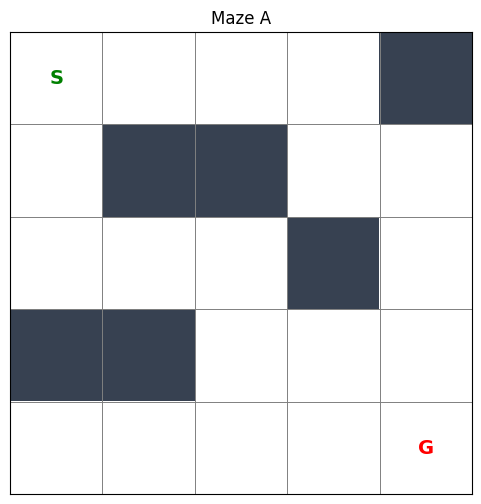

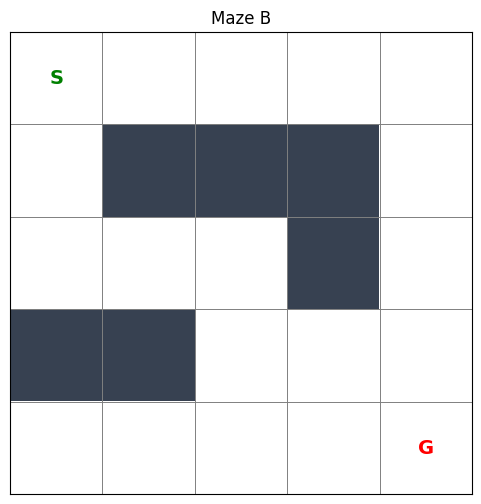

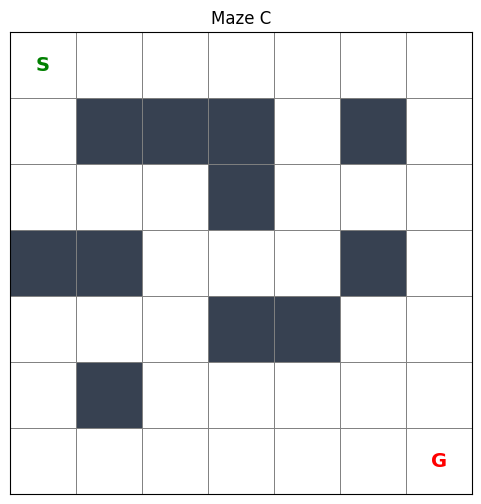

In [9]:
# Section 3.1: Dynamic maze visualization

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


def draw_maze(maze, path=None, title="Maze Environment"):
    rows = len(maze)
    cols = len(maze[0])

    grid = np.zeros((rows, cols), dtype=int)

    start = None
    goal = None

    for r in range(rows):
        for c in range(cols):
            if maze[r][c] == "#":
                grid[r, c] = 1
            elif maze[r][c] == "S":
                start = (r, c)
            elif maze[r][c] == "G":
                goal = (r, c)

    cmap = ListedColormap(["white", "#374151"])

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(grid, cmap=cmap, vmin=0, vmax=1)

    if path is not None and len(path) > 0:
        path_rows = [pos[0] for pos in path]
        path_cols = [pos[1] for pos in path]

        ax.plot(
            path_cols,
            path_rows,
            color="#2563eb",
            linewidth=2.5,
            marker="o",
            markersize=4,
            label="Path"
        )

    if start is not None:
        ax.text(
            start[1], start[0], "S",
            ha="center", va="center",
            color="green", fontsize=14,
            fontweight="bold"
        )

    if goal is not None:
        ax.text(
            goal[1], goal[0], "G",
            ha="center", va="center",
            color="red", fontsize=14,
            fontweight="bold"
        )

    ax.set_xticks(np.arange(-0.5, cols, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, rows, 1), minor=True)
    ax.grid(which="minor", color="gray", linewidth=0.7)

    ax.tick_params(
        which="both",
        bottom=False,
        left=False,
        labelbottom=False,
        labelleft=False
    )

    ax.set_title(title)
    ax.set_aspect("equal")

    if path is not None:
        ax.legend(loc="upper right")

    plt.show()


# Verify visualization for all three mazes
for name, layout in [
    ("Maze A", maze_A),
    ("Maze B", maze_B),
    ("Maze C", maze_C)
]:
    draw_maze(layout, title=name)

Position after moving DOWN: (1, 0)
Position after attempting RIGHT: (1, 0)
Reward for hitting wall: -5
WALL COLLISION TEST PASSED!


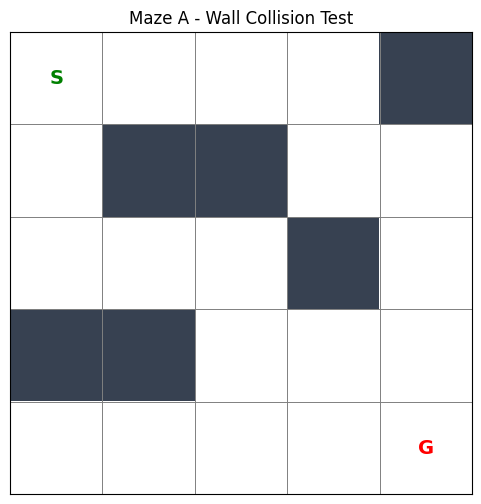

In [10]:

# Section 3.2: Verify wall collision behavior

# Create a fresh Maze A environment
env = MazeEnv(maze=maze_A)

# Reset agent to starting position (0, 0)
state, info = env.reset()

# Move DOWN to (1, 0)
state, reward, terminated, truncated, info = env.step(2)

print("Position after moving DOWN:", env.position)

# Try moving RIGHT into the wall at (1, 1)
state, reward, terminated, truncated, info = env.step(1)

print("Position after attempting RIGHT:", env.position)
print("Reward for hitting wall:", reward)

# Verify the wall collision
assert env.position == (1, 0), "Agent incorrectly moved through a wall!"
assert reward == -5, "Incorrect wall collision penalty!"

print("WALL COLLISION TEST PASSED!")

# Display the maze
draw_maze(env.maze, title="Maze A - Wall Collision Test")


Position: (1, 0) | Reward: -1
Position: (2, 0) | Reward: -1
Position: (2, 1) | Reward: -1
Position: (2, 2) | Reward: -1
Position: (3, 2) | Reward: -1
Position: (3, 3) | Reward: -1
Position: (3, 4) | Reward: -1
Position: (4, 4) | Reward: 100

Goal reached: True
Total reward: 93
Steps taken: 8
PREDEFINED ROUTE TEST PASSED!


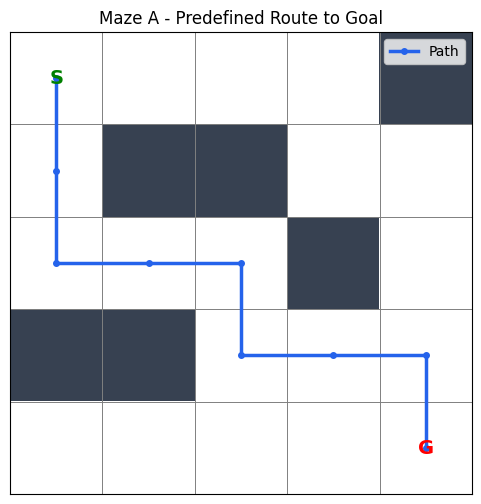

In [11]:

# Section 3.3: Verify a predefined route to the goal

env = MazeEnv(maze=maze_A, max_steps=100)
state, info = env.reset()

# 2 = DOWN, 1 = RIGHT
actions = [2, 2, 1, 1, 2, 1, 1, 2]

route = [env.position]
total_reward = 0
terminated = False
truncated = False

for action in actions:
    state, reward, terminated, truncated, info = env.step(action)

    route.append(env.position)
    total_reward += reward

    print("Position:", env.position, "| Reward:", reward)

    if terminated or truncated:
        break

print("\nGoal reached:", terminated)
print("Total reward:", total_reward)
print("Steps taken:", env.steps)

assert terminated, "The route did not reach the goal!"
assert not truncated, "The episode ended before reaching the goal!"
assert env.position == env.goal, "Final position is not the goal!"
assert env.steps == 8, "Expected an 8-step route!"

print("PREDEFINED ROUTE TEST PASSED!")

draw_maze(
    env.maze,
    path=route,
    title="Maze A - Predefined Route to Goal"
)


## 4. Q-learning training and greedy evaluation

In [12]:
# Section 4.1: One shared trainer for Q-learning and SARSA
# Every experiment below calls this function, so a fix here applies everywhere.

GAMMA = 0.95
EPS_START = 1.0
EPS_DECAY = 0.999      # per-episode multiplicative decay
EPS_MIN = 0.05
MAX_STEPS = 100
MAZES = {"Maze A": maze_A, "Maze B": maze_B, "Maze C": maze_C}
SEEDS = [10, 20, 30, 40, 50]


def train(
    maze,
    seed=10,
    episodes=2000,
    alpha=0.1,
    gamma=GAMMA,
    max_steps=MAX_STEPS,
    eps_decay=EPS_DECAY,
    callback=None,
    algorithm="q_learning",
    env_kwargs=None
):
    """Tabular Q-learning or SARSA with epsilon-greedy exploration.

    algorithm:  "q_learning" (off-policy, bootstraps from the best next action)
                "sarsa"      (on-policy, bootstraps from the next action actually taken)
    env_kwargs: extra MazeEnv arguments, e.g. {"wall_reward": -20}
    callback(episode, Q, epsilon) is called after every episode, which lets
    experiments evaluate checkpoints without copying the training loop.
    Returns Q and a per-episode history dictionary.
    """
    if algorithm not in ("q_learning", "sarsa"):
        raise ValueError(f"Unknown algorithm: {algorithm}")

    env = MazeEnv(maze=maze, max_steps=max_steps, **(env_kwargs or {}))
    Q = np.zeros((env.observation_space.n, env.action_space.n))
    rng = np.random.default_rng(seed)
    epsilon = EPS_START

    def choose(state):
        if rng.random() < epsilon:
            return int(rng.integers(env.action_space.n))
        return int(np.argmax(Q[state]))

    history = {k: [] for k in
               ["reward", "steps", "success", "wall_hits", "epsilon"]}

    for episode in range(1, episodes + 1):
        state, _ = env.reset()
        action = choose(state)
        done = False
        episode_reward = 0
        wall_hits = 0

        while not done:
            next_state, reward, terminated, truncated, info = env.step(action)
            done = terminated or truncated

            # SARSA must pick its next action BEFORE the update (it is part of the target).
            # Q-learning picks it AFTER the update, as in the standard algorithm:
            # this matters when a wall hit leaves the agent in the same state.
            next_action = None
            if algorithm == "sarsa" and not terminated:
                next_action = choose(next_state)

            # FIX: only a real terminal state has zero future value.
            # Hitting the step cap (truncation) is a time limit, not the end
            # of the task, so we still bootstrap from the next state.
            if terminated:
                next_value = 0.0
            elif algorithm == "q_learning":
                next_value = np.max(Q[next_state])
            else:
                next_value = Q[next_state, next_action]

            Q[state, action] += alpha * (
                reward + gamma * next_value - Q[state, action]
            )

            if algorithm == "q_learning" and not done:
                next_action = choose(next_state)

            state, action = next_state, next_action
            episode_reward += reward
            wall_hits += int(info["wall_hit"])

        history["reward"].append(episode_reward)
        history["steps"].append(env.steps)
        history["success"].append(int(terminated))
        history["wall_hits"].append(wall_hits)
        history["epsilon"].append(epsilon)

        epsilon = max(EPS_MIN, epsilon * eps_decay)

        if callback is not None:
            callback(episode, Q, epsilon)

    return Q, history


def train_q_learning(seed=42, episodes=2000, alpha=0.1, maze=None, max_steps=MAX_STEPS):
    """Backward-compatible wrapper used by the earlier cells."""
    Q, h = train(maze if maze is not None else maze_A, seed=seed,
                 episodes=episodes, alpha=alpha, max_steps=max_steps)
    return Q, h["reward"], h["success"]


print("Shared training function created!")

Shared training function created!


In [13]:

# Section 4.2: Verify Q-learning works with different mazes

for name, layout, expected_states in [
    ("Maze A", maze_A, 25),
    ("Maze B", maze_B, 25),
    ("Maze C", maze_C, 49)
]:
    Q, rewards, successes = train_q_learning(
        maze=layout,
        seed=10,
        episodes=10,
        alpha=0.1,
        max_steps=100
    )

    print(f"\n{name}")
    print("Q-table shape:", Q.shape)
    print("Training episodes:", len(rewards))
    print("Success records:", len(successes))

    assert Q.shape == (expected_states, 4)
    assert len(rewards) == 10
    assert len(successes) == 10
    assert np.isfinite(Q).all()

print("\nALL MULTI-MAZE TRAINING STRUCTURE TESTS PASSED!")



Maze A
Q-table shape: (25, 4)
Training episodes: 10
Success records: 10

Maze B
Q-table shape: (25, 4)
Training episodes: 10
Success records: 10

Maze C
Q-table shape: (49, 4)
Training episodes: 10
Success records: 10

ALL MULTI-MAZE TRAINING STRUCTURE TESTS PASSED!


In [14]:

# Section 4.3: Evaluate a trained Q-learning agent
# Supports different maze layouts and sizes

def evaluate_agent(Q, maze=None, max_steps=50):

    eval_env = MazeEnv(
        maze=maze,
        max_steps=max_steps
    )

    expected_shape = (
        eval_env.observation_space.n,
        eval_env.action_space.n
    )

    if Q.shape != expected_shape:
        raise ValueError(
            f"Q-table shape {Q.shape} does not match "
            f"environment shape {expected_shape}"
        )

    state, _ = eval_env.reset()

    route = [eval_env.position]
    total_reward = 0
    terminated = False
    truncated = False

    for step in range(max_steps):

        # Greedy evaluation: no random exploration
        action = int(np.argmax(Q[state]))

        next_state, reward, terminated, truncated, _ = (
            eval_env.step(action)
        )

        total_reward += reward
        route.append(eval_env.position)

        state = next_state

        if terminated or truncated:
            break

    return {
        "success": bool(terminated),
        "steps": len(route) - 1,
        "total_reward": total_reward,
        "route": route,
        "terminated": bool(terminated),
        "truncated": bool(truncated)
    }


print("Multi-maze evaluation function created!")


Multi-maze evaluation function created!


In [15]:

# Section 4.4: Train and evaluate on three mazes

for name, layout in [
    ("Maze A", maze_A),
    ("Maze B", maze_B),
    ("Maze C", maze_C)
]:

    Q, rewards, successes = train_q_learning(
        maze=layout,
        seed=10,
        episodes=2000,
        alpha=0.1,
        max_steps=100
    )

    evaluation = evaluate_agent(
        Q,
        maze=layout,
        max_steps=100
    )

    bfs_path = validate_maze_with_bfs(layout)
    shortest_steps = len(bfs_path) - 1

    print(f"\n{name}")
    print("Goal reached:", evaluation["success"])
    print("Agent steps:", evaluation["steps"])
    print("BFS shortest steps:", shortest_steps)
    print(
        "Optimal path:",
        evaluation["success"]
        and evaluation["steps"] == shortest_steps
    )
    print("Total reward:", evaluation["total_reward"])
    print("Agent route:", evaluation["route"])



Maze A
Goal reached: True
Agent steps: 8
BFS shortest steps: 8
Optimal path: True
Total reward: 93
Agent route: [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (3, 2), (4, 2), (4, 3), (4, 4)]

Maze B
Goal reached: True
Agent steps: 8
BFS shortest steps: 8
Optimal path: True
Total reward: 93
Agent route: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (3, 4), (4, 4)]

Maze C
Goal reached: True
Agent steps: 12
BFS shortest steps: 12
Optimal path: True
Total reward: 89
Agent route: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (2, 5), (2, 6), (3, 6), (4, 6), (5, 6), (6, 6)]


### Learned agent route (Q-learning, not a predefined path)

Maze: Maze A
Goal reached: True
Agent steps: 8
BFS shortest steps: 8
Total reward: 93
Optimal route: True
Learned route: [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (3, 2), (4, 2), (4, 3), (4, 4)]


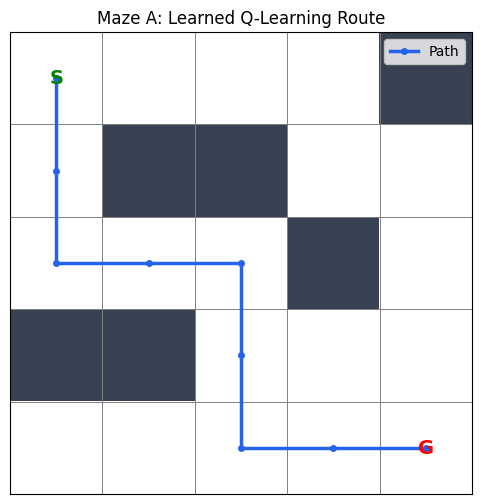

In [16]:
# Section 4.5: train a Q-learning agent and visualize its learned greedy route.
# This uses the configurable training/evaluation functions defined above.

maze_name = "Maze A"
layout = maze_A

Q_demo, demo_rewards, demo_successes = train_q_learning(
    seed=10, episodes=2000, alpha=0.1, maze=layout, max_steps=100
)
demo_eval = evaluate_agent(Q_demo, maze=layout, max_steps=100)
demo_bfs = validate_maze_with_bfs(layout)
demo_optimal_steps = len(demo_bfs) - 1

print("Maze:", maze_name)
print("Goal reached:", demo_eval["success"])
print("Agent steps:", demo_eval["steps"])
print("BFS shortest steps:", demo_optimal_steps)
print("Total reward:", demo_eval["total_reward"])
print("Optimal route:", demo_eval["success"] and demo_eval["steps"] == demo_optimal_steps)
print("Learned route:", demo_eval["route"])

assert demo_eval["success"], "Agent did not reach the goal."
assert demo_eval["steps"] == demo_optimal_steps, "Agent did not find a shortest path."

draw_maze(layout, path=demo_eval["route"], title=f"{maze_name}: Learned Q-Learning Route")

## 5. Ground truth: optimal Q-values by value iteration

Because the maze is small and deterministic, we can compute the exact optimal Q-values (Q*) by repeatedly applying the Bellman optimality equation over every state and action. This lets us measure **how close the learned Q-table is to the truth**, which is stronger evidence than "the greedy path happened to be optimal".

In [17]:
# Section 5.1: Value iteration for Q*

def transition(maze, position, action, env_kwargs=None):
    """Deterministic model taken directly from MazeEnv.step()."""
    env = MazeEnv(maze=maze, max_steps=10**9, **(env_kwargs or {}))
    env.reset()
    env.position = position
    state, reward, terminated, _, _ = env.step(action)
    return state, reward, terminated


def valid_states(maze):
    """Indices of open, non-goal cells (the states the agent acts in)."""
    n = len(maze)
    return [r * n + c for r in range(n) for c in range(n)
            if maze[r][c] not in ("#", "G")]


def value_iteration(maze, gamma=GAMMA, tol=1e-12, env_kwargs=None):
    n = len(maze)
    model = {}
    for s in valid_states(maze):
        for a in range(4):
            model[(s, a)] = transition(maze, (s // n, s % n), a, env_kwargs)

    Q = np.zeros((n * n, 4))
    while True:
        delta = 0.0
        for (s, a), (s2, r, term) in model.items():
            target = r + (0.0 if term else gamma * Q[s2].max())
            delta = max(delta, abs(target - Q[s, a]))
            Q[s, a] = target
        if delta < tol:
            return Q


def q_error(Q, Q_star, maze):
    """Max |Q - Q*| over all valid states and actions."""
    idx = valid_states(maze)
    return float(np.max(np.abs(Q[idx] - Q_star[idx])))


def route_value_error(Q, Q_star, maze):
    """Max |max_a Q - V*| over the cells of the BFS shortest route (excluding the goal).
    Unlike q_error, this ignores cells the agent never needs to visit."""
    n = len(maze)
    route = validate_maze_with_bfs(maze)[:-1]
    idx = [r * n + c for r, c in route]
    return float(np.max(np.abs(Q[idx].max(axis=1) - Q_star[idx].max(axis=1))))


def policy_agreement(Q, Q_star, maze, tol=1e-6):
    """Fraction of valid states whose greedy action is one of the optimal actions."""
    idx = valid_states(maze)
    agree = [Q_star[s, int(np.argmax(Q[s]))] >= Q_star[s].max() - tol for s in idx]
    return float(np.mean(agree))


Q_STAR = {name: value_iteration(layout) for name, layout in MAZES.items()}

for name, layout in MAZES.items():
    n = len(layout)
    print(f"{name}: Q*(start) [Up, Right, Down, Left] =",
          np.round(Q_STAR[name][0], 2))

# Hand check for Maze A (shortest path = 8 steps):
#   Right/Down from start: 7 steps of -1, then +100  -> 63.80
#   Up/Left from start:    -5 (wall), stay, then 63.80 discounted -> 55.61
g = GAMMA
hand_best = -sum(g**k for k in range(7)) + g**7 * 100
hand_wall = -5 + g * hand_best
print(f"\nHand calculation for Maze A: best = {hand_best:.2f}, wall = {hand_wall:.2f}")
assert abs(Q_STAR["Maze A"][0, 1] - hand_best) < 1e-6
assert abs(Q_STAR["Maze A"][0, 0] - hand_wall) < 1e-6
print("VALUE ITERATION MATCHES HAND CALCULATION!")

Maze A: Q*(start) [Up, Right, Down, Left] = [55.61 63.8  63.8  55.61]
Maze B: Q*(start) [Up, Right, Down, Left] = [55.61 63.8  63.8  55.61]
Maze C: Q*(start) [Up, Right, Down, Left] = [40.84 48.26 48.26 40.84]

Hand calculation for Maze A: best = 63.80, wall = 55.61
VALUE ITERATION MATCHES HAND CALCULATION!


In [18]:
# Section 5.2: Corrected Experiment C - learned start-state Q-values vs Q*
# (Maze A, 2,000 episodes, seed 10)

rows = []
for alpha in [0.01, 0.1, 0.5]:
    Q, _ = train(maze_A, seed=10, episodes=2000, alpha=alpha)
    rows.append({
        "Alpha": alpha,
        **dict(zip(["Up", "Right", "Down", "Left"], np.round(Q[0], 2))),
        "Max |Q - Q*| (all states)": round(q_error(Q, Q_STAR["Maze A"], maze_A), 3),
        "Policy agreement": round(policy_agreement(Q, Q_STAR["Maze A"], maze_A), 3),
    })
rows.append({"Alpha": "Q* (exact)",
             **dict(zip(["Up", "Right", "Down", "Left"], np.round(Q_STAR["Maze A"][0], 2))),
             "Max |Q - Q*| (all states)": 0.0, "Policy agreement": 1.0})

expC_df = pd.DataFrame(rows)
print("EXPERIMENT C (corrected): start-state Q-values after 2,000 episodes")
print(expC_df.to_string(index=False))

EXPERIMENT C (corrected): start-state Q-values after 2,000 episodes
     Alpha    Up  Right  Down  Left  Max |Q - Q*| (all states)  Policy agreement
      0.01 31.23  63.76 12.81 31.08                     83.035             0.944
       0.1 55.61  63.80 63.80 55.61                      3.153             1.000
       0.5 55.61  63.80 63.80 55.61                      0.000             1.000
Q* (exact) 55.61  63.80 63.80 55.61                      0.000             1.000


In [19]:
# Section 5.3: Re-check Experiment B - episode at which rolling training success reaches 90%

def first_episode_reaching(successes, threshold=0.9, window=100):
    rolling = pd.Series(successes).rolling(window).mean()
    hit = np.where(rolling >= threshold)[0]
    return int(hit[0]) + 1 if len(hit) else None


rows = []
for alpha in [0.01, 0.1, 0.5]:
    for seed in SEEDS:
        _, h = train(maze_A, seed=seed, episodes=2000, alpha=alpha)
        rows.append({"Alpha": alpha, "Seed": seed,
                     "Episode_90pct": first_episode_reaching(h["success"])})

expB_df = pd.DataFrame(rows)
print(expB_df.pivot(index="Seed", columns="Alpha", values="Episode_90pct").to_string())
print("\nMean episode reaching 90% rolling training success:")
print(expB_df.groupby("Alpha")["Episode_90pct"].mean().round(1).to_string())

Alpha  0.01  0.10  0.50
Seed                   
10      123   133   137
20      159   180   153
30      153   162   158
40      152   143   139
50      171   166   166

Mean episode reaching 90% rolling training success:
Alpha
0.01    151.6
0.10    156.8
0.50    150.6


**Why can different learning rates give the same answer here?** *Training* success counts episodes where the ε-greedy agent reaches the goal within 100 steps. Early on, ε is close to 1, so actions are almost random and α barely influences behaviour. If the numbers above are identical across α, the metric is measuring the exploration schedule, not the learning rate. Greedy-policy metrics and Q* error (above) are the right tools for comparing α.

## 6. Learning curves and learned policy

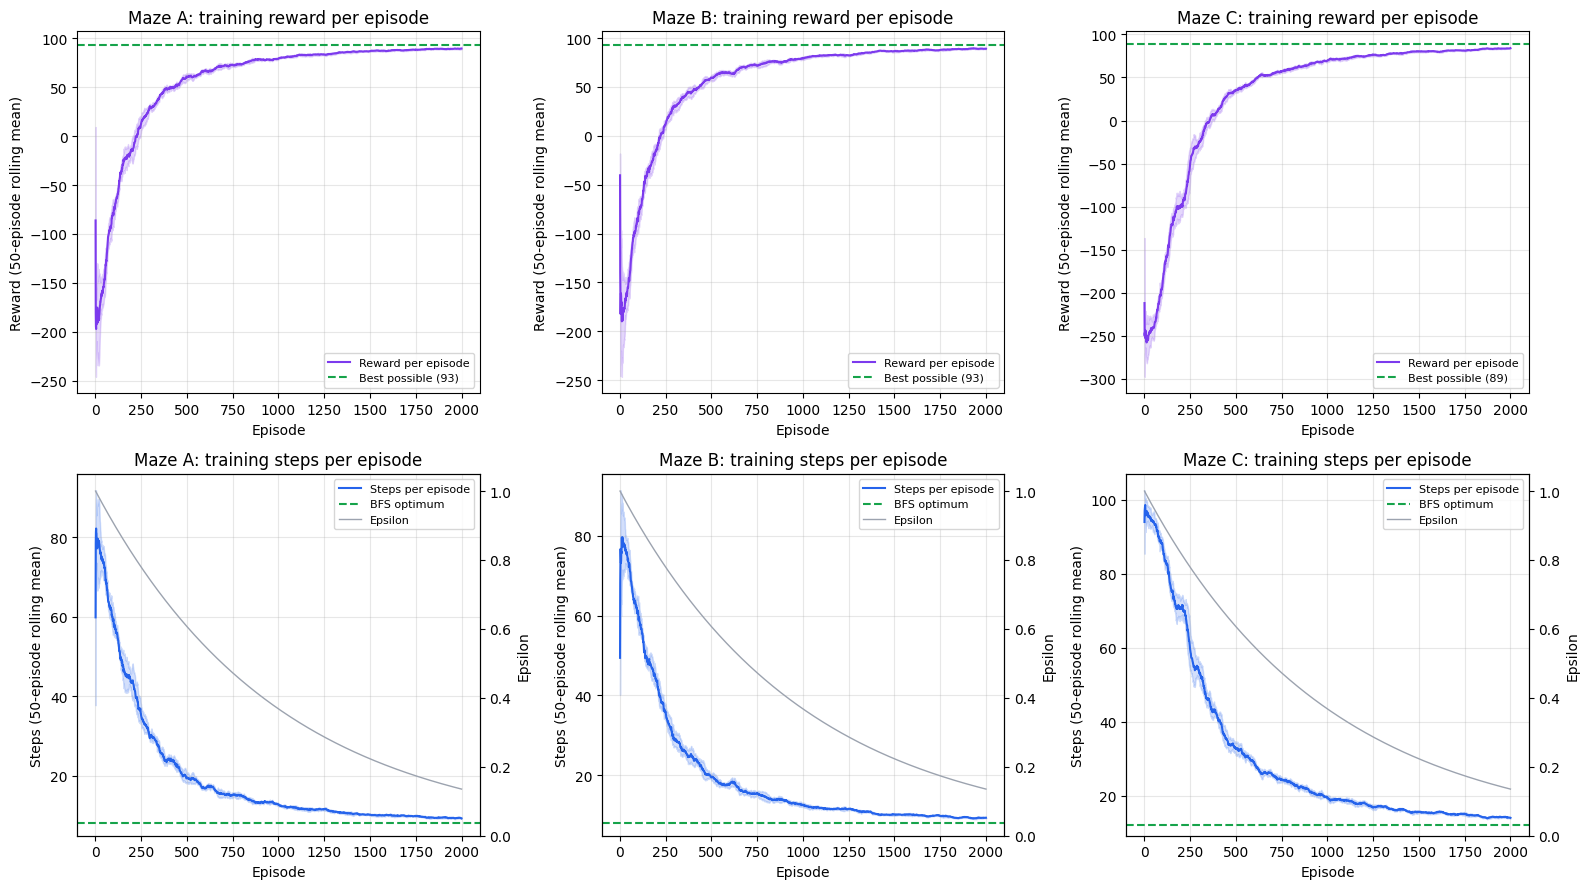

Note: training steps stay above the optimum because the agent still explores with probability epsilon (0.135 at episode 2,000). The greedy policy is evaluated separately.


In [20]:
# Section 6.1: Learning curves (mean +/- std over 5 seeds, alpha = 0.1)
# Top row: reward per episode. Bottom row: steps per episode.

window = 50
fig, all_axes = plt.subplots(2, 3, figsize=(16, 9))
curve_hist = {}

for ax_r, ax, (name, layout) in zip(all_axes[0], all_axes[1], MAZES.items()):
    runs = [train(layout, seed=s, episodes=2000, alpha=0.1)[1] for s in SEEDS]
    curve_hist[name] = runs

    rewards = np.array([pd.Series(h["reward"]).rolling(window, min_periods=1).mean() for h in runs])
    r_mean, r_std = rewards.mean(0), rewards.std(0)
    xr = np.arange(1, len(r_mean) + 1)
    best_reward = (len(validate_maze_with_bfs(layout)) - 2) * -1 + 100
    ax_r.plot(xr, r_mean, color="#7c3aed", label="Reward per episode")
    ax_r.fill_between(xr, r_mean - r_std, r_mean + r_std, color="#7c3aed", alpha=0.2)
    ax_r.axhline(best_reward, color="#16a34a", linestyle="--", label=f"Best possible ({best_reward})")
    ax_r.set_title(f"{name}: training reward per episode")
    ax_r.set_xlabel("Episode")
    ax_r.set_ylabel(f"Reward ({window}-episode rolling mean)")
    ax_r.grid(alpha=0.3)
    ax_r.legend(loc="lower right", fontsize=8)

    steps = np.array([pd.Series(h["steps"]).rolling(window, min_periods=1).mean() for h in runs])
    mean, std = steps.mean(0), steps.std(0)
    x = np.arange(1, len(mean) + 1)

    ax.plot(x, mean, color="#2563eb", label="Steps per episode")
    ax.fill_between(x, mean - std, mean + std, color="#2563eb", alpha=0.2)
    ax.axhline(len(validate_maze_with_bfs(layout)) - 1, color="#16a34a",
               linestyle="--", label="BFS optimum")
    ax.set_title(f"{name}: training steps per episode")
    ax.set_xlabel("Episode")
    ax.set_ylabel(f"Steps ({window}-episode rolling mean)")
    ax.grid(alpha=0.3)

    ax2 = ax.twinx()
    ax2.plot(x, runs[0]["epsilon"], color="#9ca3af", linewidth=1, label="Epsilon")
    ax2.set_ylim(0, 1.05)
    ax2.set_ylabel("Epsilon")

    lines = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
    labels = ax.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
    ax.legend(lines, labels, loc="upper right", fontsize=8)

plt.tight_layout()
plt.show()

print("Note: training steps stay above the optimum because the agent still explores "
      "with probability epsilon (0.135 at episode 2,000). The greedy policy is evaluated separately.")

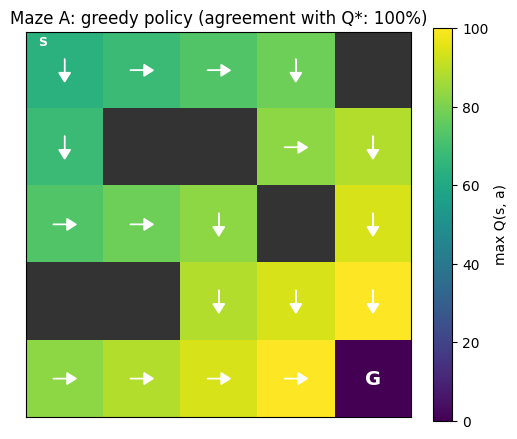

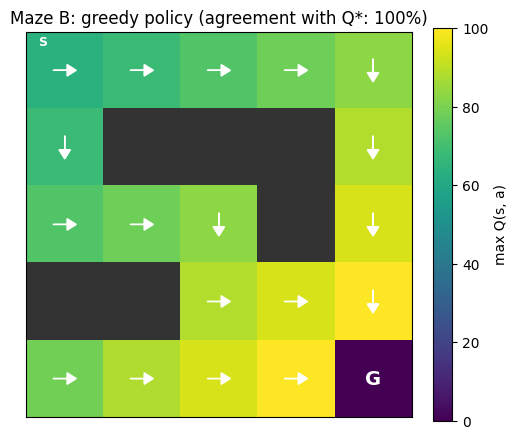

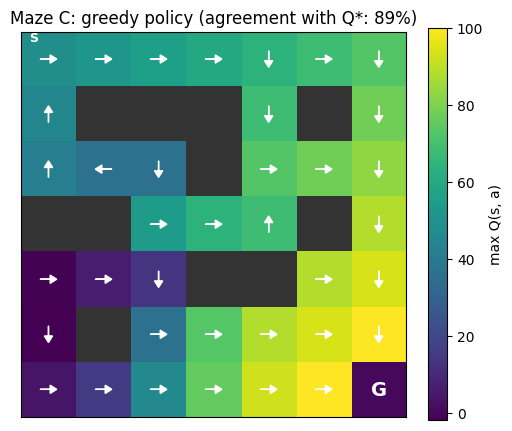

In [21]:
# Section 6.2: Policy-arrow map over a heatmap of max Q

def draw_policy(maze, Q, title):
    n = len(maze)
    V = np.full((n, n), np.nan)
    for r in range(n):
        for c in range(n):
            if maze[r][c] != "#":
                V[r, c] = Q[r * n + c].max()

    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    im = ax.imshow(V, cmap="viridis")
    ax.imshow(np.where([[ch == "#" for ch in row] for row in maze], 1.0, np.nan),
              cmap="Greys", vmin=0, vmax=1.2)
    arrows = {0: (0, -0.3), 1: (0.3, 0), 2: (0, 0.3), 3: (-0.3, 0)}

    for r in range(n):
        for c in range(n):
            ch = maze[r][c]
            if ch == "#":
                continue
            if ch == "G":
                ax.text(c, r, "G", ha="center", va="center", color="white",
                        fontsize=14, fontweight="bold")
                continue
            dx, dy = arrows[int(np.argmax(Q[r * n + c]))]
            ax.arrow(c - dx / 2, r - dy / 2, dx, dy, head_width=0.15,
                     head_length=0.12, color="white", length_includes_head=True)
            if ch == "S":
                ax.text(c - 0.35, r - 0.32, "S", color="white", fontsize=9, fontweight="bold")

    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.046, label="max Q(s, a)")
    plt.show()


for name, layout in MAZES.items():
    Q, _ = train(layout, seed=10, episodes=2000, alpha=0.1)
    agree = policy_agreement(Q, Q_STAR[name], layout)
    draw_policy(layout, Q, f"{name}: greedy policy (agreement with Q*: {agree:.0%})")

## 7. Multi-seed and learning-rate experiments

In [22]:

# Section 7.1: Multi-maze evaluation across random seeds

import pandas as pd
import numpy as np

experiment_seeds = [10, 20, 30, 40, 50]

results = []

for maze_name, layout in [
    ("Maze A", maze_A),
    ("Maze B", maze_B),
    ("Maze C", maze_C)
]:
    bfs_path = validate_maze_with_bfs(layout)
    shortest_steps = len(bfs_path) - 1

    for seed in experiment_seeds:

        Q, rewards, successes = train_q_learning(
            maze=layout,
            seed=seed,
            episodes=2000,
            alpha=0.1,
            max_steps=100
        )

        evaluation = evaluate_agent(
            Q,
            maze=layout,
            max_steps=100
        )

        optimal = (
            evaluation["success"]
            and evaluation["steps"] == shortest_steps
        )

        results.append({
            "Maze": maze_name,
            "Seed": seed,
            "Success": evaluation["success"],
            "Agent Steps": evaluation["steps"],
            "BFS Steps": shortest_steps,
            "Optimal": optimal,
            "Total Reward": evaluation["total_reward"]
        })


# Detailed results
results_df = pd.DataFrame(results)

print("DETAILED RESULTS")
print(results_df.to_string(index=False))


# Summary by maze
summary_df = results_df.groupby("Maze").agg(
    Runs=("Seed", "count"),
    Success_Rate=("Success", "mean"),
    Optimal_Path_Rate=("Optimal", "mean"),
    Mean_Agent_Steps=("Agent Steps", "mean"),
    Mean_Reward=("Total Reward", "mean")
).reset_index()

summary_df["Success_Rate"] *= 100
summary_df["Optimal_Path_Rate"] *= 100

print("\nSUMMARY BY MAZE")
print(summary_df.round(2).to_string(index=False))


DETAILED RESULTS
  Maze  Seed  Success  Agent Steps  BFS Steps  Optimal  Total Reward
Maze A    10     True            8          8     True            93
Maze A    20     True            8          8     True            93
Maze A    30     True            8          8     True            93
Maze A    40     True            8          8     True            93
Maze A    50     True            8          8     True            93
Maze B    10     True            8          8     True            93
Maze B    20     True            8          8     True            93
Maze B    30     True            8          8     True            93
Maze B    40     True            8          8     True            93
Maze B    50     True            8          8     True            93
Maze C    10     True           12         12     True            89
Maze C    20     True           12         12     True            89
Maze C    30     True           12         12     True            89
Maze C    40     

In [23]:
# Section 7.2: Checkpoint experiment
# Each run trains ONE agent and evaluates it at several checkpoints.
# (The old Step 7A trained separate agents for each duration. With the same seed,
#  those agents are identical to the checkpoints here, so 7A was removed.)

checkpoints = [25, 50, 100, 200, 500, 1000, 2000]   # early-stage focus: 25-200
learning_rates = [0.01, 0.1, 0.5]

checkpoint_records = []

for maze_name, layout in MAZES.items():
    shortest_steps = len(validate_maze_with_bfs(layout)) - 1

    for alpha in learning_rates:
        for seed in SEEDS:

            def record(episode, Q, epsilon):
                if episode not in checkpoints:
                    return
                ev = evaluate_agent(Q, maze=layout, max_steps=MAX_STEPS)
                checkpoint_records.append({
                    "Maze": maze_name, "Alpha": alpha, "Seed": seed,
                    "Episodes": episode,
                    "Epsilon": epsilon,
                    "Success": int(ev["success"]),
                    "Optimal": int(ev["success"] and ev["steps"] == shortest_steps),
                    "Steps": ev["steps"],
                    "Q_Error": q_error(Q, Q_STAR[maze_name], layout),
                    "Policy_Agreement": policy_agreement(Q, Q_STAR[maze_name], layout),
                })

            train(layout, seed=seed, episodes=max(checkpoints), alpha=alpha, callback=record)

checkpoint_df = pd.DataFrame(checkpoint_records)

checkpoint_summary = checkpoint_df.groupby(["Maze", "Alpha", "Episodes"]).agg(
    Runs=("Seed", "count"),
    Epsilon=("Epsilon", "mean"),
    Success_Rate=("Success", "mean"),
    Optimal_Rate=("Optimal", "mean"),
    Mean_Steps=("Steps", "mean"),
    Mean_Q_Error=("Q_Error", "mean"),
    Policy_Agreement=("Policy_Agreement", "mean"),
).reset_index()

checkpoint_summary["Success_Rate"] *= 100
checkpoint_summary["Optimal_Rate"] *= 100
checkpoint_summary["Policy_Agreement"] *= 100

print("Independent training runs:", 3 * len(learning_rates) * len(SEEDS))
print("Checkpoint evaluations:", len(checkpoint_df))
print("\nCHECKPOINT RESULTS:")
print(checkpoint_summary.round(3).to_string(index=False))

Independent training runs: 45
Checkpoint evaluations: 315

CHECKPOINT RESULTS:
  Maze  Alpha  Episodes  Runs  Epsilon  Success_Rate  Optimal_Rate  Mean_Steps  Mean_Q_Error  Policy_Agreement
Maze A   0.01        25     5    0.975           0.0           0.0       100.0        94.913            81.111
Maze A   0.01        50     5    0.951          40.0          40.0        63.2        93.468            90.000
Maze A   0.01       100     5    0.905         100.0         100.0         8.0        90.750           100.000
Maze A   0.01       200     5    0.819         100.0         100.0         8.0        87.147           100.000
Maze A   0.01       500     5    0.606         100.0         100.0         8.0        84.453            98.889
Maze A   0.01      1000     5    0.368         100.0         100.0         8.0        83.666            95.556
Maze A   0.01      2000     5    0.135         100.0         100.0         8.0        83.666            95.556
Maze A   0.10        25     5    

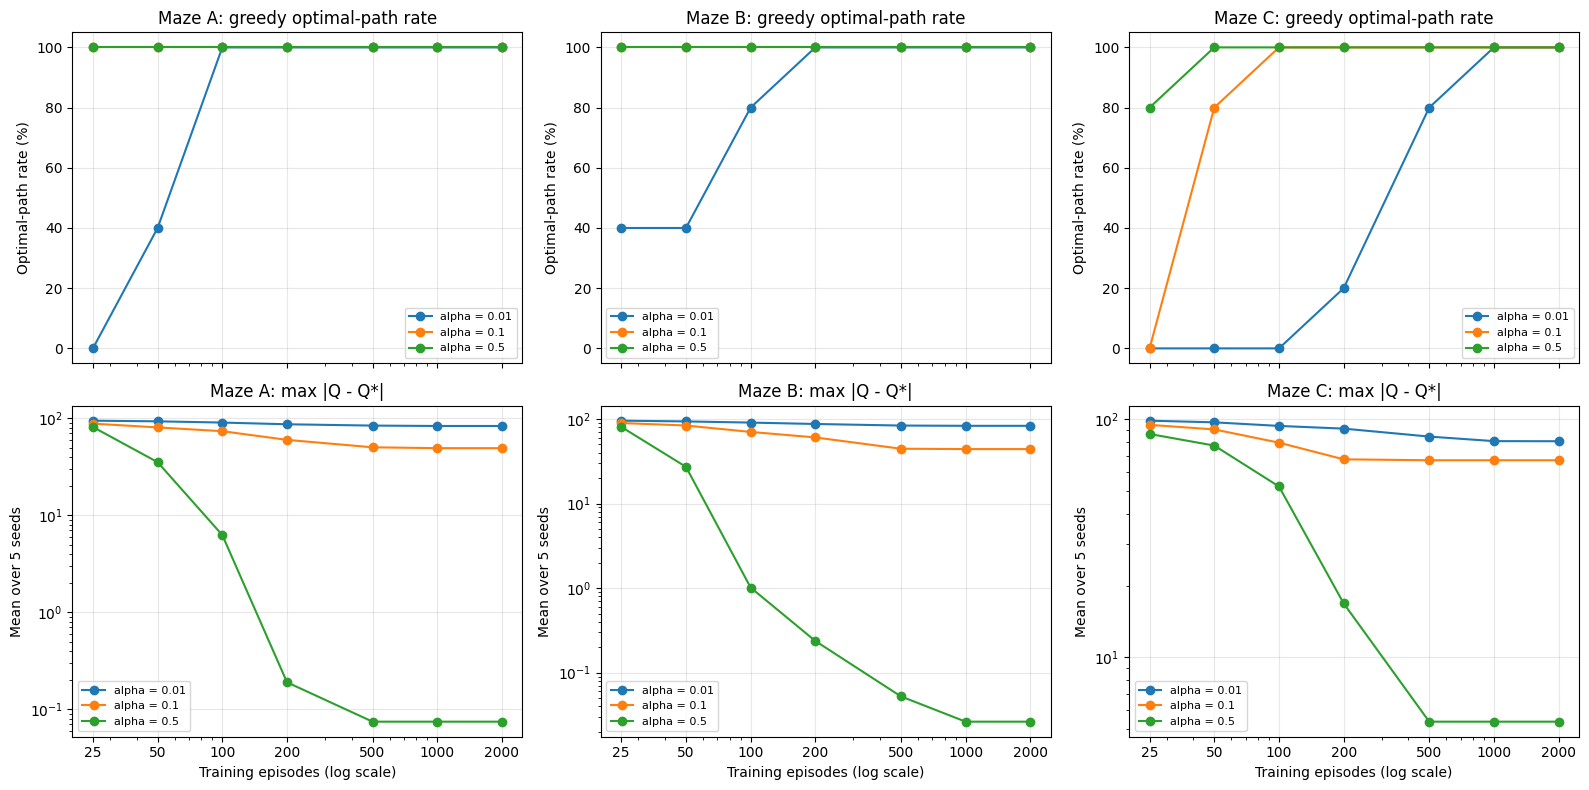

In [24]:
# Section 7.3: Optimal-path rate and Q* error across checkpoints

fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)

for col, maze_name in enumerate(MAZES):
    maze_data = checkpoint_summary[checkpoint_summary["Maze"] == maze_name]
    for alpha in learning_rates:
        d = maze_data[maze_data["Alpha"] == alpha].sort_values("Episodes")
        axes[0, col].plot(d["Episodes"], d["Optimal_Rate"], marker="o", label=f"alpha = {alpha}")
        axes[1, col].plot(d["Episodes"], d["Mean_Q_Error"], marker="o", label=f"alpha = {alpha}")

    axes[0, col].set_title(f"{maze_name}: greedy optimal-path rate")
    axes[0, col].set_ylabel("Optimal-path rate (%)")
    axes[0, col].set_ylim(-5, 105)
    axes[1, col].set_title(f"{maze_name}: max |Q - Q*|")
    axes[1, col].set_ylabel("Mean over 5 seeds")
    axes[1, col].set_yscale("log")
    axes[1, col].set_xlabel("Training episodes (log scale)")
    for r in range(2):
        axes[r, col].set_xscale("log")
        axes[r, col].set_xticks(checkpoints)
        axes[r, col].set_xticklabels(checkpoints)
        axes[r, col].grid(alpha=0.3)
        axes[r, col].legend(fontsize=8)

plt.tight_layout()
plt.show()

In [25]:
# Section 7.4: Early-stage learning analysis (25, 50, 100, 200 and 2,000 episodes)
# Greedy optimal-path rate (%) across 5 seeds; same agents evaluated at each checkpoint.

early = [25, 50, 100, 200, 2000]
early_table = (checkpoint_summary[checkpoint_summary["Episodes"].isin(early)]
               .pivot_table(index=["Maze", "Alpha"], columns="Episodes", values="Optimal_Rate"))
print("GREEDY OPTIMAL-PATH RATE (%) BY TRAINING EPISODES")
print(early_table.round(0).to_string())

eps_at = checkpoint_summary.groupby("Episodes")["Epsilon"].first()
print("\nEpsilon at each checkpoint:", {int(k): round(v, 3) for k, v in eps_at.items() if k in early})

GREEDY OPTIMAL-PATH RATE (%) BY TRAINING EPISODES
Episodes       25     50     100    200    2000
Maze   Alpha                                   
Maze A 0.01     0.0   40.0  100.0  100.0  100.0
       0.10   100.0  100.0  100.0  100.0  100.0
       0.50   100.0  100.0  100.0  100.0  100.0
Maze B 0.01    40.0   40.0   80.0  100.0  100.0
       0.10   100.0  100.0  100.0  100.0  100.0
       0.50   100.0  100.0  100.0  100.0  100.0
Maze C 0.01     0.0    0.0    0.0   20.0  100.0
       0.10     0.0   80.0  100.0  100.0  100.0
       0.50    80.0  100.0  100.0  100.0  100.0

Epsilon at each checkpoint: {25: 0.975, 50: 0.951, 100: 0.905, 200: 0.819, 2000: 0.135}


In [26]:
# Section 7.5: Inspect individual agent performance across checkpoints

# Focus on Maze C with learning rate alpha = 0.5
selected = checkpoint_df[
    (checkpoint_df["Maze"] == "Maze C")
    & (checkpoint_df["Alpha"] == 0.5)
]

# Show whether each seed found an optimal path at each checkpoint
optimal_by_seed = selected.pivot(
    index="Seed",
    columns="Episodes",
    values="Optimal"
)

print("MAZE C - ALPHA = 0.5")
print("1 = Optimal path, 0 = Not optimal")
print(optimal_by_seed.to_string())

# Compare episode 50 with episode 100
print("\nCHANGES FROM EPISODE 50 TO 100")

for seed, row in optimal_by_seed.iterrows():
    before = int(row[50])
    after = int(row[100])

    if before == 1 and after == 0:
        status = "Lost optimal-path performance"
    elif before == 0 and after == 1:
        status = "Gained optimal-path performance"
    elif before == 1 and after == 1:
        status = "Remained optimal"
    else:
        status = "Remained non-optimal"

    print(f"Seed {seed}: {status}")

print("\nCHECKPOINT DIAGNOSTIC COMPLETE!")

MAZE C - ALPHA = 0.5
1 = Optimal path, 0 = Not optimal
Episodes  25    50    100   200   500   1000  2000
Seed                                              
10           0     1     1     1     1     1     1
20           1     1     1     1     1     1     1
30           1     1     1     1     1     1     1
40           1     1     1     1     1     1     1
50           1     1     1     1     1     1     1

CHANGES FROM EPISODE 50 TO 100
Seed 10: Remained optimal
Seed 20: Remained optimal
Seed 30: Remained optimal
Seed 40: Remained optimal
Seed 50: Remained optimal

CHECKPOINT DIAGNOSTIC COMPLETE!


In [27]:
# Section 7.6: Epsilon-schedule control experiment
# Problem: with decay 0.999 per episode, epsilon is still 0.95 at 50 episodes and
# 0.61 at 500. So "more episodes" also means "less exploration": the two are confounded.
# Control: for each budget N, decay epsilon so it reaches the 0.05 floor exactly at episode N.

budgets = [50, 100, 250, 500]
rows = []
for budget in budgets:
    fitted_decay = EPS_MIN ** (1 / budget)
    for alpha in learning_rates:
        for seed in SEEDS:
            for schedule, decay in [("Fixed 0.999", EPS_DECAY), ("Fitted to budget", fitted_decay)]:
                Q, h = train(maze_C, seed=seed, episodes=budget, alpha=alpha, eps_decay=decay)
                ev = evaluate_agent(Q, maze=maze_C, max_steps=MAX_STEPS)
                rows.append({
                    "Budget": budget, "Alpha": alpha, "Schedule": schedule,
                    "Final_Epsilon": h["epsilon"][-1],
                    "Optimal": int(ev["success"] and ev["steps"] == len(validate_maze_with_bfs(maze_C)) - 1),
                    "Q_Error": q_error(Q, Q_STAR["Maze C"], maze_C),
                })

eps_df = pd.DataFrame(rows)
eps_summary = eps_df.groupby(["Schedule", "Budget"]).agg(
    Final_Epsilon=("Final_Epsilon", "mean"),
    Optimal_Rate=("Optimal", "mean"),
    Mean_Q_Error=("Q_Error", "mean"),
).reset_index()
eps_summary["Optimal_Rate"] *= 100

print("MAZE C: fixed vs budget-fitted epsilon schedule (3 alphas x 5 seeds per cell)")
print(eps_summary.round(3).to_string(index=False))

MAZE C: fixed vs budget-fitted epsilon schedule (3 alphas x 5 seeds per cell)
        Schedule  Budget  Final_Epsilon  Optimal_Rate  Mean_Q_Error
Fitted to budget      50          0.053        33.333        94.700
Fitted to budget     100          0.052        66.667        91.396
Fitted to budget     250          0.051        66.667        86.526
Fitted to budget     500          0.050        73.333        80.707
     Fixed 0.999      50          0.952        60.000        88.378
     Fixed 0.999     100          0.906        66.667        75.204
     Fixed 0.999     250          0.779        80.000        55.958
     Fixed 0.999     500          0.607        93.333        52.381


## 8. Route validity and convergence analysis

In [28]:
# Section 8.1: Validate Q-learning routes against BFS

def validate_agent_route(route, maze, success):
    env = MazeEnv(maze=maze)

    if not route:
        return {
            "valid": False,
            "optimal": False,
            "reason": "Empty route"
        }

    if route[0] != env.start:
        return {
            "valid": False,
            "optimal": False,
            "reason": "Route does not start at S"
        }

    for position in route:
        row, col = position

        if not (
            0 <= row < env.size
            and 0 <= col < env.size
        ):
            return {
                "valid": False,
                "optimal": False,
                "reason": "Route leaves maze boundaries"
            }

        if env.maze[row][col] == "#":
            return {
                "valid": False,
                "optimal": False,
                "reason": "Route enters a wall"
            }

    for current, next_position in zip(route, route[1:]):
        distance = (
            abs(current[0] - next_position[0])
            + abs(current[1] - next_position[1])
        )

        # Distance 0 is allowed for blocked actions
        if distance not in (0, 1):
            return {
                "valid": False,
                "optimal": False,
                "reason": "Invalid movement between cells"
            }

    reached_goal = route[-1] == env.goal

    if bool(success) != reached_goal:
        return {
            "valid": False,
            "optimal": False,
            "reason": "Success flag does not match final position"
        }

    shortest_path = validate_maze_with_bfs(maze)
    shortest_steps = len(shortest_path) - 1

    optimal = (
        reached_goal
        and len(route) - 1 == shortest_steps
    )

    return {
        "valid": True,
        "optimal": optimal,
        "reason": "Route verified",
        "agent_steps": len(route) - 1,
        "bfs_steps": shortest_steps
    }


# Test the validator on all three mazes
for name, layout in [
    ("Maze A", maze_A),
    ("Maze B", maze_B),
    ("Maze C", maze_C)
]:
    Q, _, _ = train_q_learning(
        maze=layout,
        seed=10,
        episodes=2000,
        alpha=0.1,
        max_steps=100
    )

    evaluation = evaluate_agent(
        Q,
        maze=layout,
        max_steps=100
    )

    validation = validate_agent_route(
        route=evaluation["route"],
        maze=layout,
        success=evaluation["success"]
    )

    print(f"\n{name}")
    print("Route valid:", validation["valid"])
    print("Optimal path:", validation["optimal"])
    print("Reason:", validation["reason"])
    print("Agent steps:", validation.get("agent_steps"))
    print("BFS steps:", validation.get("bfs_steps"))

    assert validation["valid"]
    assert validation["optimal"]

print("\nALL ROUTE VALIDATION TESTS PASSED!")


Maze A
Route valid: True
Optimal path: True
Reason: Route verified
Agent steps: 8
BFS steps: 8

Maze B
Route valid: True
Optimal path: True
Reason: Route verified
Agent steps: 8
BFS steps: 8

Maze C
Route valid: True
Optimal path: True
Reason: Route verified
Agent steps: 12
BFS steps: 12

ALL ROUTE VALIDATION TESTS PASSED!


In [29]:
# Section 8.2: Find earliest checkpoint with 100% optimal-path rate

import pandas as pd

convergence_records = []

for maze_name in ["Maze A", "Maze B", "Maze C"]:
    for alpha in [0.01, 0.1, 0.5]:

        subset = checkpoint_summary[
            (checkpoint_summary["Maze"] == maze_name)
            & (checkpoint_summary["Alpha"] == alpha)
        ].sort_values("Episodes")

        perfect_checkpoints = subset[
            subset["Optimal_Rate"] == 100.0
        ]

        if perfect_checkpoints.empty:
            first_perfect = None
        else:
            first_perfect = int(
                perfect_checkpoints.iloc[0]["Episodes"]
            )

        convergence_records.append({
            "Maze": maze_name,
            "Alpha": alpha,
            "First_100pct_Checkpoint": first_perfect,
            "Final_Optimal_Rate": float(
                subset.iloc[-1]["Optimal_Rate"]
            )
        })

convergence_table = pd.DataFrame(convergence_records)

print("POLICY PERFORMANCE THRESHOLD ANALYSIS")
print(convergence_table.to_string(index=False))

print("\nNOTE:")
print("This identifies the first measured checkpoint with")
print("100% optimal-path rate across five seeds.")
print("It does NOT prove mathematical Q-value convergence.")

POLICY PERFORMANCE THRESHOLD ANALYSIS
  Maze  Alpha  First_100pct_Checkpoint  Final_Optimal_Rate
Maze A   0.01                      100               100.0
Maze A   0.10                       25               100.0
Maze A   0.50                       25               100.0
Maze B   0.01                      200               100.0
Maze B   0.10                       25               100.0
Maze B   0.50                       25               100.0
Maze C   0.01                     1000               100.0
Maze C   0.10                      100               100.0
Maze C   0.50                       50               100.0

NOTE:
This identifies the first measured checkpoint with
100% optimal-path rate across five seeds.
It does NOT prove mathematical Q-value convergence.


 Episode  Max_Q_Change  Q_Error  Greedy_Optimal  Rolling_Max_Q_Change
      25        1.5935  94.3439               0                2.6039
      50        0.2719  90.2875               0                2.2000
     100       10.3196  80.6242               1                2.9950
     200        8.5273  73.8473               1                4.9839
     500        0.0000  72.8653               1                0.1734
    1000        0.0000  72.8653               1                0.0018
    2000        0.0000  72.8653               1                0.0001


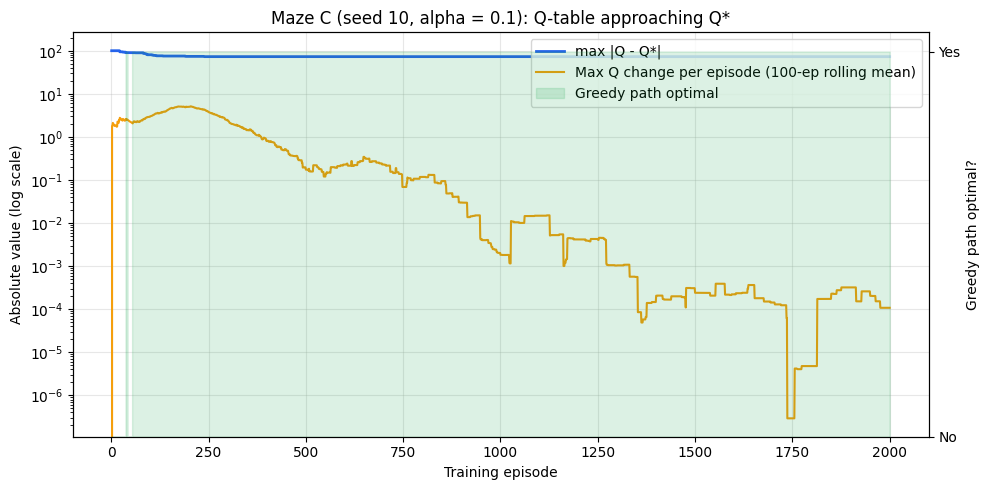

First episode with optimal greedy path: 37
max |Q - Q*| at that point: 90.29
max |Q - Q*| at episode 2,000: 72.8653


In [30]:
# Section 8.3: Episode-by-episode stability and distance from Q*
# (Replaces old Steps 9B/9C; 9B compared checkpoints at unequal intervals.)

shortest_C = len(validate_maze_with_bfs(maze_C)) - 1
records = []
prev = {"Q": None}

def per_episode(episode, Q, epsilon):
    change = 0.0 if prev["Q"] is None else float(np.max(np.abs(Q - prev["Q"])))
    prev["Q"] = Q.copy()
    ev = evaluate_agent(Q, maze=maze_C, max_steps=MAX_STEPS)
    records.append({
        "Episode": episode,
        "Max_Q_Change": change,
        "Q_Error": q_error(Q, Q_STAR["Maze C"], maze_C),
        "Greedy_Optimal": int(ev["success"] and ev["steps"] == shortest_C),
    })

train(maze_C, seed=10, episodes=2000, alpha=0.1, callback=per_episode)
episode_stability_df = pd.DataFrame(records)
episode_stability_df["Rolling_Max_Q_Change"] = (
    episode_stability_df["Max_Q_Change"].rolling(100, min_periods=1).mean())

print(episode_stability_df[episode_stability_df["Episode"].isin(checkpoints)]
      .round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(episode_stability_df["Episode"], episode_stability_df["Q_Error"],
        label="max |Q - Q*|", color="#2563eb", linewidth=2)
ax.plot(episode_stability_df["Episode"], episode_stability_df["Rolling_Max_Q_Change"],
        label="Max Q change per episode (100-ep rolling mean)", color="#f59e0b")
ax.set_yscale("log")
ax.set_xlabel("Training episode")
ax.set_ylabel("Absolute value (log scale)")
ax.set_title("Maze C (seed 10, alpha = 0.1): Q-table approaching Q*")
ax.grid(alpha=0.3)

ax2 = ax.twinx()
ax2.fill_between(episode_stability_df["Episode"], 0, episode_stability_df["Greedy_Optimal"],
                 step="mid", color="#16a34a", alpha=0.15, label="Greedy path optimal")
ax2.set_ylim(0, 1.05)
ax2.set_yticks([0, 1])
ax2.set_yticklabels(["No", "Yes"])
ax2.set_ylabel("Greedy path optimal?")

lines = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax.legend(lines, labels, loc="upper right")
plt.tight_layout()
plt.show()

first_opt = episode_stability_df.loc[episode_stability_df["Greedy_Optimal"] == 1, "Episode"].min()
print(f"First episode with optimal greedy path: {first_opt}")
print(f"max |Q - Q*| at that point: "
      f"{episode_stability_df.loc[episode_stability_df['Episode'] == first_opt, 'Q_Error'].item():.2f}")
print(f"max |Q - Q*| at episode 2,000: {episode_stability_df['Q_Error'].iloc[-1]:.4f}")

**Key point:** the greedy path becomes optimal long before the Q-table matches Q*. A correct route only requires the *ranking* of actions along one path to be right, not the values everywhere.

**Why does the error stop falling at about 72.9?** The largest errors are all in the bottom-left pocket of Maze C (rows 4–6, columns 0–2), which is off the optimal route. Once ε is low, the agent almost never wanders into that pocket, so those Q-values are never corrected. Meanwhile the states on the route have converged, which is why the per-episode Q change falls to near zero (below 0.001 by about episode 1,350). This is a known limitation of ε-greedy exploration: Q-learning only converges for state–action pairs it keeps visiting (Watkins & Dayan, 1992).

## 9. Comparison with classical pathfinding: BFS, A* and flood fill

These algorithms answer different questions, so they are compared on what each one needs and what it costs:

- **BFS** and **A\*** plan on a **fully known map**. Cost = nodes expanded.
- **Online flood fill** (the micromouse algorithm) starts with **no map**, assumes every unknown cell is open, and recomputes a distance-to-goal field whenever it bumps into a wall. Cost = moves in the real maze.
- **Q-learning** also starts with **no map**, but uses no knowledge of grid geometry at all. Cost = moves in the real maze.

In [31]:
# Section 9.1: BFS with node counting, and A* with a Manhattan heuristic

DIRS = [(-1, 0), (0, 1), (1, 0), (0, -1)]   # Up, Right, Down, Left (same as MazeEnv)


def find_cell(maze, symbol):
    for r, row in enumerate(maze):
        for c, ch in enumerate(row):
            if ch == symbol:
                return (r, c)


def open_cell(maze, r, c):
    return 0 <= r < len(maze) and 0 <= c < len(maze[0]) and maze[r][c] != "#"


def bfs_counted(maze):
    start, goal = find_cell(maze, "S"), find_cell(maze, "G")
    parent = {start: None}
    queue = deque([start])
    expanded = 0
    while queue:
        cell = queue.popleft()
        expanded += 1
        if cell == goal:
            break
        for dr, dc in DIRS:
            nxt = (cell[0] + dr, cell[1] + dc)
            if open_cell(maze, *nxt) and nxt not in parent:
                parent[nxt] = cell
                queue.append(nxt)
    path, cell = [], goal
    while cell is not None:
        path.append(cell); cell = parent[cell]
    return path[::-1], expanded


def astar(maze):
    start, goal = find_cell(maze, "S"), find_cell(maze, "G")
    h = lambda p: abs(p[0] - goal[0]) + abs(p[1] - goal[1])   # admissible on a 4-connected grid
    g = {start: 0}
    parent = {start: None}
    heap = [(h(start), 0, start)]
    closed = set()
    expanded = 0
    while heap:
        _, cost, cell = heapq.heappop(heap)
        if cell in closed:
            continue
        closed.add(cell)
        expanded += 1
        if cell == goal:
            break
        for dr, dc in DIRS:
            nxt = (cell[0] + dr, cell[1] + dc)
            if open_cell(maze, *nxt) and cost + 1 < g.get(nxt, float("inf")):
                g[nxt] = cost + 1
                parent[nxt] = cell
                heapq.heappush(heap, (cost + 1 + h(nxt), cost + 1, nxt))
    path, cell = [], goal
    while cell is not None:
        path.append(cell); cell = parent[cell]
    return path[::-1], expanded


for name, layout in MAZES.items():
    bfs_path, bfs_exp = bfs_counted(layout)
    a_path, a_exp = astar(layout)
    assert len(bfs_path) == len(validate_maze_with_bfs(layout))
    assert len(a_path) == len(bfs_path), "A* must also be optimal"
    print(f"{name}: BFS {len(bfs_path) - 1} steps, {bfs_exp} nodes expanded | "
          f"A* {len(a_path) - 1} steps, {a_exp} nodes expanded")
print("\nA* AND BFS PATHS VERIFIED OPTIMAL!")

Maze A: BFS 8 steps, 18 nodes expanded | A* 8 steps, 17 nodes expanded
Maze B: BFS 8 steps, 18 nodes expanded | A* 8 steps, 17 nodes expanded
Maze C: BFS 12 steps, 38 nodes expanded | A* 12 steps, 32 nodes expanded

A* AND BFS PATHS VERIFIED OPTIMAL!


In [32]:
# Section 9.2: Online flood fill (no map at the start)
# The agent only learns a wall exists by bumping into it through MazeEnv.step().

def flood_distances(n, goal, known_walls):
    """BFS outward from the goal, treating every cell not known to be a wall as open."""
    dist = np.full((n, n), np.inf)
    dist[goal] = 0
    queue = deque([goal])
    while queue:
        r, c = queue.popleft()
        for dr, dc in DIRS:
            nr, nc = r + dr, c + dc
            if 0 <= nr < n and 0 <= nc < n and (nr, nc) not in known_walls \
                    and dist[nr, nc] == np.inf:
                dist[nr, nc] = dist[r, c] + 1
                queue.append((nr, nc))
    return dist


def online_flood_fill(maze, runs=3, move_limit=10_000):
    env = MazeEnv(maze=maze, max_steps=move_limit)
    n = env.size
    known_walls = set()
    results = []

    for run in range(1, runs + 1):
        env.reset()
        dist = flood_distances(n, env.goal, known_walls)
        floods, wall_hits, route = 1, 0, [env.position]

        while env.position != env.goal and env.steps < move_limit:
            r, c = env.position
            candidates = []
            for a, (dr, dc) in enumerate(DIRS):
                nr, nc = r + dr, c + dc
                if 0 <= nr < n and 0 <= nc < n and (nr, nc) not in known_walls:
                    candidates.append((dist[nr, nc], a, (nr, nc)))
            _, action, target = min(candidates)

            _, _, _, _, info = env.step(action)
            if info["wall_hit"]:
                known_walls.add(target)
                wall_hits += 1
                dist = flood_distances(n, env.goal, known_walls)
                floods += 1
            else:
                route.append(env.position)

        results.append({"Run": run, "Env_Steps": env.steps, "Wall_Hits": wall_hits,
                        "Path_Length": len(route) - 1, "Reflood_Count": floods,
                        "Reached_Goal": env.position == env.goal})
    return results


for name, layout in MAZES.items():
    print(name)
    print(pd.DataFrame(online_flood_fill(layout)).to_string(index=False), "\n")

Maze A
 Run  Env_Steps  Wall_Hits  Path_Length  Reflood_Count  Reached_Goal
   1          9          1            8              2          True
   2          8          0            8              1          True
   3          8          0            8              1          True 

Maze B
 Run  Env_Steps  Wall_Hits  Path_Length  Reflood_Count  Reached_Goal
   1          8          0            8              1          True
   2          8          0            8              1          True
   3          8          0            8              1          True 

Maze C
 Run  Env_Steps  Wall_Hits  Path_Length  Reflood_Count  Reached_Goal
   1         12          0           12              1          True
   2         12          0           12              1          True
   3         12          0           12              1          True 



In [33]:
# Section 9.3: Four-method comparison table

def q_learning_cost(maze, maze_name, seed, alpha=0.1, episodes=2000):
    """Environment steps (and wall hits) Q-learning needs before its first
    goal and before its greedy policy first becomes optimal."""
    shortest = len(validate_maze_with_bfs(maze)) - 1
    state = {"first_optimal_ep": None}

    def check(episode, Q, epsilon):
        if state["first_optimal_ep"] is None:
            ev = evaluate_agent(Q, maze=maze, max_steps=MAX_STEPS)
            if ev["success"] and ev["steps"] == shortest:
                state["first_optimal_ep"] = episode

    t0 = time.perf_counter()
    Q, h = train(maze, seed=seed, episodes=episodes, alpha=alpha, callback=check)
    elapsed = time.perf_counter() - t0

    steps = np.cumsum(h["steps"])
    walls = np.cumsum(h["wall_hits"])
    first_goal_ep = int(np.argmax(h["success"])) + 1
    k = state["first_optimal_ep"]
    return {
        "Steps_to_first_goal": int(steps[first_goal_ep - 1]),
        "Steps_to_optimal_policy": int(steps[k - 1]) if k else None,
        "Wall_hits_to_optimal_policy": int(walls[k - 1]) if k else None,
        "Episodes_to_optimal_policy": k,
        "Total_training_steps": int(steps[-1]),
        "Time_s": elapsed,
    }


comparison_rows = []
for name, layout in MAZES.items():
    shortest = len(validate_maze_with_bfs(layout)) - 1

    t0 = time.perf_counter(); bfs_path, bfs_exp = bfs_counted(layout); t_bfs = time.perf_counter() - t0
    t0 = time.perf_counter(); a_path, a_exp = astar(layout); t_a = time.perf_counter() - t0
    t0 = time.perf_counter(); ff = online_flood_fill(layout); t_ff = time.perf_counter() - t0
    ql = pd.DataFrame([q_learning_cost(layout, name, s) for s in SEEDS])

    comparison_rows += [
        {"Maze": name, "Method": "BFS", "Needs map": "Yes",
         "Path length": len(bfs_path) - 1, "Optimal": len(bfs_path) - 1 == shortest,
         "Work to first solution": f"{bfs_exp} nodes expanded", "Wall hits": 0,
         "Time (ms)": round(t_bfs * 1000, 3)},
        {"Maze": name, "Method": "A*", "Needs map": "Yes",
         "Path length": len(a_path) - 1, "Optimal": len(a_path) - 1 == shortest,
         "Work to first solution": f"{a_exp} nodes expanded", "Wall hits": 0,
         "Time (ms)": round(t_a * 1000, 3)},
        {"Maze": name, "Method": "Online flood fill", "Needs map": "No",
         "Path length": ff[1]["Path_Length"], "Optimal": ff[1]["Path_Length"] == shortest,
         "Work to first solution": f"{ff[0]['Env_Steps']} moves (run 1)",
         "Wall hits": ff[0]["Wall_Hits"], "Time (ms)": round(t_ff * 1000, 3)},
        {"Maze": name, "Method": "Q-learning (5-seed mean)", "Needs map": "No",
         "Path length": shortest, "Optimal": True,
         "Work to first solution": f"{ql['Steps_to_optimal_policy'].mean():.0f} moves "
                                   f"({ql['Episodes_to_optimal_policy'].mean():.0f} episodes)",
         "Wall hits": round(ql["Wall_hits_to_optimal_policy"].mean()),
         "Time (ms)": round(ql["Time_s"].mean() * 1000, 1)},
    ]

comparison_df = pd.DataFrame(comparison_rows)
pd.set_option("display.width", 200)
print("FOUR-METHOD COMPARISON")
print("Flood fill path length = run 2 (after mapping walls in run 1).")
print("Q-learning work = environment moves until the greedy policy is first optimal; "
      "time = full 2,000-episode training.\n")
print(comparison_df.to_string(index=False))

FOUR-METHOD COMPARISON
Flood fill path length = run 2 (after mapping walls in run 1).
Q-learning work = environment moves until the greedy policy is first optimal; time = full 2,000-episode training.

  Maze                   Method Needs map  Path length  Optimal   Work to first solution  Wall hits  Time (ms)
Maze A                      BFS       Yes            8     True        18 nodes expanded          0      0.077
Maze A                       A*       Yes            8     True        17 nodes expanded          0      0.087
Maze A        Online flood fill        No            8     True          9 moves (run 1)          1      0.674
Maze A Q-learning (5-seed mean)        No            8     True  782 moves (10 episodes)        384    751.200
Maze B                      BFS       Yes            8     True        18 nodes expanded          0      0.114
Maze B                       A*       Yes            8     True        17 nodes expanded          0      0.140
Maze B        Online f

**Reading the comparison.**

- **A\*** expands fewer nodes than **BFS** on every maze (17 vs 18, 17 vs 18, 32 vs 38). The Manhattan heuristic steers the search toward the goal. The gap is small here because the mazes are small.
- **Online flood fill** found the optimal path on its first attempt in Mazes B and C without hitting a single wall, and needed one bump in Maze A. Mazes A–C are open enough that "assume no walls and head for the goal" is almost always right. Section 10 tests generated mazes with dead ends, where this stops being true.
- **Q-learning** needs hundreds to thousands of moves and hundreds of wall hits before its greedy policy is optimal, because it learns each state's value from experience instead of exploiting grid geometry.
- **When would Q-learning be the right choice?** When the environment is not a clean grid: for example, moves that sometimes fail (a slippery floor), costs that differ by terrain, or a goal defined by rewards rather than a location. Flood fill and A\* assume a known, deterministic movement model; Q-learning does not.


## 10. Maze complexity: larger generated mazes

Mazes A–C are small and open. To find where tabular Q-learning starts to struggle, we generate **perfect mazes** (exactly one route between any two cells, many dead ends) with recursive backtracking at 11×11, 15×15 and 21×21. For generated mazes the step cap is scaled to 4 × (number of cells) so a random walk has a fair chance of reaching the goal early in training.

Gen 11x11: 71 open cells, shortest path 28 steps, 4 dead ends


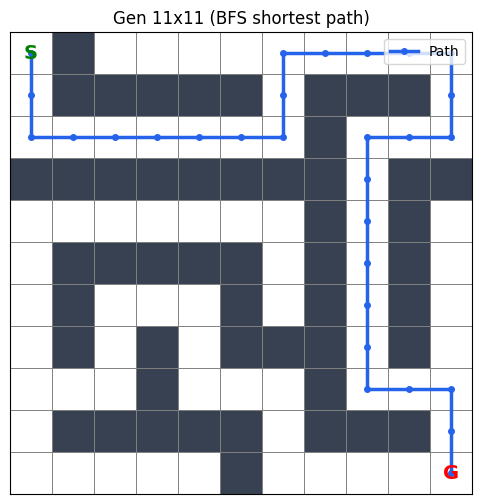

Gen 15x15: 127 open cells, shortest path 48 steps, 7 dead ends


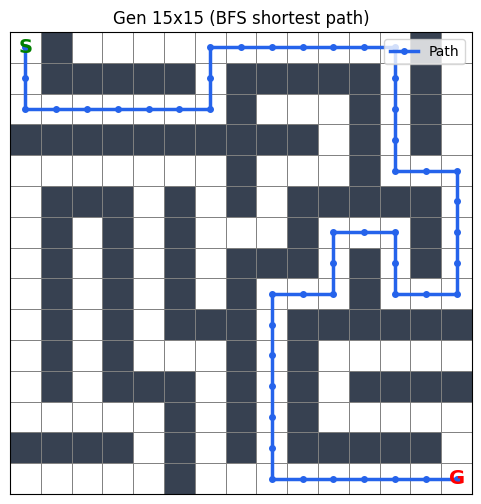

Gen 21x21: 241 open cells, shortest path 124 steps, 14 dead ends


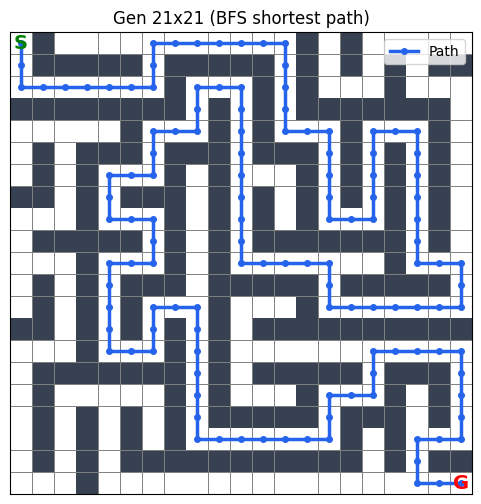

In [34]:
# Section 10.1: Random maze generator (recursive backtracking / depth-first search)

def generate_maze(k, seed=0):
    """Return a (2k-1) x (2k-1) perfect maze as a list of strings.

    Cells sit on even coordinates; odd coordinates between them start as walls.
    The generator walks randomly, knocking down the wall between the current
    cell and an unvisited neighbour, and backtracks at dead ends.
    """
    n = 2 * k - 1
    grid = [["#"] * n for _ in range(n)]
    rng = np.random.default_rng(seed)

    grid[0][0] = "."
    visited = {(0, 0)}
    stack = [(0, 0)]

    while stack:
        r, c = stack[-1]
        neighbours = [(r + dr, c + dc, dr, dc)
                      for dr, dc in [(-2, 0), (2, 0), (0, -2), (0, 2)]
                      if 0 <= r + dr < n and 0 <= c + dc < n
                      and (r + dr, c + dc) not in visited]
        if not neighbours:
            stack.pop()
            continue
        nr, nc, dr, dc = neighbours[rng.integers(len(neighbours))]
        grid[r + dr // 2][c + dc // 2] = "."     # knock down the wall
        grid[nr][nc] = "."
        visited.add((nr, nc))
        stack.append((nr, nc))

    grid[0][0] = "S"
    grid[n - 1][n - 1] = "G"
    return ["".join(row) for row in grid]


def count_dead_ends(maze):
    n = len(maze)
    dead = 0
    for r in range(n):
        for c in range(n):
            if maze[r][c] == "." and sum(open_cell(maze, r + dr, c + dc) for dr, dc in DIRS) == 1:
                dead += 1
    return dead


GEN_MAZES = {f"Gen {2*k-1}x{2*k-1}": generate_maze(k, seed=1) for k in [6, 8, 11]}
ALL_MAZES = {**MAZES, **GEN_MAZES}

for name, layout in GEN_MAZES.items():
    path = validate_maze_with_bfs(layout)
    assert path is not None, "Generated maze must be solvable"
    open_cells = sum(ch != "#" for row in layout for ch in row)
    print(f"{name}: {open_cells} open cells, shortest path {len(path) - 1} steps, "
          f"{count_dead_ends(layout)} dead ends")
    draw_maze(layout, path=path, title=f"{name} (BFS shortest path)")

In [35]:
# Section 10.2: How Q-learning scales with maze size
# For every run we record when the greedy policy FIRST becomes optimal.

def step_cap(maze):
    """100 steps for the original small mazes; 4 x cells for generated ones."""
    n = len(maze)
    return MAX_STEPS if n <= 7 else 4 * n * n


def run_until_optimal(maze, seed, alpha, episodes, algorithm="q_learning",
                      env_kwargs=None, max_steps=None):
    """Train once, evaluating the greedy policy after each episode until it is optimal."""
    max_steps = max_steps or step_cap(maze)
    shortest = len(validate_maze_with_bfs(maze)) - 1
    found = {"episode": None}

    def check(episode, Q, epsilon):
        if found["episode"] is None:
            ev = evaluate_agent(Q, maze=maze, max_steps=max_steps)
            if ev["success"] and ev["steps"] == shortest:
                found["episode"] = episode

    t0 = time.perf_counter()
    Q, h = train(maze, seed=seed, episodes=episodes, alpha=alpha, max_steps=max_steps,
                 callback=check, algorithm=algorithm, env_kwargs=env_kwargs)
    elapsed = time.perf_counter() - t0

    k = found["episode"]
    steps, walls = np.cumsum(h["steps"]), np.cumsum(h["wall_hits"])
    final = evaluate_agent(Q, maze=maze, max_steps=max_steps)
    return Q, h, {
        "Episodes_to_optimal": k,
        "Steps_to_optimal": int(steps[k - 1]) if k else None,
        "Wall_hits_to_optimal": int(walls[k - 1]) if k else None,
        "Final_optimal": int(final["success"] and final["steps"] == shortest),
        "Training_time_s": elapsed,
    }


scale_rows = []
for name, layout in ALL_MAZES.items():
    n = len(layout)
    q_star = value_iteration(layout)
    for alpha in [0.1, 0.5]:
        for seed in SEEDS:
            Q, h, res = run_until_optimal(layout, seed, alpha, episodes=3000)
            scale_rows.append({"Maze": name, "Size": n,
                               "Shortest_path": len(validate_maze_with_bfs(layout)) - 1,
                               "Alpha": alpha, "Seed": seed,
                               "Q_error_final": q_error(Q, q_star, layout),
                               "Route_error_final": route_value_error(Q, q_star, layout), **res})

scale_df = pd.DataFrame(scale_rows)
scale_summary = scale_df.groupby(["Maze", "Size", "Shortest_path", "Alpha"]).agg(
    Optimal_found=("Episodes_to_optimal", lambda s: f"{s.notna().sum()}/{len(s)}"),
    Episodes_to_optimal=("Episodes_to_optimal", "mean"),
    Steps_to_optimal=("Steps_to_optimal", "mean"),
    Wall_hits_to_optimal=("Wall_hits_to_optimal", "mean"),
    Final_optimal_rate=("Final_optimal", "mean"),
    Q_error_final=("Q_error_final", "mean"),
    Route_error_final=("Route_error_final", "mean"),
    Time_s=("Training_time_s", "mean"),
).reset_index().sort_values(["Size", "Alpha"])
scale_summary["Final_optimal_rate"] *= 100

print("Q-LEARNING SCALING (3,000 episodes max, 5 seeds; step cap 100 for Mazes A-C, 4 x cells for generated)")
print(scale_summary.round(1).to_string(index=False))
print("\nQ_error_final = max |Q - Q*| over ALL open cells (dominated by cells the agent never visits).")
print("Route_error_final = max |V - V*| along the shortest route only.")

Q-LEARNING SCALING (3,000 episodes max, 5 seeds; step cap 100 for Mazes A-C, 4 x cells for generated)
     Maze  Size  Shortest_path  Alpha Optimal_found  Episodes_to_optimal  Steps_to_optimal  Wall_hits_to_optimal  Final_optimal_rate  Q_error_final  Route_error_final  Time_s
   Maze A     5              8    0.1           5/5                  9.6             781.6                 384.4               100.0           49.4                0.0     1.0
   Maze B     5              8    0.1           5/5                  8.6             679.6                 330.2               100.0           44.0                0.0     0.8
   Maze A     5              8    0.5           5/5                  6.4             535.0                 269.0               100.0            0.1                0.0     0.8
   Maze B     5              8    0.5           5/5                  6.8             525.0                 256.4               100.0            0.0                0.0     0.8
   Maze C     7        

CLASSICAL vs Q-LEARNING (alpha = 0.5, 5-seed mean) ACROSS MAZE SIZES
     Maze  Size  Shortest_path  BFS_nodes  Astar_nodes  FloodFill_run1_moves  FloodFill_run1_wall_hits  FloodFill_run2_path  QL_moves_to_optimal  QL_wall_hits  QL_episodes
   Maze A     5              8         18           17                     9                         1                    8                535.0         269.0          6.0
   Maze B     5              8         18           17                     8                         0                    8                525.0         256.0          7.0
   Maze C     7             12         38           32                    12                         0                   12               1978.0         885.0         21.0
Gen 11x11    11             28         35           31                    39                        11                   38               9085.0        4649.0         20.0
Gen 15x15    15             48         62           57                 

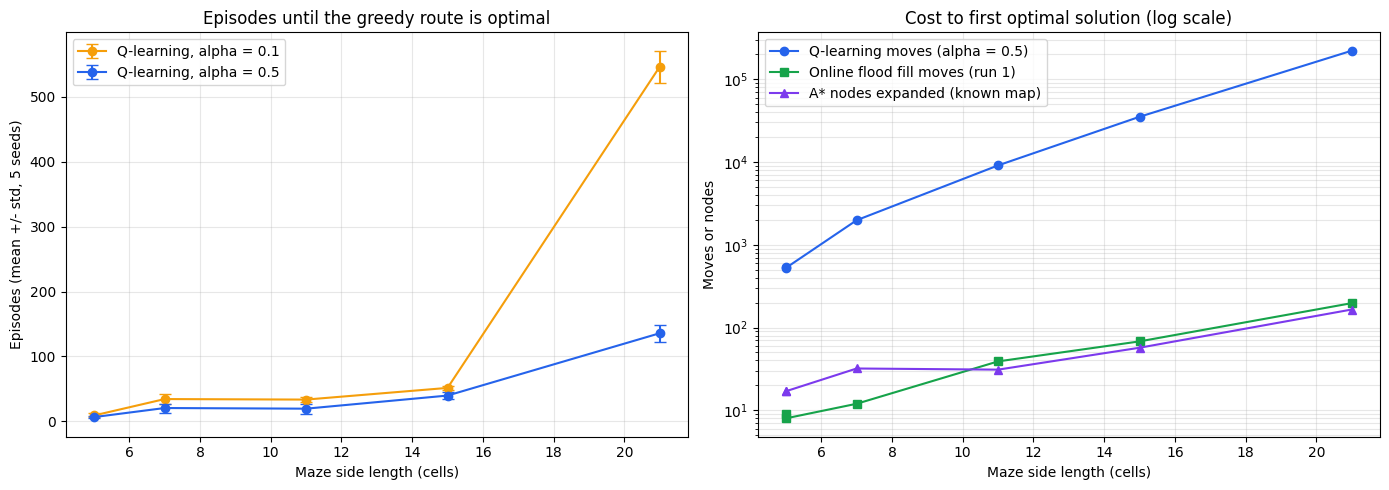

In [36]:
# Section 10.3: Classical methods on the generated mazes, and the scaling plot

big_rows = []
for name, layout in ALL_MAZES.items():
    shortest = len(validate_maze_with_bfs(layout)) - 1
    _, bfs_exp = bfs_counted(layout)
    _, a_exp = astar(layout)
    ff = online_flood_fill(layout, runs=2)
    big_rows.append({"Maze": name, "Size": len(layout), "Shortest_path": shortest,
                     "BFS_nodes": bfs_exp, "Astar_nodes": a_exp,
                     "FloodFill_run1_moves": ff[0]["Env_Steps"],
                     "FloodFill_run1_wall_hits": ff[0]["Wall_Hits"],
                     "FloodFill_run2_path": ff[1]["Path_Length"]})

big_df = pd.DataFrame(big_rows)
ql = (scale_df[scale_df["Alpha"] == 0.5].groupby("Maze")
      [["Steps_to_optimal", "Wall_hits_to_optimal", "Episodes_to_optimal"]].mean().round(0))
big_df = big_df.merge(ql, left_on="Maze", right_index=True)
big_df = big_df.rename(columns={"Steps_to_optimal": "QL_moves_to_optimal",
                                "Wall_hits_to_optimal": "QL_wall_hits",
                                "Episodes_to_optimal": "QL_episodes"})
print("CLASSICAL vs Q-LEARNING (alpha = 0.5, 5-seed mean) ACROSS MAZE SIZES")
print(big_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
order = big_df.sort_values("Size")
for alpha, colour in [(0.1, "#f59e0b"), (0.5, "#2563eb")]:
    d = (scale_df[scale_df["Alpha"] == alpha].groupby("Size")["Episodes_to_optimal"]
         .agg(["mean", "std"]).reset_index())
    axes[0].errorbar(d["Size"], d["mean"], yerr=d["std"], marker="o", capsize=4,
                     color=colour, label=f"Q-learning, alpha = {alpha}")
axes[0].set_title("Episodes until the greedy route is optimal")
axes[0].set_xlabel("Maze side length (cells)")
axes[0].set_ylabel("Episodes (mean +/- std, 5 seeds)")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(order["Size"], order["QL_moves_to_optimal"], marker="o", color="#2563eb",
             label="Q-learning moves (alpha = 0.5)")
axes[1].plot(order["Size"], order["FloodFill_run1_moves"], marker="s", color="#16a34a",
             label="Online flood fill moves (run 1)")
axes[1].plot(order["Size"], order["Astar_nodes"], marker="^", color="#7c3aed",
             label="A* nodes expanded (known map)")
axes[1].set_yscale("log")
axes[1].set_title("Cost to first optimal solution (log scale)")
axes[1].set_xlabel("Maze side length (cells)")
axes[1].set_ylabel("Moves or nodes")
axes[1].grid(alpha=0.3, which="both")
axes[1].legend()
plt.tight_layout()
plt.show()

**Reading the scaling results.**

- **Q-learning still finds the optimal route** on every generated maze for all 5 seeds, including the 21×21 maze with a 124-step shortest path. The value error along the route is 0.0 in every case.
- **But the cost grows much faster than the maze.** With α = 0.5, moves to an optimal greedy route rise from 535 (5×5) to 220,518 (21×21), about 400×, while the shortest path only grows about 15× (8 → 124). Flood fill's first run grows from 9 to 197 moves and A\*'s search from 17 to 165 nodes, both roughly in line with the maze size.
- **Learning rate matters more in big mazes.** On the 21×21 maze, α = 0.1 needs 546 episodes on average versus 136 for α = 0.5. On the 5×5 mazes the difference is only a few episodes.
- **Online flood fill is no longer optimal.** On the generated mazes its second run takes 38, 62 and 150 steps against optima of 28, 48 and 124. The agent only learns about walls it bumps into, so unexplored areas still look open and it keeps choosing routes that only appear shorter. A real micromouse fixes this by continuing to explore until the route is proven; our single-pass version does not.
- **Why max |Q − Q\*| is 100 on the 11×11 and 15×15 mazes:** both contain a corridor next to the goal that the agent never enters, so its Q-values stay at 0 while the true value of stepping into the goal is 100. This is the same coverage effect seen in Maze C (Section 8), and it is why we also report the error along the route.


## 11. Reward design experiments

We vary the wall penalty ∈ {−1, −5, −20} and the step penalty ∈ {0, −1}, keeping the goal reward at +100, γ = 0.95 and α = 0.1. With a step penalty of 0, only discounting (γ < 1) pushes the agent toward shorter routes, because +100 received later is worth less. Tested on Maze C and the generated 11×11 maze, 5 seeds each.

REWARD DESIGN (alpha = 0.1, 2,000 episodes, 5 seeds)
     Maze  Step  Wall Optimal_found  Episodes_to_optimal  Wall_hits_to_optimal  Total_training_wall_hits  Total_training_steps  Final_optimal_rate
Gen 11x11    -1   -20           5/5                 33.6                7837.2                   50233.0              155890.0               100.0
Gen 11x11    -1    -5           5/5                 33.6                7838.2                   50232.6              155890.0               100.0
Gen 11x11    -1    -1           5/5                 43.0               10053.4                   50420.8              156109.2               100.0
Gen 11x11     0   -20           5/5                 42.0                9831.4                   50546.0              156555.6               100.0
Gen 11x11     0    -5           5/5                 42.0                9831.4                   50546.0              156555.6               100.0
Gen 11x11     0    -1           5/5                 42.0         

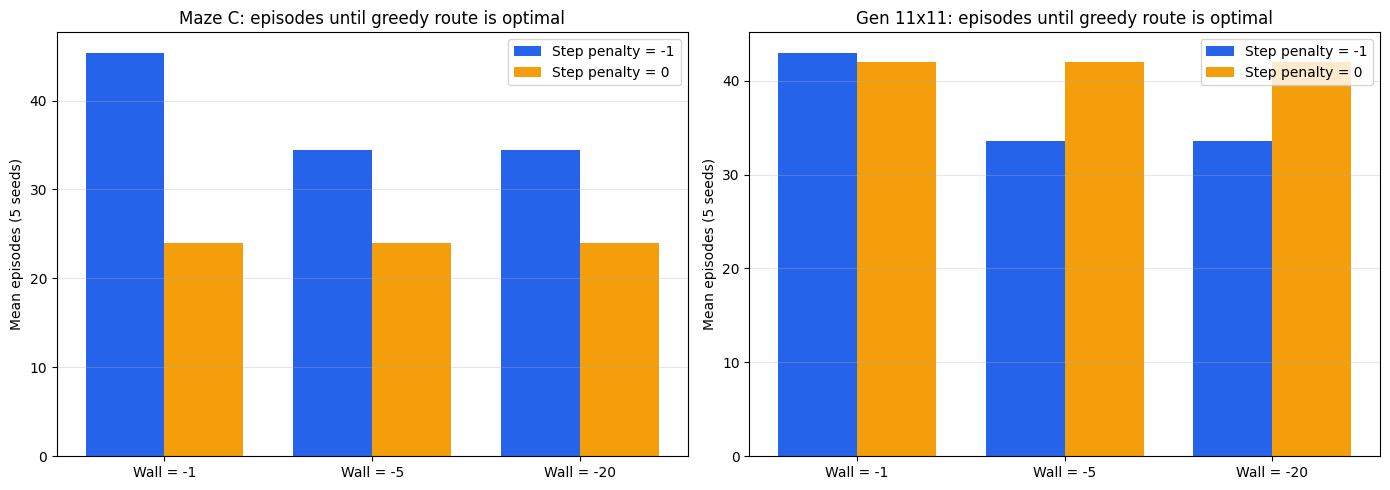

In [37]:
# Section 11.1: Reward design sweep

reward_configs = [(wall, step) for step in [-1, 0] for wall in [-1, -5, -20]]
reward_mazes = {"Maze C": maze_C, "Gen 11x11": GEN_MAZES["Gen 11x11"]}

reward_rows = []
for maze_name, layout in reward_mazes.items():
    for wall, step in reward_configs:
        kwargs = {"wall_reward": wall, "step_reward": step, "goal_reward": 100}
        for seed in SEEDS:
            _, h, res = run_until_optimal(layout, seed, alpha=0.1, episodes=2000, env_kwargs=kwargs)
            reward_rows.append({
                "Maze": maze_name, "Wall": wall, "Step": step, "Seed": seed,
                "Total_training_wall_hits": int(np.sum(h["wall_hits"])),
                "Total_training_steps": int(np.sum(h["steps"])),
                **res})

reward_df = pd.DataFrame(reward_rows)
reward_summary = reward_df.groupby(["Maze", "Step", "Wall"]).agg(
    Optimal_found=("Episodes_to_optimal", lambda s: f"{s.notna().sum()}/{len(s)}"),
    Episodes_to_optimal=("Episodes_to_optimal", "mean"),
    Wall_hits_to_optimal=("Wall_hits_to_optimal", "mean"),
    Total_training_wall_hits=("Total_training_wall_hits", "mean"),
    Total_training_steps=("Total_training_steps", "mean"),
    Final_optimal_rate=("Final_optimal", "mean"),
).reset_index()
reward_summary["Final_optimal_rate"] *= 100

print("REWARD DESIGN (alpha = 0.1, 2,000 episodes, 5 seeds)")
print(reward_summary.round(1).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, maze_name in zip(axes, reward_mazes):
    d = reward_summary[reward_summary["Maze"] == maze_name]
    x = np.arange(3)
    for i, (step, colour) in enumerate([(-1, "#2563eb"), (0, "#f59e0b")]):
        dd = d[d["Step"] == step].sort_values("Wall", ascending=False)
        ax.bar(x + (i - 0.5) * 0.38, dd["Episodes_to_optimal"], width=0.38,
               color=colour, label=f"Step penalty = {step}")
    ax.set_xticks(x)
    ax.set_xticklabels(["Wall = -1", "Wall = -5", "Wall = -20"])
    ax.set_title(f"{maze_name}: episodes until greedy route is optimal")
    ax.set_ylabel("Mean episodes (5 seeds)")
    ax.grid(alpha=0.3, axis="y")
    ax.legend()
plt.tight_layout()
plt.show()

**Reading the reward results.**

- **Wall penalty −5 vs −20 makes no difference.** Learning is identical (Maze C: 34.4 episodes; 11×11: 33.6). In a deterministic maze a wall hit already wastes a step, so once the wall penalty is worse than a move, the greedy choice depends only on which action looks best — and making a bad action look even worse does not change that ranking.
- **A wall penalty equal to the step penalty (−1) slows learning** (Maze C: 45.4 vs 34.4 episodes; 11×11: 43.0 vs 33.6). A wall hit then looks only slightly worse than a real move, through discounting alone, so the agent needs more experience to rank actions correctly.
- **No step penalty still works.** With step = 0, all runs found the optimal route, because γ = 0.95 makes a reward reached sooner worth more. It was faster on Maze C (24.0 episodes) but slower on the 11×11 maze (42.0), so there is no consistent winner. With step = 0, the three wall settings behaved identically.
- **Penalties do not reduce wall hits during training** (≈14,400 on Maze C in every setting). Those hits come from random ε-greedy moves, which ignore the Q-table. Reward design changes what the agent *learns*, not how much it bumps into walls while exploring.


## 12. Algorithm comparison: Q-learning vs SARSA

Both learn a Q-table with the same ε-greedy exploration. The difference is one term in the update:

- **Q-learning (off-policy):** `target = r + γ · max_a′ Q(s′, a′)` — learns the value of acting *optimally*, even while exploring.
- **SARSA (on-policy):** `target = r + γ · Q(s′, a′)` where a′ is the action the agent actually takes next — learns the value of its *own ε-greedy behaviour*, including random moves.

Intuition: Q-learning assumes "from here I'll play perfectly"; SARSA assumes "from here I'll keep making occasional random moves". SARSA's values are therefore more pessimistic near walls.

Q-LEARNING vs SARSA (alpha = 0.1, 2,000 episodes, 5 seeds)
Start_value = learned max Q at the start cell; Q* is the optimal value.
     Maze  Algorithm Optimal_found  Episodes_to_optimal  Final_optimal_rate  Training_wall_hits  Reward_last_200  Start_value  Start_value_Qstar
Gen 11x11 q_learning           5/5                 33.6               100.0             50232.6            57.80        10.04              10.04
Gen 11x11      sarsa           5/5                 41.2               100.0             59358.4            58.28        -7.70              10.04
   Maze A q_learning           5/5                  9.6               100.0             10132.6            89.10        63.80              63.80
   Maze A      sarsa           5/5                 12.6               100.0              9781.8            89.44        56.57              63.80
   Maze B q_learning           5/5                  8.6               100.0             10312.4            88.99        63.80              63.80

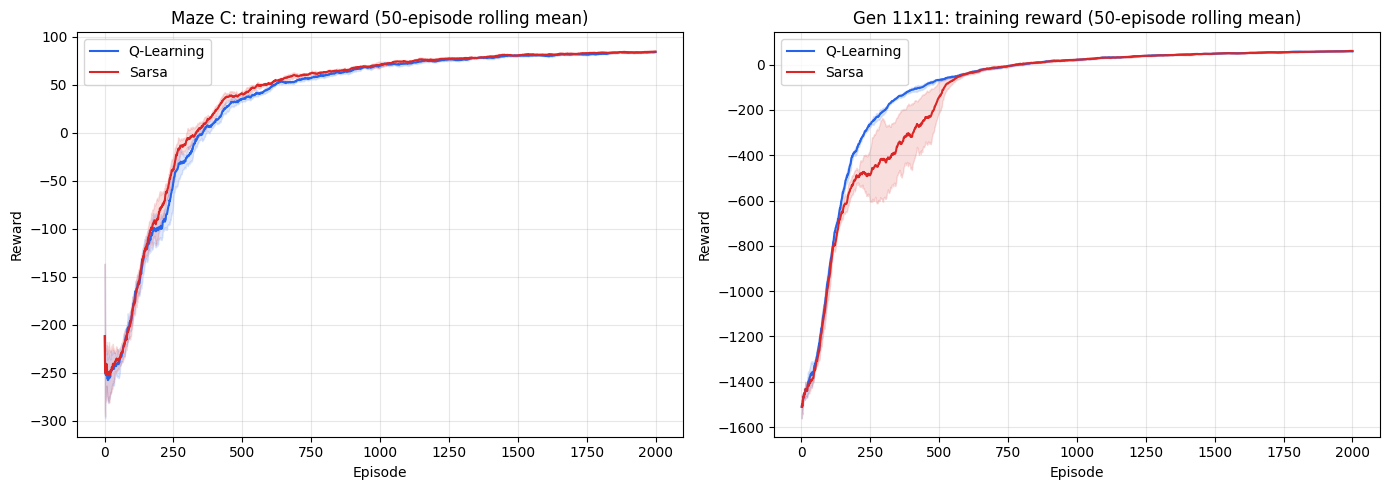

In [38]:
# Section 12.1: SARSA vs Q-learning

sarsa_mazes = {"Maze A": maze_A, "Maze B": maze_B, "Maze C": maze_C,
               "Gen 11x11": GEN_MAZES["Gen 11x11"]}
algo_rows = []
algo_hist = {}

for maze_name, layout in sarsa_mazes.items():
    q_star = value_iteration(layout)
    for algorithm in ["q_learning", "sarsa"]:
        for seed in SEEDS:
            Q, h, res = run_until_optimal(layout, seed, alpha=0.1, episodes=2000,
                                          algorithm=algorithm)
            algo_hist.setdefault((maze_name, algorithm), []).append(h)
            algo_rows.append({
                "Maze": maze_name, "Algorithm": algorithm, "Seed": seed,
                "Total_training_wall_hits": int(np.sum(h["wall_hits"])),
                "Mean_reward_last_200": float(np.mean(h["reward"][-200:])),
                "Q_error_final": q_error(Q, q_star, layout),
                "Start_value": float(Q[0].max()),
                "Start_value_Qstar": float(q_star[0].max()),
                **res})

algo_df = pd.DataFrame(algo_rows)
algo_summary = algo_df.groupby(["Maze", "Algorithm"]).agg(
    Optimal_found=("Episodes_to_optimal", lambda s: f"{s.notna().sum()}/{len(s)}"),
    Episodes_to_optimal=("Episodes_to_optimal", "mean"),
    Final_optimal_rate=("Final_optimal", "mean"),
    Training_wall_hits=("Total_training_wall_hits", "mean"),
    Reward_last_200=("Mean_reward_last_200", "mean"),
    Start_value=("Start_value", "mean"),
    Start_value_Qstar=("Start_value_Qstar", "first"),
).reset_index()
algo_summary["Final_optimal_rate"] *= 100

print("Q-LEARNING vs SARSA (alpha = 0.1, 2,000 episodes, 5 seeds)")
print("Start_value = learned max Q at the start cell; Q* is the optimal value.")
print(algo_summary.round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, maze_name in zip(axes, ["Maze C", "Gen 11x11"]):
    for algorithm, colour in [("q_learning", "#2563eb"), ("sarsa", "#dc2626")]:
        r = np.array([pd.Series(h["reward"]).rolling(50, min_periods=1).mean()
                      for h in algo_hist[(maze_name, algorithm)]])
        x = np.arange(1, r.shape[1] + 1)
        ax.plot(x, r.mean(0), color=colour, label=algorithm.replace("_", "-").title())
        ax.fill_between(x, r.mean(0) - r.std(0), r.mean(0) + r.std(0), color=colour, alpha=0.15)
    ax.set_title(f"{maze_name}: training reward (50-episode rolling mean)")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Reward")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

**Reading the SARSA comparison.**

- **Both algorithms find the optimal greedy route** on all four mazes for all 5 seeds.
- **SARSA is a little slower** on Mazes A and B (12.6 vs 9.6 and 11.2 vs 8.6 episodes) and on the 11×11 maze (41.2 vs 33.6, with about 18% more wall hits). On Maze C they are about equal (33.6 vs 34.4).
- **SARSA's values are more pessimistic.** Its start-cell value is 56.6 on Maze A and −7.7 on the 11×11 maze, versus Q\* = 63.8 and 10.0. Q-learning's start values match Q\* exactly. This is the textbook difference: SARSA learns the value of the ε-greedy policy it is actually following, including the random moves still made 13.5% of the time, while Q-learning learns the value of the best possible policy.
- **SARSA's training reward in the last 200 episodes is slightly higher on every maze** (e.g. 83.83 vs 83.53 on Maze C). It optimises the behaviour it actually performs. The gap is small because a wall hit here only costs −5 and leaves the agent in place; there is no dangerous cell (like the "cliff" in Sutton & Barto's Example 6.6) where SARSA's caution would pay off strongly.


## 13. Final demonstration: animated learned route

Each frame shows the agent following its **learned greedy policy** (no map, no BFS). The trail shows cells already visited. The GIFs are also saved as files for use in the presentation.

Saved mazemind_maze_c.gif


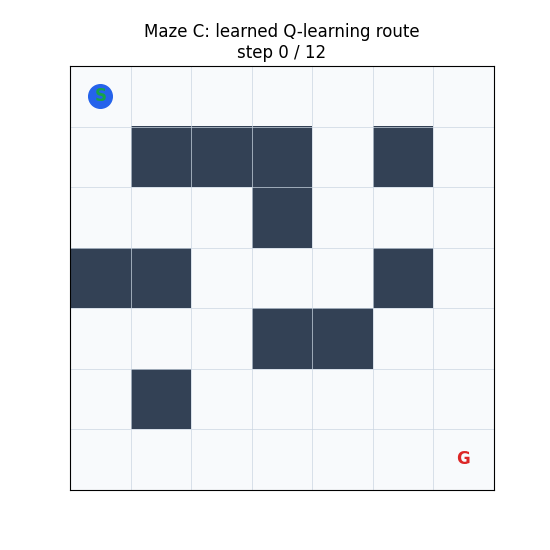

Saved mazemind_gen_15x15.gif


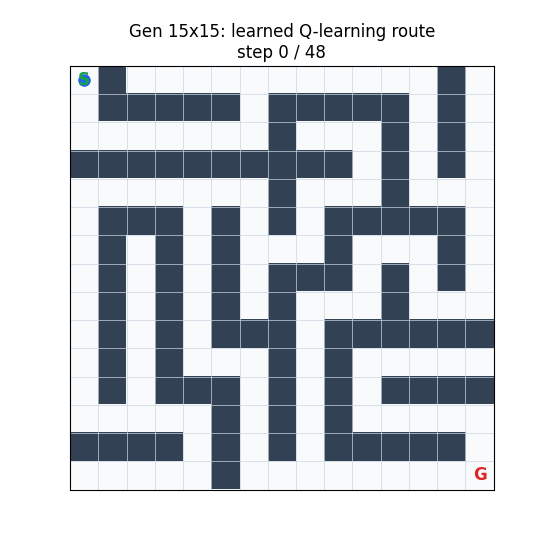

In [39]:
# Section 13.1: Animate the learned route

from matplotlib import animation
from matplotlib.colors import ListedColormap
from IPython.display import Image, display


def animate_route(maze, Q, title, filename, fps=4):
    n = len(maze)
    route = evaluate_agent(Q, maze=maze, max_steps=step_cap(maze))["route"]
    walls = np.array([[1 if ch == "#" else 0 for ch in row] for row in maze])

    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    ax.imshow(walls, cmap=ListedColormap(["#f8fafc", "#334155"]), vmin=0, vmax=1)
    sr, sc = find_cell(maze, "S")
    gr, gc = find_cell(maze, "G")
    ax.text(sc, sr, "S", ha="center", va="center", color="#16a34a", fontsize=12, fontweight="bold")
    ax.text(gc, gr, "G", ha="center", va="center", color="#dc2626", fontsize=12, fontweight="bold")
    ax.set_xticks(np.arange(-0.5, n, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, n, 1), minor=True)
    ax.grid(which="minor", color="#cbd5e1", linewidth=0.5)
    ax.tick_params(which="both", bottom=False, left=False, labelbottom=False, labelleft=False)

    trail, = ax.plot([], [], color="#2563eb", linewidth=3, alpha=0.6)
    agent, = ax.plot([], [], "o", color="#2563eb", markersize=max(6, 120 // n))
    caption = ax.set_title(title)

    def update(i):
        pts = route[: i + 1]
        trail.set_data([p[1] for p in pts], [p[0] for p in pts])
        agent.set_data([route[i][1]], [route[i][0]])
        status = "  GOAL!" if route[i] == (gr, gc) else ""
        caption.set_text(f"{title}\nstep {i} / {len(route) - 1}{status}")
        return trail, agent, caption

    frames = list(range(len(route))) + [len(route) - 1] * fps * 2   # pause on the goal
    anim = animation.FuncAnimation(fig, update, frames=frames, blit=False)
    anim.save(filename, writer=animation.PillowWriter(fps=fps))
    plt.close(fig)
    return filename


demo_specs = [("Maze C", maze_C, 2000, 4), ("Gen 15x15", GEN_MAZES["Gen 15x15"], 3000, 10)]
for name, layout, episodes, fps in demo_specs:
    Q, _ = train(layout, seed=10, episodes=episodes, alpha=0.5,
                 max_steps=step_cap(layout))
    fname = f"mazemind_{name.lower().replace(' ', '_')}.gif"
    animate_route(layout, Q, f"{name}: learned Q-learning route", fname, fps=fps)
    print("Saved", fname)
    with open(fname, "rb") as f:
        display(Image(data=f.read(), format="gif"))

## 14. Dynamic Obstacles: Q-learning vs Classical Search

This experiment introduces moving obstacles into the maze.

Unlike the previous static-maze experiments, the environment
changes after each agent action.

We compare Q-learning, fixed-route BFS, and replanning BFS
using the same dynamic environment.

In [40]:

# Section 14.1: Dynamic maze environment with a moving wall

class DynamicMazeEnv(gym.Env):
    """
    A grid maze with one obstacle that alternates between two cells.

    The state includes:
      - Agent position
      - Moving obstacle phase (0 or 1)

    This allows Q-learning to learn different actions depending
    on where the moving obstacle currently is.
    """

    DIRECTIONS = [
        (-1, 0),  # 0: Up
        (0, 1),   # 1: Right
        (1, 0),   # 2: Down
        (0, -1),  # 3: Left
    ]

    def __init__(self, max_steps=60):
        super().__init__()

        self.maze = [
            ".......",
            ".......",
            "S.....G",
            ".......",
            ".......",
        ]

        self.rows = len(self.maze)
        self.cols = len(self.maze[0])

        self.start = (2, 0)
        self.goal = (2, 6)

        # Moving wall alternates between these two positions.
        self.obstacle_positions = [(2, 3), (1, 3)]

        self.action_space = spaces.Discrete(4)

        # Agent position combined with obstacle phase.
        self.observation_space = spaces.Discrete(
            self.rows * self.cols * 2
        )

        self.max_steps = max_steps
        self.reset()

    def get_state(self):
        row, col = self.position
        cell_id = row * self.cols + col
        return cell_id * 2 + self.phase

    def get_obstacle(self):
        return self.obstacle_positions[self.phase]

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)

        self.position = self.start
        self.phase = 0
        self.steps = 0

        return self.get_state(), {}

    def step(self, action):
        if not self.action_space.contains(action):
            raise ValueError("Invalid action")

        dr, dc = self.DIRECTIONS[int(action)]
        row, col = self.position
        target = (row + dr, col + dc)

        current_obstacle = self.get_obstacle()
        next_phase = 1 - self.phase
        next_obstacle = self.obstacle_positions[next_phase]

        collision = False
        reward = -1

        # Block attempts to enter the obstacle's current cell
        # or its next cell during the same time step.
        if (
            not (0 <= target[0] < self.rows)
            or not (0 <= target[1] < self.cols)
            or self.maze[target[0]][target[1]] == "#"
            or target == current_obstacle
            or target == next_obstacle
        ):
            collision = True
            reward = -5
        else:
            self.position = target

        # If the wall moves into the agent's existing cell,
        # keep the agent safe by leaving the obstacle in place.
        # This special case does not occur in the intended
        # routes unless the agent enters the wall's track.
        if self.position == next_obstacle:
            self.position = (row, col)
            collision = True
            reward = -5

        self.phase = next_phase
        self.steps += 1

        terminated = self.position == self.goal
        truncated = self.steps >= self.max_steps and not terminated

        if terminated:
            reward = 100

        return (
            self.get_state(),
            reward,
            terminated,
            truncated,
            {
                "collision": collision,
                "obstacle": self.get_obstacle(),
                "position": self.position,
            },
        )

    def render(self):
        grid = [list(row) for row in self.maze]

        obstacle_row, obstacle_col = self.get_obstacle()
        grid[obstacle_row][obstacle_col] = "X"

        row, col = self.position
        grid[row][col] = "A"

        print("\n".join(" ".join(row) for row in grid))
        print()


# Test the moving obstacle
dynamic_env = DynamicMazeEnv()
state, _ = dynamic_env.reset()

print("DYNAMIC MAZE INITIAL STATE")
print("State:", state)
print("Agent position:", dynamic_env.position)
print("Moving wall position:", dynamic_env.get_obstacle())
dynamic_env.render()

# Move the agent right once
state, reward, terminated, truncated, info = dynamic_env.step(1)

print("AFTER ONE ACTION")
print("State:", state)
print("Agent position:", dynamic_env.position)
print("Moving wall position:", dynamic_env.get_obstacle())
print("Reward:", reward)
print("Collision:", info["collision"])
dynamic_env.render()


DYNAMIC MAZE INITIAL STATE
State: 28
Agent position: (2, 0)
Moving wall position: (2, 3)
. . . . . . .
. . . . . . .
A . . X . . G
. . . . . . .
. . . . . . .

AFTER ONE ACTION
State: 31
Agent position: (2, 1)
Moving wall position: (1, 3)
Reward: -1
Collision: False
. . . . . . .
. . . X . . .
S A . . . . G
. . . . . . .
. . . . . . .



In [41]:

# Section 14.2: Train Q-learning with moving obstacles

import numpy as np

# Create a fresh environment for training
train_env = DynamicMazeEnv(max_steps=60)

# Q-learning hyperparameters
episodes = 15000
alpha = 0.1
gamma = 0.95
epsilon_start = 1.0
epsilon_min = 0.05
epsilon_decay = 0.9995

# Q-table: one row per state, one column per action
q_table_dynamic = np.zeros((
    train_env.observation_space.n,
    train_env.action_space.n
))

rng = np.random.default_rng(42)

training_rewards = []
training_successes = []
training_collisions = []

epsilon = epsilon_start

for episode in range(episodes):
    state, _ = train_env.reset()

    total_reward = 0
    collisions = 0
    success = False

    for step in range(train_env.max_steps):

        # Epsilon-greedy action selection
        if rng.random() < epsilon:
            action = int(rng.integers(train_env.action_space.n))
        else:
            action = int(np.argmax(q_table_dynamic[state]))

        next_state, reward, terminated, truncated, info = (
            train_env.step(action)
        )

        # Q-learning update
        if terminated or truncated:
            target = reward
        else:
            target = reward + gamma * np.max(
                q_table_dynamic[next_state]
            )

        q_table_dynamic[state, action] += alpha * (
            target - q_table_dynamic[state, action]
        )

        total_reward += reward
        collisions += int(info["collision"])

        state = next_state

        if terminated or truncated:
            success = terminated
            break

    training_rewards.append(total_reward)
    training_successes.append(int(success))
    training_collisions.append(collisions)

    # Gradually reduce exploration
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

    if (episode + 1) % 3000 == 0:
        recent_success = np.mean(
            training_successes[-3000:]
        ) * 100

        recent_reward = np.mean(
            training_rewards[-3000:]
        )

        print(
            f"Episode {episode + 1:5d} | "
            f"Success: {recent_success:6.2f}% | "
            f"Avg reward: {recent_reward:7.2f} | "
            f"Epsilon: {epsilon:.3f}"
        )

print("\nTRAINING COMPLETED")
print("Q-table shape:", q_table_dynamic.shape)
print("Final epsilon:", round(epsilon, 4))


# -------------------------------------------------
# Evaluate the learned greedy policy
# -------------------------------------------------

eval_env = DynamicMazeEnv(max_steps=60)

evaluation_episodes = 200

eval_successes = 0
eval_steps = []
eval_collisions = []

example_route = []

for episode in range(evaluation_episodes):
    state, _ = eval_env.reset()

    collisions = 0
    route = [eval_env.position]

    for step in range(eval_env.max_steps):

        # Greedy policy: no random exploration
        action = int(np.argmax(q_table_dynamic[state]))

        next_state, reward, terminated, truncated, info = (
            eval_env.step(action)
        )

        collisions += int(info["collision"])
        route.append(eval_env.position)

        state = next_state

        if terminated or truncated:
            if terminated:
                eval_successes += 1
                eval_steps.append(step + 1)
            break

    eval_collisions.append(collisions)

    if episode == 0:
        example_route = route.copy()

success_rate = (
    eval_successes / evaluation_episodes * 100
)

avg_steps = (
    np.mean(eval_steps)
    if eval_steps else float("nan")
)

avg_collisions = np.mean(eval_collisions)

print("\nDYNAMIC Q-LEARNING EVALUATION")
print("Evaluation episodes:", evaluation_episodes)
print(f"Success rate: {success_rate:.2f}%")
print(f"Average steps (successful): {avg_steps:.2f}")
print(f"Average collisions: {avg_collisions:.2f}")
print("Example route:", example_route)


Episode  3000 | Success:  90.53% | Avg reward:   57.31 | Epsilon: 0.223
Episode  6000 | Success: 100.00% | Avg reward:   91.16 | Epsilon: 0.050
Episode  9000 | Success: 100.00% | Avg reward:   92.34 | Epsilon: 0.050
Episode 12000 | Success: 100.00% | Avg reward:   92.30 | Epsilon: 0.050
Episode 15000 | Success: 100.00% | Avg reward:   92.36 | Epsilon: 0.050

TRAINING COMPLETED
Q-table shape: (70, 4)
Final epsilon: 0.05

DYNAMIC Q-LEARNING EVALUATION
Evaluation episodes: 200
Success rate: 100.00%
Average steps (successful): 8.00
Average collisions: 0.00
Example route: [(2, 0), (2, 1), (3, 1), (3, 2), (3, 3), (3, 4), (2, 4), (2, 5), (2, 6)]


In [42]:

# Section 14.3: Q-learning vs BFS with moving walls

from collections import deque
import numpy as np

ACTIONS = [
    (-1, 0),  # Up
    (0, 1),   # Right
    (1, 0),   # Down
    (0, -1),  # Left
]


def valid_transition(env, position, phase, action):
    """Predict the same movement and collision rules as DynamicMazeEnv."""
    dr, dc = ACTIONS[action]
    row, col = position
    target = (row + dr, col + dc)

    current_wall = env.obstacle_positions[phase]
    next_phase = 1 - phase
    next_wall = env.obstacle_positions[next_phase]

    blocked = (
        not (0 <= target[0] < env.rows)
        or not (0 <= target[1] < env.cols)
        or env.maze[target[0]][target[1]] == "#"
        or target == current_wall
        or target == next_wall
    )

    next_position = position if blocked else target

    if next_position == next_wall:
        next_position = position
        blocked = True

    return next_position, next_phase, blocked


def bfs_plan(env, start_position, start_phase=0, dynamic=False):
    """
    Static BFS ignores moving walls.
    Dynamic BFS searches over (position, obstacle phase).
    """
    initial = (
        (start_position, start_phase)
        if dynamic else start_position
    )

    queue = deque([(initial, [])])
    visited = {initial}
    expanded = 0

    while queue:
        node, path = queue.popleft()
        expanded += 1

        if dynamic:
            position, phase = node
        else:
            position = node
            phase = 0

        if position == env.goal:
            return path, expanded

        for action, (dr, dc) in enumerate(ACTIONS):
            if dynamic:
                next_pos, next_phase, blocked = valid_transition(
                    env, position, phase, action
                )

                if blocked:
                    continue

                next_node = (next_pos, next_phase)

            else:
                next_pos = (
                    position[0] + dr,
                    position[1] + dc
                )

                if not (
                    0 <= next_pos[0] < env.rows
                    and 0 <= next_pos[1] < env.cols
                ):
                    continue

                if env.maze[next_pos[0]][next_pos[1]] == "#":
                    continue

                next_node = next_pos

            if next_node not in visited:
                visited.add(next_node)
                queue.append((next_node, path + [action]))

    return None, expanded


def evaluate_method(method, episodes=200):
    results = {
        "successes": 0,
        "steps": [],
        "collisions": [],
        "expansions": [],
    }

    example_route = None

    for episode in range(episodes):
        env = DynamicMazeEnv(max_steps=60)
        state, _ = env.reset()

        collisions = 0
        expansions = 0
        route = [env.position]
        success = False

        fixed_plan = None
        plan_index = 0

        if method == "Fixed BFS":
            fixed_plan, count = bfs_plan(
                env, env.position, dynamic=False
            )
            expansions += count

        for step in range(env.max_steps):

            if method == "Q-learning":
                action = int(np.argmax(q_table_dynamic[state]))

            elif method == "Fixed BFS":
                if fixed_plan is None or plan_index >= len(fixed_plan):
                    break

                action = fixed_plan[plan_index]
                plan_index += 1

            elif method == "Replanning BFS":
                plan, count = bfs_plan(
                    env,
                    env.position,
                    env.phase,
                    dynamic=True
                )
                expansions += count

                if plan is None or len(plan) == 0:
                    break

                action = plan[0]

            else:
                raise ValueError("Unknown method")

            state, reward, terminated, truncated, info = env.step(
                action
            )

            collisions += int(info["collision"])
            route.append(env.position)

            if terminated:
                success = True
                break

            if truncated:
                break

        results["successes"] += int(success)
        results["collisions"].append(collisions)
        results["expansions"].append(expansions)

        if success:
            results["steps"].append(len(route) - 1)

        if episode == 0:
            example_route = route.copy()

    return {
        "method": method,
        "success_rate": 100 * results["successes"] / episodes,
        "avg_steps": (
            float(np.mean(results["steps"]))
            if results["steps"] else float("nan")
        ),
        "avg_collisions": float(np.mean(results["collisions"])),
        "avg_expansions": float(np.mean(results["expansions"])),
        "example_route": example_route,
    }


methods = ["Q-learning", "Fixed BFS", "Replanning BFS"]

comparison_results = [
    evaluate_method(method, episodes=200)
    for method in methods
]

print("DYNAMIC OBSTACLE COMPARISON")
print("-" * 85)
print(
    f"{'Method':<18} {'Success':>10} "
    f"{'Avg steps':>12} {'Collisions':>12} "
    f"{'BFS expansions':>16}"
)
print("-" * 85)

for result in comparison_results:
    print(
        f"{result['method']:<18} "
        f"{result['success_rate']:>9.2f}% "
        f"{result['avg_steps']:>12.2f} "
        f"{result['avg_collisions']:>12.2f} "
        f"{result['avg_expansions']:>16.2f}"
    )

print("\nEXAMPLE ROUTES")
for result in comparison_results:
    print(result["method"], ":", result["example_route"])


DYNAMIC OBSTACLE COMPARISON
-------------------------------------------------------------------------------------
Method                Success    Avg steps   Collisions   BFS expansions
-------------------------------------------------------------------------------------
Q-learning            100.00%         8.00         0.00             0.00
Fixed BFS               0.00%          nan         4.00            27.00
Replanning BFS        100.00%         8.00         0.00           167.00

EXAMPLE ROUTES
Q-learning : [(2, 0), (2, 1), (3, 1), (3, 2), (3, 3), (3, 4), (2, 4), (2, 5), (2, 6)]
Fixed BFS : [(2, 0), (2, 1), (2, 2), (2, 2), (2, 2), (2, 2), (2, 2)]
Replanning BFS : [(2, 0), (2, 1), (2, 2), (3, 2), (3, 3), (3, 4), (2, 4), (2, 5), (2, 6)]


In [43]:

# Section 14.4: Compact animated comparison (Colab-friendly)

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import ListedColormap
from IPython.display import HTML, display

def record_dynamic_episode(method):
    env = DynamicMazeEnv(max_steps=60)
    state, _ = env.reset()

    history = [{
        "position": env.position,
        "wall": env.get_obstacle(),
        "collision": False,
    }]

    fixed_plan = None
    plan_index = 0

    if method == "Fixed BFS":
        fixed_plan, _ = bfs_plan(
            env, env.position, dynamic=False
        )

    for _ in range(env.max_steps):
        if method == "Q-learning":
            action = int(np.argmax(q_table_dynamic[state]))

        elif method == "Fixed BFS":
            if fixed_plan is None or plan_index >= len(fixed_plan):
                break
            action = fixed_plan[plan_index]
            plan_index += 1

        elif method == "Replanning BFS":
            plan, _ = bfs_plan(
                env, env.position, env.phase, dynamic=True
            )
            if not plan:
                break
            action = plan[0]

        else:
            raise ValueError(f"Unknown method: {method}")

        state, reward, terminated, truncated, info = env.step(action)

        history.append({
            "position": env.position,
            "wall": env.get_obstacle(),
            "collision": bool(info["collision"]),
        })

        if terminated or truncated:
            break

    return history


methods = ["Q-learning", "Fixed BFS", "Replanning BFS"]

histories = {
    method: record_dynamic_episode(method)
    for method in methods
}

max_frames = max(len(h) for h in histories.values())

# Compact figure that fits more easily in Google Colab
fig, axes = plt.subplots(
    1, 3,
    figsize=(10.5, 3.5),
    constrained_layout=True
)

cmap = ListedColormap([
    "#ffffff",  # Empty
    "#f97316",  # Moving wall
    "#22c55e",  # Agent
    "#ef4444",  # Goal
])

images = []

for ax, method in zip(axes, methods):
    image = ax.imshow(
        np.zeros((5, 7)),
        cmap=cmap,
        vmin=0,
        vmax=3,
        interpolation="nearest"
    )

    ax.set_title(method, fontsize=10, fontweight="bold", pad=8)
    ax.set_xticks(range(7))
    ax.set_yticks(range(5))
    ax.tick_params(labelsize=7, length=0)

    # Grid lines between cells
    ax.set_xticks(np.arange(-0.5, 7, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 5, 1), minor=True)
    ax.grid(which="minor", color="#cbd5e1", linewidth=0.7)
    ax.tick_params(which="minor", bottom=False, left=False)

    images.append(image)


def update(frame):
    for ax, image, method in zip(axes, images, methods):
        history = histories[method]
        index = min(frame, len(history) - 1)
        current = history[index]

        grid = np.zeros((5, 7), dtype=int)

        wr, wc = current["wall"]
        ar, ac = current["position"]

        grid[2, 6] = 3
        grid[wr, wc] = 1
        grid[ar, ac] = 2

        image.set_data(grid)

        if current["position"] == (2, 6):
            status = "GOAL"
        elif frame >= len(history) - 1:
            status = "STOPPED"
        elif current["collision"]:
            status = "BLOCKED"
        else:
            status = "MOVING"

        ax.set_xlabel(
            f"Step {index} | {status}",
            fontsize=8,
            labelpad=6
        )

    return images


animation = FuncAnimation(
    fig,
    update,
    frames=max_frames,
    interval=700,
    repeat=True,
    blit=False
)

plt.close(fig)

# Reduce embedded animation size
plt.rcParams["animation.embed_limit"] = 20

display(HTML(animation.to_jshtml(fps=2)))

print("\nANIMATION SUMMARY")
print("-" * 55)

for method, history in histories.items():
    final_position = history[-1]["position"]
    collisions = sum(int(h["collision"]) for h in history)

    print(
        f"{method:<16} | "
        f"Steps: {len(history)-1:<3} | "
        f"Goal: {final_position == (2, 6)} | "
        f"Collisions: {collisions}"
    )



ANIMATION SUMMARY
-------------------------------------------------------
Q-learning       | Steps: 8   | Goal: True | Collisions: 0
Fixed BFS        | Steps: 6   | Goal: False | Collisions: 4
Replanning BFS   | Steps: 8   | Goal: True | Collisions: 0


### 14.5 Advanced Dynamic Maze: Multiple Moving Obstacles

This experiment introduces permanent walls, multiple moving
obstacles, and a WAIT action.

The environment requires the agent to navigate narrow corridors
while accounting for obstacles that move after each action.

We will train a new Q-learning agent and compare its performance
against fixed-route BFS and replanning BFS.

In [44]:

# Section 10.5: Advanced dynamic maze with multiple moving obstacles

import numpy as np
import gymnasium as gym
from gymnasium import spaces
from math import lcm


class AdvancedDynamicMazeEnv(gym.Env):
    """
    Maze with:
      - Permanent walls (#)
      - Three moving obstacles (X)
      - Five actions: UP, RIGHT, DOWN, LEFT, WAIT
      - State = (agent position, obstacle phase)

    Moving obstacles follow deterministic repeating tracks.
    A collision occurs if the agent attempts to enter an
    occupied/swept cell or is hit by a moving obstacle.
    """

    DIRECTIONS = [
        (-1, 0),  # 0: UP
        (0, 1),   # 1: RIGHT
        (1, 0),   # 2: DOWN
        (0, -1),  # 3: LEFT
        (0, 0),   # 4: WAIT
    ]

    def __init__(self, max_steps=100):
        super().__init__()

        self.maze = [
            "#########",
            "#S......#",
            "#.###.#.#",
            "#...#...#",
            "#.#...#.#",
            "#......G#",
            "#########",
        ]

        self.rows = len(self.maze)
        self.cols = len(self.maze[0])

        self.start = (1, 1)
        self.goal = (5, 7)

        # Three obstacles moving along repeating tracks.
        self.obstacle_tracks = [
            [(1, 3), (1, 4), (1, 5)],
            [(5, 5), (5, 4), (5, 3)],
            [(3, 5), (4, 5)],
        ]

        # Full obstacle configuration repeats every 6 steps.
        self.period = lcm(
            *(len(track) for track in self.obstacle_tracks)
        )

        self.action_space = spaces.Discrete(5)
        self.observation_space = spaces.Discrete(
            self.rows * self.cols * self.period
        )

        self.max_steps = max_steps

        # Check that all obstacle tracks occupy valid floor cells.
        for track in self.obstacle_tracks:
            for row, col in track:
                assert 0 <= row < self.rows
                assert 0 <= col < self.cols
                assert self.maze[row][col] != "#"
                assert (row, col) not in (self.start, self.goal)

        self.reset()

    def get_obstacles(self, phase=None):
        if phase is None:
            phase = self.phase

        return [
            track[phase % len(track)]
            for track in self.obstacle_tracks
        ]

    def get_state(self):
        row, col = self.position
        cell_id = row * self.cols + col

        return cell_id * self.period + self.phase

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)

        options = options or {}

        self.phase = int(options.get("phase", 0))

        if not 0 <= self.phase < self.period:
            raise ValueError("Invalid starting obstacle phase")

        self.position = self.start
        self.steps = 0

        return self.get_state(), {}

    def step(self, action):
        if not self.action_space.contains(action):
            raise ValueError("Invalid action")

        dr, dc = self.DIRECTIONS[int(action)]

        row, col = self.position
        target = (row + dr, col + dc)

        current_obstacles = set(self.get_obstacles())

        next_phase = (self.phase + 1) % self.period
        next_obstacles = set(self.get_obstacles(next_phase))

        collision = False
        reward = -1.0

        # Attempted movement must avoid permanent walls and
        # both current and upcoming obstacle positions.
        invalid_move = (
            not (0 <= target[0] < self.rows)
            or not (0 <= target[1] < self.cols)
            or (
                0 <= target[0] < self.rows
                and 0 <= target[1] < self.cols
                and self.maze[target[0]][target[1]] == "#"
            )
            or target in current_obstacles
            or target in next_obstacles
        )

        if invalid_move:
            collision = True
            reward = -5.0
            next_position = self.position
        else:
            next_position = target

        # If the agent is hit by an obstacle moving into
        # its cell, the episode ends as a collision failure.
        hit_by_wall = next_position in next_obstacles

        if hit_by_wall:
            collision = True
            reward = -20.0

        self.position = next_position
        self.phase = next_phase
        self.steps += 1

        reached_goal = self.position == self.goal

        terminated = reached_goal or hit_by_wall
        truncated = (
            self.steps >= self.max_steps and not terminated
        )

        if reached_goal:
            reward = 100.0

        return (
            self.get_state(),
            reward,
            terminated,
            truncated,
            {
                "collision": collision,
                "hit_by_wall": hit_by_wall,
                "success": reached_goal,
                "position": self.position,
                "obstacles": self.get_obstacles(),
                "phase": self.phase,
            },
        )

    def render(self):
        grid = [list(row) for row in self.maze]

        for row, col in self.get_obstacles():
            grid[row][col] = "X"

        row, col = self.position
        grid[row][col] = "A"

        print("\n".join(" ".join(row) for row in grid))
        print(f"Phase: {self.phase}")
        print(f"Agent: {self.position}")
        print(f"Obstacles: {self.get_obstacles()}")
        print()


# --------------------------------------------
# Test the advanced moving-obstacle environment
# --------------------------------------------

advanced_env = AdvancedDynamicMazeEnv(max_steps=100)

state, _ = advanced_env.reset()

print("ADVANCED DYNAMIC MAZE")
print("Maze dimensions:", advanced_env.rows, "x", advanced_env.cols)
print("Number of moving obstacles:",
      len(advanced_env.obstacle_tracks))
print("Available actions:", advanced_env.action_space.n)
print("Obstacle movement period:", advanced_env.period)
print("State space size:", advanced_env.observation_space.n)

print("\nINITIAL MAZE")
advanced_env.render()

# Move RIGHT once
state, reward, terminated, truncated, info = (
    advanced_env.step(1)
)

print("AFTER MOVING RIGHT")
print("Reward:", reward)
print("Collision:", info["collision"])
print("Success:", info["success"])
advanced_env.render()

# Wait one turn
state, reward, terminated, truncated, info = (
    advanced_env.step(4)
)

print("AFTER WAITING")
print("Reward:", reward)
print("Collision:", info["collision"])
print("Success:", info["success"])
advanced_env.render()


ADVANCED DYNAMIC MAZE
Maze dimensions: 7 x 9
Number of moving obstacles: 3
Available actions: 5
Obstacle movement period: 6
State space size: 378

INITIAL MAZE
# # # # # # # # #
# A . X . . . . #
# . # # # . # . #
# . . . # X . . #
# . # . . . # . #
# . . . . X . G #
# # # # # # # # #
Phase: 0
Agent: (1, 1)
Obstacles: [(1, 3), (5, 5), (3, 5)]

AFTER MOVING RIGHT
Reward: -1.0
Collision: False
Success: False
# # # # # # # # #
# S A . X . . . #
# . # # # . # . #
# . . . # . . . #
# . # . . X # . #
# . . . X . . G #
# # # # # # # # #
Phase: 1
Agent: (1, 2)
Obstacles: [(1, 4), (5, 4), (4, 5)]

AFTER WAITING
Reward: -1.0
Collision: False
Success: False
# # # # # # # # #
# S A . . X . . #
# . # # # . # . #
# . . . # X . . #
# . # . . . # . #
# . . X . . . G #
# # # # # # # # #
Phase: 2
Agent: (1, 2)
Obstacles: [(1, 5), (5, 3), (3, 5)]



In [45]:

# Section 10.6: Validate advanced dynamic maze reachability

from collections import deque
import numpy as np

validation_env = AdvancedDynamicMazeEnv(max_steps=100)

ACTION_NAMES = ["UP", "RIGHT", "DOWN", "LEFT", "WAIT"]


def find_safe_route(env, starting_phase):
    """
    BFS over (agent position, obstacle phase).

    This is a validation tool, not the final comparison.
    It checks whether a collision-free path exists.
    """

    start_state = (env.start, starting_phase)

    queue = deque([(start_state, [])])
    visited = {start_state}
    expansions = 0

    while queue:
        (position, phase), actions = queue.popleft()
        expansions += 1

        if position == env.goal:
            return actions, expansions

        current_obstacles = set(env.get_obstacles(phase))
        next_phase = (phase + 1) % env.period
        next_obstacles = set(env.get_obstacles(next_phase))

        for action, (dr, dc) in enumerate(env.DIRECTIONS):

            target = (
                position[0] + dr,
                position[1] + dc
            )

            row, col = target

            # Reject out-of-bounds moves
            if not (0 <= row < env.rows and
                    0 <= col < env.cols):
                continue

            # Reject permanent walls
            if env.maze[row][col] == "#":
                continue

            # Reject occupied or upcoming moving-wall cells
            if target in current_obstacles:
                continue

            if target in next_obstacles:
                continue

            next_state = (target, next_phase)

            if next_state not in visited:
                visited.add(next_state)
                queue.append(
                    (next_state, actions + [action])
                )

    return None, expansions


print("ADVANCED MAZE REACHABILITY TEST")
print("-" * 65)

all_valid = True
validation_results = []

for phase in range(validation_env.period):

    actions, expansions = find_safe_route(
        validation_env, phase
    )

    if actions is None:
        all_valid = False

        print(
            f"Phase {phase}: NO SAFE ROUTE | "
            f"Expansions: {expansions}"
        )
        continue

    # Replay the route using the real environment
    env = AdvancedDynamicMazeEnv(max_steps=100)

    state, _ = env.reset(
        options={"phase": phase}
    )

    collisions = 0
    success = False
    route = [env.position]

    for action in actions:
        state, reward, terminated, truncated, info = (
            env.step(action)
        )

        collisions += int(info["collision"])
        route.append(env.position)

        if terminated or truncated:
            success = bool(info["success"])
            break

    valid = (
        success
        and collisions == 0
        and len(actions) <= env.max_steps
    )

    all_valid = all_valid and valid

    validation_results.append({
        "phase": phase,
        "steps": len(actions),
        "collisions": collisions,
        "success": success,
        "expansions": expansions,
        "actions": actions,
        "route": route
    })

    print(
        f"Phase {phase}: "
        f"Success={success} | "
        f"Steps={len(actions)} | "
        f"Collisions={collisions} | "
        f"BFS expansions={expansions}"
    )


print("\nVALIDATION SUMMARY")
print("-" * 65)

print("All starting phases valid:", all_valid)
print(
    "Starting phases tested:",
    validation_env.period
)

if validation_results:
    print(
        "Shortest route length:",
        min(r["steps"] for r in validation_results)
    )

    print(
        "Longest route length:",
        max(r["steps"] for r in validation_results)
    )

    example = validation_results[0]

    print("\nEXAMPLE SAFE ROUTE (PHASE 0)")
    print("Positions:", example["route"])

    print(
        "Actions:",
        [ACTION_NAMES[a] for a in example["actions"]]
    )

assert all_valid, (
    "Maze validation failed. "
    "Check reachability or collision rules before training."
)


ADVANCED MAZE REACHABILITY TEST
-----------------------------------------------------------------
Phase 0: Success=True | Steps=10 | Collisions=0 | BFS expansions=96
Phase 1: Success=True | Steps=12 | Collisions=0 | BFS expansions=102
Phase 2: Success=True | Steps=11 | Collisions=0 | BFS expansions=103
Phase 3: Success=True | Steps=10 | Collisions=0 | BFS expansions=96
Phase 4: Success=True | Steps=12 | Collisions=0 | BFS expansions=102
Phase 5: Success=True | Steps=11 | Collisions=0 | BFS expansions=103

VALIDATION SUMMARY
-----------------------------------------------------------------
All starting phases valid: True
Starting phases tested: 6
Shortest route length: 10
Longest route length: 12

EXAMPLE SAFE ROUTE (PHASE 0)
Positions: [(1, 1), (1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (1, 7), (2, 7), (3, 7), (4, 7), (5, 7)]
Actions: ['RIGHT', 'RIGHT', 'RIGHT', 'RIGHT', 'RIGHT', 'RIGHT', 'DOWN', 'DOWN', 'DOWN', 'DOWN']


Episode  5000 | Success:  27.04% | Avg reward:  -27.64 | Avg collisions:  5.75 | Epsilon: 0.223
Episode 10000 | Success:  78.54% | Avg reward:   61.16 | Avg collisions:  0.68 | Epsilon: 0.050
Episode 15000 | Success:  90.56% | Avg reward:   77.57 | Avg collisions:  0.26 | Epsilon: 0.050
Episode 20000 | Success:  89.74% | Avg reward:   76.61 | Avg collisions:  0.28 | Epsilon: 0.050
Episode 25000 | Success:  89.68% | Avg reward:   76.51 | Avg collisions:  0.27 | Epsilon: 0.050
Episode 30000 | Success:  90.28% | Avg reward:   77.23 | Avg collisions:  0.27 | Epsilon: 0.050

ADVANCED Q-LEARNING TRAINING COMPLETED
Q-table shape: (378, 5)
Final epsilon: 0.05

ADVANCED Q-LEARNING EVALUATION
---------------------------------------------------------------------------
Phase 0 | Success=True | Steps= 10 | Collisions= 0 | WAIT= 0
Phase 1 | Success=True | Steps= 13 | Collisions= 0 | WAIT= 1
Phase 2 | Success=True | Steps= 12 | Collisions= 0 | WAIT= 2
Phase 3 | Success=True | Steps= 11 | Collisions= 

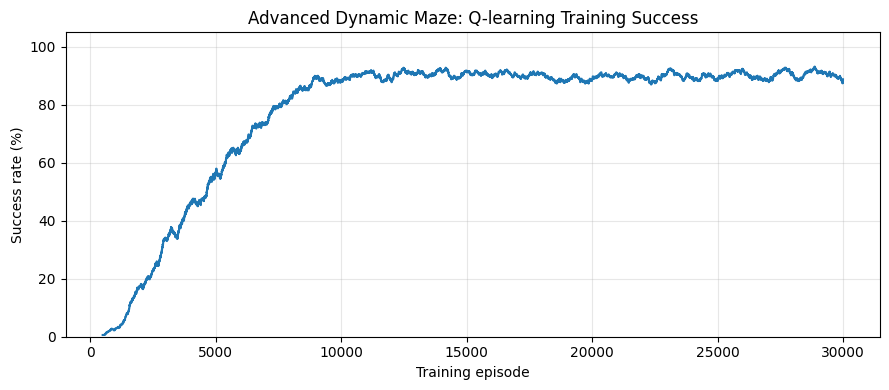

In [46]:

# Section 10.7: Train Q-learning in the advanced dynamic maze

import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------------
# 1. Environment and training configuration
# -----------------------------------------

advanced_train_env = AdvancedDynamicMazeEnv(max_steps=100)

EPISODES = 30000
ALPHA = 0.15
GAMMA = 0.97

EPSILON_START = 1.0
EPSILON_MIN = 0.05
EPSILON_DECAY = 0.9997

rng = np.random.default_rng(42)

# New Q-table, separate from the earlier simple maze
q_table_advanced = np.zeros((
    advanced_train_env.observation_space.n,
    advanced_train_env.action_space.n
))

training_rewards_advanced = []
training_successes_advanced = []
training_collisions_advanced = []
training_steps_advanced = []

epsilon = EPSILON_START

# -----------------------------------------
# 2. Q-learning training
# -----------------------------------------

for episode in range(EPISODES):

    # Randomize the obstacle's starting phase
    starting_phase = int(
        rng.integers(advanced_train_env.period)
    )

    state, _ = advanced_train_env.reset(
        options={"phase": starting_phase}
    )

    total_reward = 0.0
    collisions = 0
    success = False
    steps_taken = 0

    for step in range(advanced_train_env.max_steps):

        # Epsilon-greedy exploration
        if rng.random() < epsilon:
            action = int(
                rng.integers(advanced_train_env.action_space.n)
            )
        else:
            # Random tie-breaking between equally valued actions
            action_values = q_table_advanced[state]
            best_actions = np.flatnonzero(
                np.isclose(action_values, action_values.max())
            )
            action = int(rng.choice(best_actions))

        next_state, reward, terminated, truncated, info = (
            advanced_train_env.step(action)
        )

        # No bootstrapping from terminal or truncated states
        if terminated or truncated:
            target = reward
        else:
            target = reward + GAMMA * np.max(
                q_table_advanced[next_state]
            )

        q_table_advanced[state, action] += ALPHA * (
            target - q_table_advanced[state, action]
        )

        total_reward += reward
        collisions += int(info["collision"])
        steps_taken = step + 1

        state = next_state

        if terminated or truncated:
            success = bool(info["success"])
            break

    training_rewards_advanced.append(total_reward)
    training_successes_advanced.append(int(success))
    training_collisions_advanced.append(collisions)
    training_steps_advanced.append(steps_taken)

    epsilon = max(
        EPSILON_MIN,
        epsilon * EPSILON_DECAY
    )

    if (episode + 1) % 5000 == 0:
        recent_success = 100 * np.mean(
            training_successes_advanced[-5000:]
        )

        recent_reward = np.mean(
            training_rewards_advanced[-5000:]
        )

        recent_collisions = np.mean(
            training_collisions_advanced[-5000:]
        )

        print(
            f"Episode {episode + 1:5d} | "
            f"Success: {recent_success:6.2f}% | "
            f"Avg reward: {recent_reward:7.2f} | "
            f"Avg collisions: {recent_collisions:5.2f} | "
            f"Epsilon: {epsilon:.3f}"
        )

print("\nADVANCED Q-LEARNING TRAINING COMPLETED")
print("Q-table shape:", q_table_advanced.shape)
print("Final epsilon:", round(epsilon, 4))


# -----------------------------------------
# 3. Evaluate on all six starting phases
# -----------------------------------------

print("\nADVANCED Q-LEARNING EVALUATION")
print("-" * 75)

evaluation_results_advanced = []

for phase in range(advanced_train_env.period):

    eval_env = AdvancedDynamicMazeEnv(max_steps=100)

    state, _ = eval_env.reset(
        options={"phase": phase}
    )

    route = [eval_env.position]
    actions_taken = []
    collisions = 0
    success = False
    hit_by_wall = False

    for step in range(eval_env.max_steps):

        # Greedy evaluation: no exploration
        action = int(np.argmax(
            q_table_advanced[state]
        ))

        next_state, reward, terminated, truncated, info = (
            eval_env.step(action)
        )

        collisions += int(info["collision"])
        hit_by_wall = (
            hit_by_wall or bool(info["hit_by_wall"])
        )

        actions_taken.append(action)
        route.append(eval_env.position)

        state = next_state

        if terminated or truncated:
            success = bool(info["success"])
            break

    result = {
        "phase": phase,
        "success": success,
        "steps": len(actions_taken),
        "collisions": collisions,
        "hit_by_wall": hit_by_wall,
        "wait_actions": actions_taken.count(4),
        "route": route,
        "actions": actions_taken
    }

    evaluation_results_advanced.append(result)

    print(
        f"Phase {phase} | "
        f"Success={success} | "
        f"Steps={len(actions_taken):3d} | "
        f"Collisions={collisions:2d} | "
        f"WAIT={actions_taken.count(4):2d}"
    )


# -----------------------------------------
# 4. Summary
# -----------------------------------------

success_count = sum(
    int(r["success"])
    for r in evaluation_results_advanced
)

successful_results = [
    r for r in evaluation_results_advanced
    if r["success"]
]

success_rate = (
    100 * success_count /
    len(evaluation_results_advanced)
)

average_steps = (
    np.mean([r["steps"] for r in successful_results])
    if successful_results else float("nan")
)

average_collisions = np.mean([
    r["collisions"]
    for r in evaluation_results_advanced
])

print("\nEVALUATION SUMMARY")
print("-" * 50)
print(f"Starting phases tested: {len(evaluation_results_advanced)}")
print(f"Success rate: {success_rate:.2f}%")
print(f"Average successful steps: {average_steps:.2f}")
print(f"Average collisions: {average_collisions:.2f}")

print("\nEXAMPLE ROUTE (PHASE 0)")
print("Positions:", evaluation_results_advanced[0]["route"])
print(
    "Actions:",
    [
        ACTION_NAMES[a]
        for a in evaluation_results_advanced[0]["actions"]
    ]
)


# -----------------------------------------
# 5. Plot training progress
# -----------------------------------------

window = 500

smoothed_success = np.convolve(
    training_successes_advanced,
    np.ones(window) / window,
    mode="valid"
) * 100

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(
    np.arange(window, EPISODES + 1),
    smoothed_success,
    linewidth=1.5
)

ax.set_title(
    "Advanced Dynamic Maze: Q-learning Training Success"
)
ax.set_xlabel("Training episode")
ax.set_ylabel("Success rate (%)")
ax.set_ylim(0, 105)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [47]:

# Section 10.8: Advanced dynamic maze - Q-learning vs BFS

from collections import deque
import numpy as np

METHODS_ADVANCED = [
    "Q-learning",
    "Fixed BFS",
    "Replanning BFS"
]


def static_bfs_route(env):
    """
    Compute a shortest route using permanent walls only.
    Moving obstacles are ignored.
    """
    queue = deque([(env.start, [])])
    visited = {env.start}
    expansions = 0

    while queue:
        position, actions = queue.popleft()
        expansions += 1

        if position == env.goal:
            return actions, expansions

        for action, (dr, dc) in enumerate(env.DIRECTIONS[:4]):
            target = (position[0] + dr, position[1] + dc)
            r, c = target

            if not (0 <= r < env.rows and 0 <= c < env.cols):
                continue

            if env.maze[r][c] == "#":
                continue

            if target not in visited:
                visited.add(target)
                queue.append((target, actions + [action]))

    return None, expansions



def run_advanced_comparison_episode(method, starting_phase):
    env = AdvancedDynamicMazeEnv(max_steps=100)
    state, _ = env.reset(options={"phase": starting_phase})

    route = [env.position]
    actions_taken = []
    collisions = 0
    expansions = 0
    success = False

    fixed_plan = None
    plan_index = 0

    if method == "Fixed BFS":
        fixed_plan, count = static_bfs_route(env)
        expansions += count

    for _ in range(env.max_steps):

        if method == "Q-learning":
            action = int(np.argmax(q_table_advanced[state]))

        elif method == "Fixed BFS":
            if fixed_plan is None or plan_index >= len(fixed_plan):
                break

            action = fixed_plan[plan_index]
            plan_index += 1

        elif method == "Replanning BFS":
            # Plan from the agent's CURRENT position.
            original_start = env.start
            env.start = env.position

            try:
                plan, count = find_safe_route(env, env.phase)
            finally:
                env.start = original_start

            expansions += count

            if not plan:
                break

            action = plan[0]

        else:
            raise ValueError(f"Unknown method: {method}")

        state, reward, terminated, truncated, info = env.step(action)

        actions_taken.append(action)
        route.append(env.position)
        collisions += int(info["collision"])

        if terminated or truncated:
            success = bool(info["success"])
            break

    return {
        "method": method,
        "phase": starting_phase,
        "success": success,
        "steps": len(actions_taken),
        "collisions": collisions,
        "expansions": expansions,
        "waits": actions_taken.count(4),
        "route": route,
        "actions": actions_taken,
    }



advanced_comparison_results = []

for method in METHODS_ADVANCED:
    for phase in range(6):
        result = run_advanced_comparison_episode(method, phase)
        advanced_comparison_results.append(result)


print("ADVANCED DYNAMIC OBSTACLE COMPARISON")
print("-" * 90)

print(
    f"{'Method':<18} {'Success':>10} "
    f"{'Avg steps*':>12} {'Avg collisions':>16} "
    f"{'Avg expansions':>17}"
)

print("-" * 90)

for method in METHODS_ADVANCED:
    rows = [
        r for r in advanced_comparison_results
        if r["method"] == method
    ]

    successful = [r for r in rows if r["success"]]

    success_rate = 100 * len(successful) / len(rows)

    avg_steps = (
        np.mean([r["steps"] for r in successful])
        if successful else float("nan")
    )

    avg_collisions = np.mean([
        r["collisions"] for r in rows
    ])

    avg_expansions = np.mean([
        r["expansions"] for r in rows
    ])

    print(
        f"{method:<18} "
        f"{success_rate:>9.2f}% "
        f"{avg_steps:>12.2f} "
        f"{avg_collisions:>16.2f} "
        f"{avg_expansions:>17.2f}"
    )


print("\n* Average steps are calculated for successful episodes only.")
print("  Q-learning expansions exclude its earlier training cost.")

print("\nPER-PHASE RESULTS")
print("-" * 90)

for phase in range(6):
    print(f"\nStarting phase {phase}")

    for method in METHODS_ADVANCED:
        r = next(
            item for item in advanced_comparison_results
            if item["method"] == method
            and item["phase"] == phase
        )

        print(
            f"  {method:<16} "
            f"Success={str(r['success']):<5} "
            f"Steps={r['steps']:<3} "
            f"Collisions={r['collisions']:<3} "
            f"Expansions={r['expansions']}"
        )


ADVANCED DYNAMIC OBSTACLE COMPARISON
------------------------------------------------------------------------------------------
Method                Success   Avg steps*   Avg collisions    Avg expansions
------------------------------------------------------------------------------------------
Q-learning            100.00%        11.50             0.00              0.00
Fixed BFS              33.33%        10.00             3.33             28.00
Replanning BFS        100.00%        11.00             0.00            475.00

* Average steps are calculated for successful episodes only.
  Q-learning expansions exclude its earlier training cost.

PER-PHASE RESULTS
------------------------------------------------------------------------------------------

Starting phase 0
  Q-learning       Success=True  Steps=10  Collisions=0   Expansions=0
  Fixed BFS        Success=True  Steps=10  Collisions=0   Expansions=28
  Replanning BFS   Success=True  Steps=10  Collisions=0   Expansions=374

Sta

In [48]:

# Section 10.9: Advanced dynamic maze animation
# Compare Q-learning, Fixed BFS and Replanning BFS
# Starting phase 2: Fixed BFS fails; the others succeed.

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import ListedColormap, BoundaryNorm
from IPython.display import HTML, display

STARTING_PHASE = 2
ANIMATION_INTERVAL = 650

METHODS = ["Q-learning", "Fixed BFS", "Replanning BFS"]


def record_advanced_episode(method, starting_phase):
    env = AdvancedDynamicMazeEnv(max_steps=100)
    state, _ = env.reset(options={"phase": starting_phase})

    history = [{
        "position": tuple(env.position),
        "obstacles": list(env.get_obstacles()),
        "action": "START",
        "collision": False,
        "success": False,
        "done": False,
    }]

    fixed_plan = None
    plan_index = 0

    if method == "Fixed BFS":
        fixed_plan, _ = static_bfs_route(env)

    for _ in range(env.max_steps):

        if method == "Q-learning":
            action = int(np.argmax(q_table_advanced[state]))

        elif method == "Fixed BFS":
            if fixed_plan is None or plan_index >= len(fixed_plan):
                break

            action = fixed_plan[plan_index]
            plan_index += 1

        elif method == "Replanning BFS":
            original_start = env.start
            env.start = env.position

            try:
                plan, _ = find_safe_route(env, env.phase)
            finally:
                env.start = original_start

            if not plan:
                break

            action = plan[0]

        else:
            raise ValueError("Unknown algorithm")

        state, reward, terminated, truncated, info = env.step(
            action
        )

        history.append({
            "position": tuple(env.position),
            "obstacles": list(env.get_obstacles()),
            "action": ACTION_NAMES[action],
            "collision": bool(info["collision"]),
            "success": bool(info["success"]),
            "done": bool(terminated or truncated),
        })

        if terminated or truncated:
            break

    return history


# -----------------------------------------
# Record all three algorithm trajectories
# -----------------------------------------

histories = {
    method: record_advanced_episode(method, STARTING_PHASE)
    for method in METHODS
}

max_frames = max(len(h) for h in histories.values())


# -----------------------------------------
# Compact three-panel figure
# -----------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(10.5, 3.8),
    constrained_layout=True
)

# 0 = floor
# 1 = permanent wall
# 2 = moving obstacle
# 3 = agent
# 4 = goal

cmap = ListedColormap([
    "#f8fafc",
    "#475569",
    "#f97316",
    "#22c55e",
    "#ef4444",
])

norm = BoundaryNorm(
    np.arange(-0.5, 5.5, 1),
    cmap.N
)

images = []
status_labels = []

reference_env = AdvancedDynamicMazeEnv()

for ax, method in zip(axes, METHODS):

    grid = np.zeros(
        (reference_env.rows, reference_env.cols),
        dtype=int
    )

    image = ax.imshow(
        grid,
        cmap=cmap,
        norm=norm,
        interpolation="nearest"
    )

    ax.set_title(
        method,
        fontsize=10,
        fontweight="bold",
        pad=8
    )

    ax.set_xticks(range(reference_env.cols))
    ax.set_yticks(range(reference_env.rows))

    ax.tick_params(
        axis="both",
        labelsize=6,
        length=0
    )

    ax.set_xticks(
        np.arange(-0.5, reference_env.cols, 1),
        minor=True
    )
    ax.set_yticks(
        np.arange(-0.5, reference_env.rows, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="#cbd5e1",
        linewidth=0.5
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )

    status = ax.set_xlabel(
        "Step 0 | START",
        fontsize=8,
        labelpad=5
    )

    images.append(image)
    status_labels.append(status)


# -----------------------------------------
# Animation update function
# -----------------------------------------

def update(frame):

    for image, label, method in zip(
        images, status_labels, METHODS
    ):

        history = histories[method]
        index = min(frame, len(history) - 1)
        current = history[index]

        grid = np.zeros(
            (reference_env.rows, reference_env.cols),
            dtype=int
        )

        # Permanent walls
        for r in range(reference_env.rows):
            for c in range(reference_env.cols):
                if reference_env.maze[r][c] == "#":
                    grid[r, c] = 1

        # Goal
        gr, gc = reference_env.goal
        grid[gr, gc] = 4

        # Moving obstacles
        for r, c in current["obstacles"]:
            grid[r, c] = 2

        # Agent
        ar, ac = current["position"]
        grid[ar, ac] = 3

        image.set_data(grid)

        if current["success"]:
            status = "GOAL REACHED"
        elif current["collision"]:
            status = "COLLISION"
        elif frame >= len(history) - 1:
            status = "FAILED / STOPPED"
        elif current["action"] == "WAIT":
            status = "WAITING"
        else:
            status = current["action"]

        label.set_text(
            f"Step {index} | {status}"
        )

    return images + status_labels


animation = FuncAnimation(
    fig,
    update,
    frames=max_frames,
    interval=ANIMATION_INTERVAL,
    repeat=True,
    blit=False
)

plt.close(fig)

display(
    HTML(animation.to_jshtml(fps=2))
)


# -----------------------------------------
# Final animation summary
# -----------------------------------------

print("\nADVANCED ANIMATION SUMMARY")
print("Starting obstacle phase:", STARTING_PHASE)
print("-" * 75)

for method, history in histories.items():

    success = history[-1]["success"]

    collisions = sum(
        int(item["collision"])
        for item in history
    )

    waits = sum(
        item["action"] == "WAIT"
        for item in history
    )

    print(
        f"{method:<17} | "
        f"Steps={len(history)-1:<3} | "
        f"Success={str(success):<5} | "
        f"Collisions={collisions:<2} | "
        f"WAIT={waits}"
    )



ADVANCED ANIMATION SUMMARY
Starting obstacle phase: 2
---------------------------------------------------------------------------
Q-learning        | Steps=12  | Success=True  | Collisions=0  | WAIT=2
Fixed BFS         | Steps=10  | Success=False | Collisions=5  | WAIT=0
Replanning BFS    | Steps=11  | Success=True  | Collisions=0  | WAIT=1


### 14.10 — Unpredictable Moving Obstacles

This experiment investigates navigation in a stochastic
environment where moving obstacles change positions randomly.

Unlike the previous deterministic maze, the agent cannot
predict the exact next obstacle positions.

The objective is to compare Q-learning against classical
BFS-based navigation under uncertainty.

In [49]:

# Section 14.11: Stochastic moving-obstacle environment

import numpy as np
import gymnasium as gym
from gymnasium import spaces


class StochasticDynamicMazeEnv(gym.Env):
    """
    Advanced maze with three randomly moving obstacles.

    The agent observes its position and the CURRENT positions
    of all three obstacles, but not their next positions.

    Actions:
      0 UP
      1 RIGHT
      2 DOWN
      3 LEFT
      4 WAIT

    Obstacle movement is stochastic and sampled after
    the agent selects an action.
    """

    DIRECTIONS = [
        (-1, 0),
        (0, 1),
        (1, 0),
        (0, -1),
        (0, 0),
    ]

    def __init__(self, max_steps=100):
        super().__init__()

        self.maze = [
            "#########",
            "#S......#",
            "#.###.#.#",
            "#...#...#",
            "#.#...#.#",
            "#......G#",
            "#########",
        ]

        self.rows = len(self.maze)
        self.cols = len(self.maze[0])

        self.start = (1, 1)
        self.goal = (5, 7)

        # Each obstacle has a fixed track, but its movement
        # along that track is unpredictable.
        self.obstacle_tracks = [
            [(1, 3), (1, 4), (1, 5)],
            [(5, 5), (5, 4), (5, 3)],
            [(3, 5), (4, 5)],
        ]

        self.track_lengths = [
            len(track) for track in self.obstacle_tracks
        ]

        # Number of possible obstacle configurations
        self.config_count = int(
            np.prod(self.track_lengths)
        )

        self.action_space = spaces.Discrete(5)

        # Encode agent position and all obstacle indices
        self.observation_space = spaces.Discrete(
            self.rows * self.cols * self.config_count
        )

        self.max_steps = max_steps

        self.reset()

    def get_obstacles(self):
        return [
            track[index]
            for track, index in zip(
                self.obstacle_tracks,
                self.obstacle_indices
            )
        ]

    def get_state(self):
        row, col = self.position
        cell_id = row * self.cols + col

        config_id = 0
        multiplier = 1

        for index, length in zip(
            self.obstacle_indices,
            self.track_lengths
        ):
            config_id += index * multiplier
            multiplier *= length

        return cell_id * self.config_count + config_id

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)

        options = options or {}

        self.position = self.start
        self.steps = 0

        if "obstacle_indices" in options:
            indices = list(options["obstacle_indices"])

            if len(indices) != len(self.obstacle_tracks):
                raise ValueError("Incorrect obstacle count")

            for index, length in zip(
                indices, self.track_lengths
            ):
                if not 0 <= index < length:
                    raise ValueError("Invalid obstacle index")

            self.obstacle_indices = indices

        else:
            self.obstacle_indices = [
                int(self.np_random.integers(length))
                for length in self.track_lengths
            ]

        return self.get_state(), {}

    def step(self, action):
        if not self.action_space.contains(action):
            raise ValueError("Invalid action")

        dr, dc = self.DIRECTIONS[int(action)]

        row, col = self.position
        target = (row + dr, col + dc)

        current_obstacles = set(self.get_obstacles())

        # Each obstacle randomly stays, moves forward,
        # or moves backward along its track.
        new_indices = []

        for index, length in zip(
            self.obstacle_indices,
            self.track_lengths
        ):
            movement = int(
                self.np_random.choice([-1, 0, 1])
            )

            new_indices.append(
                (index + movement) % length
            )

        next_obstacles = {
            track[index]
            for track, index in zip(
                self.obstacle_tracks,
                new_indices
            )
        }

        collision = False
        reward = -1.0

        # Permanent wall or currently occupied cell
        invalid_move = (
            not (0 <= target[0] < self.rows)
            or not (0 <= target[1] < self.cols)
            or (
                0 <= target[0] < self.rows
                and 0 <= target[1] < self.cols
                and self.maze[target[0]][target[1]] == "#"
            )
            or target in current_obstacles
        )

        if invalid_move:
            collision = True
            reward = -5.0
            next_position = self.position
        else:
            next_position = target

        # An obstacle may randomly move into the agent's cell.
        hit_by_obstacle = next_position in next_obstacles

        if hit_by_obstacle:
            collision = True
            reward = -20.0

        self.position = next_position
        self.obstacle_indices = new_indices
        self.steps += 1

        success = self.position == self.goal

        terminated = success or hit_by_obstacle
        truncated = (
            self.steps >= self.max_steps and not terminated
        )

        if success:
            reward = 100.0

        return (
            self.get_state(),
            reward,
            terminated,
            truncated,
            {
                "collision": collision,
                "hit_by_obstacle": hit_by_obstacle,
                "success": success,
                "position": self.position,
                "obstacles": self.get_obstacles(),
                "obstacle_indices": list(
                    self.obstacle_indices
                ),
            },
        )

    def render(self):
        grid = [list(row) for row in self.maze]

        for row, col in self.get_obstacles():
            grid[row][col] = "X"

        row, col = self.position
        grid[row][col] = "A"

        print("\n".join(" ".join(row) for row in grid))
        print("Agent:", self.position)
        print("Moving obstacles:", self.get_obstacles())
        print("Obstacle indices:", self.obstacle_indices)
        print()


# -----------------------------------------
# Test stochastic obstacle movement
# -----------------------------------------

stochastic_env = StochasticDynamicMazeEnv(max_steps=100)

state, _ = stochastic_env.reset(seed=42)

print("STOCHASTIC DYNAMIC MAZE")
print("Maze dimensions:", stochastic_env.rows, "x", stochastic_env.cols)
print("Moving obstacles:", len(stochastic_env.obstacle_tracks))
print("Obstacle configurations:", stochastic_env.config_count)
print("State space size:", stochastic_env.observation_space.n)
print("Available actions:", stochastic_env.action_space.n)

print("\nINITIAL MAZE")
stochastic_env.render()

for step in range(5):
    # WAIT to observe obstacle movement
    state, reward, terminated, truncated, info = (
        stochastic_env.step(4)
    )

    print(f"AFTER WAIT {step + 1}")
    print("Reward:", reward)
    print("Collision:", info["collision"])
    stochastic_env.render()

    if terminated or truncated:
        break


STOCHASTIC DYNAMIC MAZE
Maze dimensions: 7 x 9
Moving obstacles: 3
Obstacle configurations: 18
State space size: 1134
Available actions: 5

INITIAL MAZE
# # # # # # # # #
# A . X . . . . #
# . # # # . # . #
# . . . # . . . #
# . # . . X # . #
# . . X . . . G #
# # # # # # # # #
Agent: (1, 1)
Moving obstacles: [(1, 3), (5, 3), (4, 5)]
Obstacle indices: [0, 2, 1]

AFTER WAIT 1
Reward: -1.0
Collision: False
# # # # # # # # #
# A . X . . . . #
# . # # # . # . #
# . . . # X . . #
# . # . . . # . #
# . . X . . . G #
# # # # # # # # #
Agent: (1, 1)
Moving obstacles: [(1, 3), (5, 3), (3, 5)]
Obstacle indices: [0, 2, 0]

AFTER WAIT 2
Reward: -1.0
Collision: False
# # # # # # # # #
# A . . . X . . #
# . # # # . # . #
# . . . # . . . #
# . # . . X # . #
# . . . . X . G #
# # # # # # # # #
Agent: (1, 1)
Moving obstacles: [(1, 5), (5, 5), (4, 5)]
Obstacle indices: [2, 0, 1]

AFTER WAIT 3
Reward: -1.0
Collision: False
# # # # # # # # #
# A . . X . . . #
# . # # # . # . #
# . . . # X . . #
# . # . . 

In [50]:

# Section 14.12: Validate stochastic maze behavior

import numpy as np
from itertools import product
from collections import deque

# ---------------------------------------------
# Test 1: Validate all obstacle configurations
# ---------------------------------------------

env = StochasticDynamicMazeEnv(max_steps=100)

configurations = list(product(
    *[range(n) for n in env.track_lengths]
))

encoded_states = set()
valid_configs = True

for indices in configurations:
    state, _ = env.reset(
        seed=42,
        options={"obstacle_indices": list(indices)}
    )

    obstacles = env.get_obstacles()
    encoded_states.add(state)

    if len(set(obstacles)) != 3:
        valid_configs = False

    for r, c in obstacles:
        if env.maze[r][c] == "#":
            valid_configs = False

        if (r, c) in (env.start, env.goal):
            valid_configs = False

print("TEST 1: OBSTACLE CONFIGURATIONS")
print("Configurations tested:", len(configurations))
print("Unique encoded starting states:", len(encoded_states))
print("All configurations valid:", valid_configs)

assert valid_configs
assert len(encoded_states) == env.config_count


# ---------------------------------------------
# Test 2: Reproducibility with random seeds
# ---------------------------------------------

def collect_obstacle_sequence(seed, steps=15):
    test_env = StochasticDynamicMazeEnv(max_steps=100)
    test_env.reset(seed=seed)

    sequence = [tuple(test_env.obstacle_indices)]

    for _ in range(steps):
        _, _, terminated, truncated, _ = test_env.step(4)

        sequence.append(tuple(test_env.obstacle_indices))

        if terminated or truncated:
            break

    return sequence


sequence_a = collect_obstacle_sequence(42)
sequence_b = collect_obstacle_sequence(42)
sequence_c = collect_obstacle_sequence(123)

print("\nTEST 2: RANDOM SEED REPRODUCIBILITY")
print("Same seed gives same sequence:", sequence_a == sequence_b)
print("Different seeds give different sequences:", sequence_a != sequence_c)

assert sequence_a == sequence_b


# ---------------------------------------------
# Test 3: Verify permanent wall collision
# ---------------------------------------------

wall_env = StochasticDynamicMazeEnv(max_steps=100)

wall_env.reset(
    seed=42,
    options={"obstacle_indices": [0, 0, 0]}
)

# Starting position is (1,1).
# Moving UP attempts to enter permanent wall (0,1).
_, reward, terminated, truncated, info = wall_env.step(0)

print("\nTEST 3: PERMANENT WALL COLLISION")
print("Agent position:", wall_env.position)
print("Collision detected:", info["collision"])
print("Reward:", reward)
print("Episode terminated:", terminated)

assert wall_env.position == (1, 1)
assert info["collision"] is True
assert reward == -5.0
assert terminated is False


# ---------------------------------------------
# Test 4: Verify moving obstacle collision
# ---------------------------------------------

# Place obstacle 1 at (1,3).
# Move the agent to (1,2), then attempt to move
# RIGHT into the obstacle while it is still there.
#
# Search reproducibly for a random seed where
# this particular collision occurs.

collision_found = False
collision_seed = None
collision_result = None

for seed in range(1000):
    test_env = StochasticDynamicMazeEnv(max_steps=100)

    test_env.reset(
        seed=seed,
        options={"obstacle_indices": [0, 0, 0]}
    )

    # Move from (1,1) to (1,2)
    _, _, terminated, truncated, _ = test_env.step(1)

    if terminated or truncated:
        continue

    # Attempt to enter (1,3) when currently occupied
    if (1, 3) not in test_env.get_obstacles():
        continue

    _, reward, terminated, truncated, info = test_env.step(1)

    if info["collision"]:
        collision_found = True
        collision_seed = seed
        collision_result = {
            "position": test_env.position,
            "reward": reward,
            "collision": info["collision"],
        }
        break

print("\nTEST 4: MOVING OBSTACLE COLLISION")
print("Collision scenario found:", collision_found)
print("Example seed:", collision_seed)
print("Result:", collision_result)

assert collision_found, "No collision test scenario found"


# ---------------------------------------------
# Test 5: Check static maze reachability
# ---------------------------------------------

# Ignore moving obstacles temporarily to confirm
# permanent walls do not disconnect start and goal.

def static_reachability(env):
    queue = deque([(env.start, 0)])
    visited = {env.start}

    directions = env.DIRECTIONS[:4]

    while queue:
        position, distance = queue.popleft()

        if position == env.goal:
            return True, distance

        for dr, dc in directions:
            target = (
                position[0] + dr,
                position[1] + dc
            )

            r, c = target

            if not (0 <= r < env.rows and 0 <= c < env.cols):
                continue

            if env.maze[r][c] == "#":
                continue

            if target in visited:
                continue

            visited.add(target)
            queue.append((target, distance + 1))

    return False, None


reachable, shortest_distance = static_reachability(env)

print("\nTEST 5: STATIC MAZE REACHABILITY")
print("Goal reachable without moving obstacles:", reachable)
print("Static shortest path length:", shortest_distance)

assert reachable


# ---------------------------------------------
# Final validation summary
# ---------------------------------------------

print("\nSTOCHASTIC ENVIRONMENT VALIDATION")
print("-" * 55)
print("Configuration test: PASSED")
print("Random seed test: PASSED")
print("Permanent wall collision test: PASSED")
print("Moving obstacle collision test: PASSED")
print("Static reachability test: PASSED")
print("\nBasic environment validation completed.")


TEST 1: OBSTACLE CONFIGURATIONS
Configurations tested: 18
Unique encoded starting states: 18
All configurations valid: True

TEST 2: RANDOM SEED REPRODUCIBILITY
Same seed gives same sequence: True
Different seeds give different sequences: True

TEST 3: PERMANENT WALL COLLISION
Agent position: (1, 1)
Collision detected: True
Reward: -5.0
Episode terminated: False

TEST 4: MOVING OBSTACLE COLLISION
Collision scenario found: True
Example seed: 1
Result: {'position': (1, 2), 'reward': -5.0, 'collision': True}

TEST 5: STATIC MAZE REACHABILITY
Goal reachable without moving obstacles: True
Static shortest path length: 10

STOCHASTIC ENVIRONMENT VALIDATION
-------------------------------------------------------
Configuration test: PASSED
Random seed test: PASSED
Permanent wall collision test: PASSED
Moving obstacle collision test: PASSED
Static reachability test: PASSED

Basic environment validation completed.


Episode 10000 | Success:  12.00% | Avg reward:  -53.17 | Avg collisions:  6.59 | Epsilon: 0.223
Episode 20000 | Success:  26.59% | Avg reward:  -13.19 | Avg collisions:  1.77 | Epsilon: 0.050
Episode 30000 | Success:  29.27% | Avg reward:   -9.30 | Avg collisions:  1.29 | Epsilon: 0.050
Episode 40000 | Success:  29.38% | Avg reward:   -9.81 | Avg collisions:  1.22 | Epsilon: 0.050
Episode 50000 | Success:  28.30% | Avg reward:  -10.43 | Avg collisions:  1.22 | Epsilon: 0.050
Episode 60000 | Success:  29.17% | Avg reward:   -9.19 | Avg collisions:  1.19 | Epsilon: 0.050

STOCHASTIC Q-LEARNING TRAINING COMPLETED
Q-table shape: (1134, 5)
Final epsilon: 0.05

STOCHASTIC Q-LEARNING EVALUATION
-------------------------------------------------------
Test episodes: 500
Success rate: 29.00%
Average successful steps: 39.58
Average collisions: 0.61
Average reward: -27.11
Average WAIT actions: 16.22


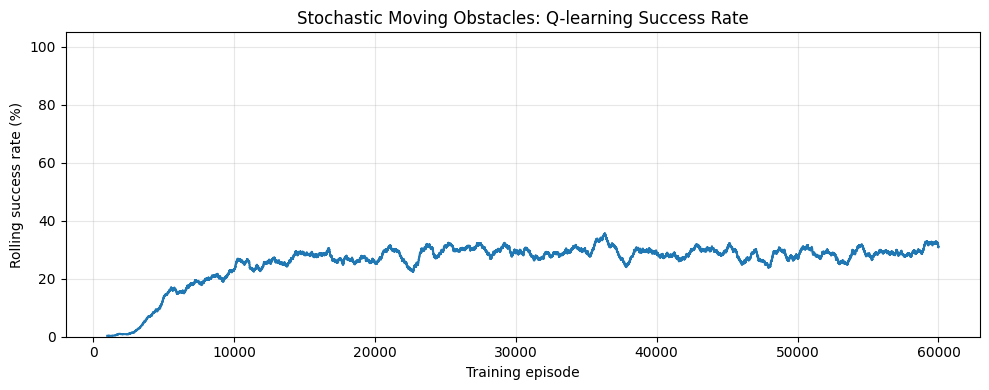

In [51]:

# Section 14.13: Q-learning training in the stochastic maze

import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------------
# 1. Training settings
# -----------------------------------------

stochastic_train_env = StochasticDynamicMazeEnv(max_steps=100)

EPISODES_10F = 60000
ALPHA_10F = 0.15
GAMMA_10F = 0.97

EPSILON_START_10F = 1.0
EPSILON_MIN_10F = 0.05
EPSILON_DECAY_10F = 0.99985

rng_10f = np.random.default_rng(42)

q_table_stochastic = np.zeros((
    stochastic_train_env.observation_space.n,
    stochastic_train_env.action_space.n
))

training_rewards_10f = []
training_successes_10f = []
training_collisions_10f = []
training_steps_10f = []

epsilon_10f = EPSILON_START_10F

# -----------------------------------------
# 2. Q-learning training
# -----------------------------------------

for episode in range(EPISODES_10F):

    # Different random scenario each episode
    episode_seed = int(rng_10f.integers(0, 2**31 - 1))

    state, _ = stochastic_train_env.reset(
        seed=episode_seed
    )

    total_reward = 0.0
    collisions = 0
    success = False
    steps_taken = 0

    for step in range(stochastic_train_env.max_steps):

        if rng_10f.random() < epsilon_10f:
            action = int(rng_10f.integers(5))
        else:
            values = q_table_stochastic[state]
            best_actions = np.flatnonzero(
                np.isclose(values, values.max())
            )
            action = int(rng_10f.choice(best_actions))

        next_state, reward, terminated, truncated, info = (
            stochastic_train_env.step(action)
        )

        # Q-learning update
        if terminated:
            target = reward
        elif truncated:
            target = reward
        else:
            target = reward + GAMMA_10F * np.max(
                q_table_stochastic[next_state]
            )

        q_table_stochastic[state, action] += ALPHA_10F * (
            target - q_table_stochastic[state, action]
        )

        total_reward += reward
        collisions += int(info["collision"])
        steps_taken = step + 1
        state = next_state

        if terminated or truncated:
            success = bool(info["success"])
            break

    training_rewards_10f.append(total_reward)
    training_successes_10f.append(int(success))
    training_collisions_10f.append(collisions)
    training_steps_10f.append(steps_taken)

    epsilon_10f = max(
        EPSILON_MIN_10F,
        epsilon_10f * EPSILON_DECAY_10F
    )

    if (episode + 1) % 10000 == 0:
        recent_success = np.mean(
            training_successes_10f[-10000:]
        ) * 100

        recent_reward = np.mean(
            training_rewards_10f[-10000:]
        )

        recent_collisions = np.mean(
            training_collisions_10f[-10000:]
        )

        print(
            f"Episode {episode + 1:5d} | "
            f"Success: {recent_success:6.2f}% | "
            f"Avg reward: {recent_reward:7.2f} | "
            f"Avg collisions: {recent_collisions:5.2f} | "
            f"Epsilon: {epsilon_10f:.3f}"
        )

print("\nSTOCHASTIC Q-LEARNING TRAINING COMPLETED")
print("Q-table shape:", q_table_stochastic.shape)
print("Final epsilon:", round(epsilon_10f, 4))


# -----------------------------------------
# 3. Evaluate trained policy
# -----------------------------------------

EVALUATION_EPISODES_10F = 500

evaluation_results_10f = []

for test_index in range(EVALUATION_EPISODES_10F):

    test_env = StochasticDynamicMazeEnv(max_steps=100)

    # Separate test seeds from training
    test_seed = 100000 + test_index

    state, _ = test_env.reset(seed=test_seed)

    total_reward = 0.0
    collisions = 0
    success = False
    actions_taken = []

    for step in range(test_env.max_steps):

        # Greedy policy, no exploration
        action = int(np.argmax(q_table_stochastic[state]))

        next_state, reward, terminated, truncated, info = (
            test_env.step(action)
        )

        total_reward += reward
        collisions += int(info["collision"])
        actions_taken.append(action)

        state = next_state

        if terminated or truncated:
            success = bool(info["success"])
            break

    evaluation_results_10f.append({
        "seed": test_seed,
        "success": success,
        "steps": len(actions_taken),
        "collisions": collisions,
        "reward": total_reward,
        "waits": actions_taken.count(4)
    })


# -----------------------------------------
# 4. Evaluation summary
# -----------------------------------------

successful_10f = [
    r for r in evaluation_results_10f
    if r["success"]
]

success_rate_10f = (
    100 * len(successful_10f) /
    EVALUATION_EPISODES_10F
)

avg_steps_10f = (
    np.mean([r["steps"] for r in successful_10f])
    if successful_10f else float("nan")
)

avg_collisions_10f = np.mean([
    r["collisions"]
    for r in evaluation_results_10f
])

avg_reward_10f = np.mean([
    r["reward"]
    for r in evaluation_results_10f
])

avg_waits_10f = np.mean([
    r["waits"]
    for r in evaluation_results_10f
])

print("\nSTOCHASTIC Q-LEARNING EVALUATION")
print("-" * 55)
print("Test episodes:", EVALUATION_EPISODES_10F)
print(f"Success rate: {success_rate_10f:.2f}%")
print(f"Average successful steps: {avg_steps_10f:.2f}")
print(f"Average collisions: {avg_collisions_10f:.2f}")
print(f"Average reward: {avg_reward_10f:.2f}")
print(f"Average WAIT actions: {avg_waits_10f:.2f}")


# -----------------------------------------
# 5. Training progress graph
# -----------------------------------------

window_10f = 1000

smoothed_success_10f = np.convolve(
    training_successes_10f,
    np.ones(window_10f) / window_10f,
    mode="valid"
) * 100

fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(
    np.arange(window_10f, EPISODES_10F + 1),
    smoothed_success_10f,
    linewidth=1.5
)

ax.set_title(
    "Stochastic Moving Obstacles: Q-learning Success Rate"
)
ax.set_xlabel("Training episode")
ax.set_ylabel("Rolling success rate (%)")
ax.set_ylim(0, 105)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [52]:

# Section 14.14: Stochastic maze diagnostic comparison
# Q-learning vs Fixed BFS vs Reactive BFS

import numpy as np
from collections import deque

TEST_EPISODES_10F = 500
TEST_SEEDS_10F = list(range(100000, 100500))

METHODS_10F = [
    "Q-learning",
    "Fixed BFS",
    "Reactive BFS"
]


# -----------------------------------------
# 1. BFS pathfinding
# -----------------------------------------

def bfs_stochastic(env, start, blocked_cells=None):
    """
    Find a shortest path through the permanent maze.

    blocked_cells:
        Current moving-obstacle positions to avoid.

    BFS does not predict future random obstacle positions.
    """

    if blocked_cells is None:
        blocked_cells = set()

    blocked_cells = set(blocked_cells)

    queue = deque([(start, [])])
    visited = {start}

    expansions = 0

    while queue:
        position, actions = queue.popleft()
        expansions += 1

        if position == env.goal:
            return actions, expansions

        for action, (dr, dc) in enumerate(env.DIRECTIONS[:4]):

            target = (
                position[0] + dr,
                position[1] + dc
            )

            r, c = target

            if not (0 <= r < env.rows and
                    0 <= c < env.cols):
                continue

            if env.maze[r][c] == "#":
                continue

            if target in blocked_cells:
                continue

            if target in visited:
                continue

            visited.add(target)
            queue.append(
                (target, actions + [action])
            )

    return None, expansions


# -----------------------------------------
# 2. Run one evaluation episode
# -----------------------------------------

def evaluate_stochastic_method(method, seed):

    env = StochasticDynamicMazeEnv(max_steps=100)

    state, _ = env.reset(seed=seed)

    total_reward = 0.0
    collisions = 0
    success = False
    steps = 0
    expansions = 0
    waits = 0
    failure_reason = "step_limit"

    fixed_plan = None
    fixed_index = 0

    if method == "Fixed BFS":
        fixed_plan, count = bfs_stochastic(
            env,
            env.position
        )

        expansions += count

    for step in range(env.max_steps):

        if method == "Q-learning":

            action = int(
                np.argmax(q_table_stochastic[state])
            )

        elif method == "Fixed BFS":

            if fixed_plan is None:
                failure_reason = "no_path"
                break

            if fixed_index >= len(fixed_plan):
                failure_reason = "plan_exhausted"
                break

            action = fixed_plan[fixed_index]
            fixed_index += 1

        elif method == "Reactive BFS":

            # Recalculate path from CURRENT position,
            # avoiding currently observed obstacles.
            plan, count = bfs_stochastic(
                env,
                env.position,
                blocked_cells=env.get_obstacles()
            )

            expansions += count

            if plan is None:
                # No currently visible route:
                # wait and try replanning next step.
                action = 4

            elif len(plan) == 0:
                failure_reason = "already_at_goal"
                break

            else:
                action = plan[0]

        else:
            raise ValueError("Unknown method")

        state, reward, terminated, truncated, info = (
            env.step(action)
        )

        total_reward += reward
        collisions += int(info["collision"])
        waits += int(action == 4)
        steps = step + 1

        if terminated or truncated:

            success = bool(info["success"])

            if success:
                failure_reason = "success"
            elif info["hit_by_obstacle"]:
                failure_reason = "moving_obstacle_hit"
            elif truncated:
                failure_reason = "step_limit"
            else:
                failure_reason = "other_termination"

            break

    return {
        "method": method,
        "seed": seed,
        "success": success,
        "steps": steps,
        "collisions": collisions,
        "reward": total_reward,
        "waits": waits,
        "expansions": expansions,
        "failure_reason": failure_reason
    }


# -----------------------------------------
# 3. Run all 500 test seeds
# -----------------------------------------

comparison_results_10f = []

for method in METHODS_10F:

    for seed in TEST_SEEDS_10F:

        result = evaluate_stochastic_method(
            method, seed
        )

        comparison_results_10f.append(result)


# -----------------------------------------
# 4. Summary table
# -----------------------------------------

print("STOCHASTIC DYNAMIC OBSTACLE COMPARISON")
print("=" * 100)

print(
    f"{'Method':<16}"
    f"{'Success':>11}"
    f"{'Avg steps*':>13}"
    f"{'Collisions':>13}"
    f"{'Avg reward':>13}"
    f"{'BFS expansions':>17}"
)

print("-" * 100)

for method in METHODS_10F:

    rows = [
        r for r in comparison_results_10f
        if r["method"] == method
    ]

    successful = [
        r for r in rows
        if r["success"]
    ]

    success_rate = (
        100 * len(successful) / len(rows)
    )

    avg_steps = (
        np.mean([r["steps"] for r in successful])
        if successful else float("nan")
    )

    avg_collisions = np.mean([
        r["collisions"] for r in rows
    ])

    avg_reward = np.mean([
        r["reward"] for r in rows
    ])

    avg_expansions = np.mean([
        r["expansions"] for r in rows
    ])

    print(
        f"{method:<16}"
        f"{success_rate:>10.2f}%"
        f"{avg_steps:>13.2f}"
        f"{avg_collisions:>13.2f}"
        f"{avg_reward:>13.2f}"
        f"{avg_expansions:>17.2f}"
    )


print("\n* Average steps calculated for successful episodes only.")
print("  Q-learning BFS expansions exclude its training cost.")


# -----------------------------------------
# 5. Diagnose failure reasons
# -----------------------------------------

print("\nFAILURE DIAGNOSTICS")
print("=" * 70)

for method in METHODS_10F:

    rows = [
        r for r in comparison_results_10f
        if r["method"] == method
    ]

    failures = [
        r for r in rows
        if not r["success"]
    ]

    reasons = {}

    for r in failures:
        reason = r["failure_reason"]

        reasons[reason] = reasons.get(reason, 0) + 1

    print(f"\n{method}")
    print("Total failures:", len(failures))

    for reason, count in sorted(reasons.items()):
        print(f"  {reason}: {count}")


# -----------------------------------------
# 6. Compare WAIT behavior
# -----------------------------------------

print("\nWAIT ACTION COMPARISON")
print("=" * 70)

for method in METHODS_10F:

    rows = [
        r for r in comparison_results_10f
        if r["method"] == method
    ]

    avg_waits = np.mean([
        r["waits"] for r in rows
    ])

    print(
        f"{method:<16} "
        f"Average WAIT actions: {avg_waits:.2f}"
    )


# -----------------------------------------
# 7. Example matched-seed comparison
# -----------------------------------------

print("\nEXAMPLE TEST SCENARIOS")
print("=" * 70)

for seed in TEST_SEEDS_10F[:5]:

    print(f"\nTest seed: {seed}")

    for method in METHODS_10F:

        r = next(
            result for result in comparison_results_10f
            if result["method"] == method
            and result["seed"] == seed
        )

        print(
            f"  {method:<16} "
            f"Success={str(r['success']):<5} "
            f"Steps={r['steps']:<3} "
            f"Collisions={r['collisions']:<3} "
            f"Reward={r['reward']:.1f}"
        )


STOCHASTIC DYNAMIC OBSTACLE COMPARISON
Method              Success   Avg steps*   Collisions   Avg reward   BFS expansions
----------------------------------------------------------------------------------------------------
Q-learning           29.00%        39.58         0.61       -27.11             0.00
Fixed BFS             2.80%        10.00         2.24       -24.29            28.00
Reactive BFS         24.00%        17.68         0.76        -5.28           211.29

* Average steps calculated for successful episodes only.
  Q-learning BFS expansions exclude its training cost.

FAILURE DIAGNOSTICS

Q-learning
Total failures: 355
  moving_obstacle_hit: 304
  step_limit: 51

Fixed BFS
Total failures: 486
  moving_obstacle_hit: 453
  plan_exhausted: 33

Reactive BFS
Total failures: 380
  moving_obstacle_hit: 380

WAIT ACTION COMPARISON
Q-learning       Average WAIT actions: 16.22
Fixed BFS        Average WAIT actions: 0.00
Reactive BFS     Average WAIT actions: 7.27

EXAMPLE TEST SCE

In [53]:
# Section 14.15A: Select a stochastic animation scenario

# Find test seeds where Q-learning succeeds,
# while Fixed BFS and Reactive BFS both fail.

candidate_seeds = []

for seed in TEST_SEEDS_10F:

    results = {
        method: next(
            r for r in comparison_results_10f
            if r["method"] == method
            and r["seed"] == seed
        )
        for method in METHODS_10F
    }

    if (
        results["Q-learning"]["success"]
        and not results["Fixed BFS"]["success"]
        and not results["Reactive BFS"]["success"]
    ):
        candidate_seeds.append({
            "seed": seed,
            "q_steps": results["Q-learning"]["steps"],
            "q_collisions": results["Q-learning"]["collisions"],
            "fixed_steps": results["Fixed BFS"]["steps"],
            "reactive_steps": results["Reactive BFS"]["steps"]
        })


print("STOCHASTIC ANIMATION SCENARIO SELECTION")
print("-" * 65)

print(
    "Scenarios where Q-learning succeeds "
    "and both BFS methods fail:",
    len(candidate_seeds)
)

if candidate_seeds:

    # Choose the shortest successful Q-learning
    # episode to keep the animation manageable.
    candidate_seeds.sort(
        key=lambda x: x["q_steps"]
    )

    selected_scenario_10f = candidate_seeds[0]
    selected_seed_10f = selected_scenario_10f["seed"]

    print("\nSELECTED SCENARIO")
    print("Test seed:", selected_seed_10f)
    print("Q-learning steps:", selected_scenario_10f["q_steps"])
    print("Q-learning collisions:", selected_scenario_10f["q_collisions"])
    print("Fixed BFS steps:", selected_scenario_10f["fixed_steps"])
    print("Reactive BFS steps:", selected_scenario_10f["reactive_steps"])

    print("\nFIRST 10 CANDIDATES")
    for scenario in candidate_seeds[:10]:
        print(scenario)

else:
    selected_seed_10f = None
    print(
        "\nNo scenario matched all three conditions."
    )
    print(
        "We can choose a different representative "
        "scenario without changing the results."
    )


STOCHASTIC ANIMATION SCENARIO SELECTION
-----------------------------------------------------------------
Scenarios where Q-learning succeeds and both BFS methods fail: 109

SELECTED SCENARIO
Test seed: 100253
Q-learning steps: 10
Q-learning collisions: 0
Fixed BFS steps: 3
Reactive BFS steps: 7

FIRST 10 CANDIDATES
{'seed': 100253, 'q_steps': 10, 'q_collisions': 0, 'fixed_steps': 3, 'reactive_steps': 7}
{'seed': 100270, 'q_steps': 10, 'q_collisions': 0, 'fixed_steps': 4, 'reactive_steps': 12}
{'seed': 100412, 'q_steps': 10, 'q_collisions': 0, 'fixed_steps': 5, 'reactive_steps': 12}
{'seed': 100204, 'q_steps': 11, 'q_collisions': 0, 'fixed_steps': 10, 'reactive_steps': 11}
{'seed': 100260, 'q_steps': 11, 'q_collisions': 0, 'fixed_steps': 2, 'reactive_steps': 12}
{'seed': 100269, 'q_steps': 11, 'q_collisions': 0, 'fixed_steps': 5, 'reactive_steps': 9}
{'seed': 100048, 'q_steps': 13, 'q_collisions': 0, 'fixed_steps': 6, 'reactive_steps': 10}
{'seed': 100100, 'q_steps': 13, 'q_collisions'

In [54]:

# Section 14.15B: Side-by-side stochastic maze animation

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import ListedColormap
from IPython.display import HTML, display

# -----------------------------------------
# 1. Record each algorithm's actual episode
# -----------------------------------------

def record_stochastic_episode(method, seed):
    env = StochasticDynamicMazeEnv(max_steps=100)
    state, _ = env.reset(seed=seed)

    history = []
    total_reward = 0.0
    collisions = 0
    waits = 0
    success = False
    failure_reason = None

    def snapshot(action=None, reward=None, collision=False):
        return {
            "position": tuple(env.position),
            "obstacles": list(env.get_obstacles()),
            "action": action,
            "reward": reward,
            "collision": collision,
        }

    history.append(snapshot())

    fixed_plan = None
    fixed_index = 0

    if method == "Fixed BFS":
        fixed_plan, _ = bfs_stochastic(
            env, env.position
        )

    for step in range(env.max_steps):

        if method == "Q-learning":
            action = int(np.argmax(q_table_stochastic[state]))

        elif method == "Fixed BFS":
            if fixed_plan is None:
                failure_reason = "no_path"
                break

            if fixed_index >= len(fixed_plan):
                failure_reason = "plan_exhausted"
                break

            action = fixed_plan[fixed_index]
            fixed_index += 1

        elif method == "Reactive BFS":
            plan, _ = bfs_stochastic(
                env,
                env.position,
                blocked_cells=env.get_obstacles()
            )

            if plan is None:
                action = 4
            elif len(plan) == 0:
                failure_reason = "already_at_goal"
                break
            else:
                action = plan[0]

        else:
            raise ValueError("Unknown method")

        state, reward, terminated, truncated, info = (
            env.step(action)
        )

        total_reward += reward
        collisions += int(info["collision"])
        waits += int(action == 4)

        history.append(snapshot(
            action=action,
            reward=reward,
            collision=info["collision"]
        ))

        if terminated or truncated:
            success = bool(info["success"])

            if success:
                failure_reason = "success"
            elif info["hit_by_obstacle"]:
                failure_reason = "moving_obstacle_hit"
            elif truncated:
                failure_reason = "step_limit"
            else:
                failure_reason = "other_termination"

            break

    if failure_reason is None:
        failure_reason = "step_limit"

    return {
        "method": method,
        "seed": seed,
        "history": history,
        "success": success,
        "steps": len(history) - 1,
        "collisions": collisions,
        "waits": waits,
        "reward": total_reward,
        "failure_reason": failure_reason
    }


animation_seed_10f = selected_seed_10f

animation_runs_10f = {
    method: record_stochastic_episode(
        method, animation_seed_10f
    )
    for method in METHODS_10F
}

# Verify replay matches the earlier comparison
for method in METHODS_10F:
    recorded = animation_runs_10f[method]

    previous = next(
        r for r in comparison_results_10f
        if r["method"] == method
        and r["seed"] == animation_seed_10f
    )

    assert recorded["success"] == previous["success"]
    assert recorded["steps"] == previous["steps"]
    assert recorded["collisions"] == previous["collisions"]

print("REPLAY VALIDATION PASSED")
print("Selected seed:", animation_seed_10f)

for method, result in animation_runs_10f.items():
    print(
        f"{method:<15} "
        f"Success={result['success']} | "
        f"Steps={result['steps']} | "
        f"Collisions={result['collisions']}"
    )


# -----------------------------------------
# 2. Build maze background
# -----------------------------------------

reference_env = StochasticDynamicMazeEnv()

background = np.zeros((
    reference_env.rows,
    reference_env.cols
), dtype=int)

for r in range(reference_env.rows):
    for c in range(reference_env.cols):
        if reference_env.maze[r][c] == "#":
            background[r, c] = 1

maze_cmap = ListedColormap([
    "#f8fafc",  # Free cell
    "#475569"   # Permanent wall
])

ACTION_NAMES = [
    "UP", "RIGHT", "DOWN", "LEFT", "WAIT"
]

max_frames = max(
    len(result["history"])
    for result in animation_runs_10f.values()
)

# -----------------------------------------
# 3. Create three panels
# -----------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(12, 4.2),
    constrained_layout=True
)

def draw_frame(frame):

    for ax, method in zip(axes, METHODS_10F):

        ax.clear()

        result = animation_runs_10f[method]
        history = result["history"]

        index = min(frame, len(history) - 1)
        snapshot_data = history[index]

        ax.imshow(
            background,
            cmap=maze_cmap,
            vmin=0,
            vmax=1,
            interpolation="nearest"
        )

        # Grid lines
        ax.set_xticks(
            np.arange(-0.5, reference_env.cols, 1),
            minor=True
        )
        ax.set_yticks(
            np.arange(-0.5, reference_env.rows, 1),
            minor=True
        )

        ax.grid(
            which="minor",
            color="#cbd5e1",
            linewidth=0.5
        )

        ax.tick_params(
            which="minor",
            bottom=False,
            left=False
        )

        # Goal
        gr, gc = reference_env.goal
        ax.scatter(
            gc, gr,
            marker="s",
            s=330,
            color="#ef4444",
            zorder=3
        )

        # Moving obstacles
        for r, c in snapshot_data["obstacles"]:
            ax.scatter(
                c, r,
                marker="s",
                s=330,
                color="#f97316",
                zorder=4
            )

        # Agent
        ar, ac = snapshot_data["position"]
        ax.scatter(
            ac, ar,
            marker="s",
            s=280,
            color="#22c55e",
            edgecolors="white",
            linewidths=1,
            zorder=5
        )

        ax.set_xlim(-0.5, reference_env.cols - 0.5)
        ax.set_ylim(reference_env.rows - 0.5, -0.5)

        ax.set_xticks(range(reference_env.cols))
        ax.set_yticks(range(reference_env.rows))

        ax.tick_params(labelsize=7)

        # Action / status
        if index == 0:
            status = "START"
        else:
            action = snapshot_data["action"]
            status = ACTION_NAMES[action]

        if frame >= len(history) - 1:
            if result["success"]:
                status = "SUCCESS"
            else:
                status = "FAILED"

        ax.set_title(
            f"{method}\n"
            f"Step {index} | {status}",
            fontsize=10,
            fontweight="bold"
        )

    return axes


# -----------------------------------------
# 4. Display animation
# -----------------------------------------

animation_10f = FuncAnimation(
    fig,
    draw_frame,
    frames=max_frames,
    interval=700,
    repeat=True
)

plt.close(fig)

display(
    HTML(animation_10f.to_jshtml())
)


# -----------------------------------------
# 5. Final animation summary
# -----------------------------------------

print("\nSTOCHASTIC ANIMATION SUMMARY")
print("Selected test seed:", animation_seed_10f)
print("-" * 75)

for method, result in animation_runs_10f.items():

    print(
        f"{method:<15} | "
        f"Steps={result['steps']:<3} | "
        f"Success={str(result['success']):<5} | "
        f"Collisions={result['collisions']:<2} | "
        f"WAIT={result['waits']:<3}"
    )

    print(
        f"  Outcome: {result['failure_reason']}"
    )


REPLAY VALIDATION PASSED
Selected seed: 100253
Q-learning      Success=True | Steps=10 | Collisions=0
Fixed BFS       Success=False | Steps=3 | Collisions=2
Reactive BFS    Success=False | Steps=7 | Collisions=1



STOCHASTIC ANIMATION SUMMARY
Selected test seed: 100253
---------------------------------------------------------------------------
Q-learning      | Steps=10  | Success=True  | Collisions=0  | WAIT=0  
  Outcome: success
Fixed BFS       | Steps=3   | Success=False | Collisions=2  | WAIT=0  
  Outcome: moving_obstacle_hit
Reactive BFS    | Steps=7   | Success=False | Collisions=1  | WAIT=0  
  Outcome: moving_obstacle_hit


## 15. Notes for report and reproducibility

- **BFS** is the shortest-path benchmark; **A\*** and **online flood fill** are the classical comparison methods.
- **Predefined route** (Step 10C in Section 3) is a movement test, not evidence of learning.
- **Greedy evaluation** uses the learned Q-table without exploration.
- **Training success** depends heavily on ε; use greedy optimal-path rate and max |Q − Q\*| to compare learning rates.
- **Optimal path ≠ convergence:** Step 9C shows the greedy route becomes optimal well before Q matches Q\*.
- **ε confound:** with the fixed 0.999 decay, short training budgets also mean high exploration. Step 7E controls for this.
- **SARSA** uses the same `train()` function (`algorithm="sarsa"`); only the bootstrap term differs.
- **Generated mazes** are perfect mazes from recursive backtracking (seed 1); their step cap is 4 × cells instead of 100.
- **Reward design:** goal reward fixed at +100; wall and step penalties varied. Optimality is always judged by path length, not reward.
- **Truncation:** the update bootstraps on time-limit truncation and only zeroes future value on reaching the goal (Pardo et al., 2018).
- **Academic integrity:** disclose any GenAI assistance in the submitted report according to the module instructions.

**References**

- Sutton, R. S., & Barto, A. G. (2018). *Reinforcement Learning: An Introduction* (2nd ed.). MIT Press. Ch. 4 (value iteration), Ch. 6 (Q-learning).
- Watkins, C. J. C. H., & Dayan, P. (1992). Q-learning. *Machine Learning*, 8, 279–292.
- Pardo, F., Tavakoli, A., Levdik, V., & Kormushev, P. (2018). Time limits in reinforcement learning. *ICML 2018*.
- Rummery, G. A., & Niranjan, M. (1994). *On-line Q-learning using connectionist systems* (Tech. Rep. CUED/F-INFENG/TR 166). University of Cambridge. (origin of SARSA)
- Hart, P. E., Nilsson, N. J., & Raphael, B. (1968). A formal basis for the heuristic determination of minimum cost paths. *IEEE Trans. Systems Science and Cybernetics*, 4(2), 100–107.